# Final caption model: frozen ResNet50 + Faster R-CNN + Transformer fusion

This notebook contains all runtime code for **one final experiment**. It leaves the previous notebooks, 79 global experiments, spatial runs and test split unchanged. All CNN weights remain frozen; training updates the caption decoder and the new fusion/cross-attention components.

We reuse the previously selected **ResNet50 + 3-layer Transformer-prefix** caption checkpoint. The original global-image prefix remains, and each text layer gains gated cross-attention to **49 ResNet50 grid locations + up to 36 detector regions**. The cross gates start at zero, so the initialized model preserves the existing caption core. A full validation at **epoch 0** records this initialization separately. If later epochs do not improve CIDEr-D, the retained best checkpoint is honestly labeled as the initialized baseline.

Both the pretrained caption core and this new fusion stage use the full **113,287-image project training split**. The final run requires every saved train image ID; it cannot start from a smaller cache. Complete validation contains **5,000 images**. Test is not used for selection, generation or metrics here.


## Preparation completed — ready for your training run

The full saved split is ready: **113,287 training images and 5,000 validation images**.
The separate 5,000-image labeled test split was not included in this ROI cache or evaluated in these checks.
All new ROI arrays passed complete checksum and row-by-row checks, including masks, padding,
coordinates, finite values and image IDs. The saved train/validation/test IDs are disjoint.
This experiment uses all saved training images; `new_fusion_train_is_subset=False`.

| Visual input | Shape per image |
| --- | --- |
| ResNet50 spatial map | 49 × 2048 |
| Faster R-CNN regions | Up to 36 × 1024, with a valid-region mask |
| Original ResNet50 global prefix | 2048 |
| Projected cross-attention memory | Up to 85 × 512 |

Both CNNs remain frozen. The decoder and fusion layers train together. Fusion uses the
saved normalized ROI boxes as position features; detector class names are not decoder inputs.
The decoder starts from the saved three-layer Transformer-prefix weights and adds gated
cross-attention to the visual memory. The new attention branch starts with zero gates.

**Main training has not been started by the agent.** To start it yourself, set
`RUN_FUSION_TRAINING=True` in the settings cell and run the notebook.
Keep `EXTRACT_REGION_FEATURES=False` to reuse the completed cache.
The settings are batch size 64, at most 100 epochs and early stopping patience 3.
Each training image uses one randomly selected human caption per epoch. Validation loss
uses a fixed caption; BLEU/CIDEr-D use all original human references for each image.
Training wall-clock deadlines are disabled by default. Best/last weights, full checkpoints,
optimizer/scaler/RNG state, predictions, metrics and timers are saved automatically.

### Checks actually completed

- Real GPU batch of 64: forward, backward, AMP, gradient clipping and greedy generation passed.
- Four fixed training examples, dropout off: loss 0.08217 after
  11 steps; 4/4 captions reproduced exactly.
  These diagnostic weights were discarded.
- GPU checkpoint reload restored model, optimizer, scaler and saved RNG states.
- The freshly initialized model was evaluated on all 5,000 validation images:
  CIDEr-D **0.857805**, exactly matching the saved prefix control.
  This is the initialization baseline, not a trained fusion result.
- A real-cache throughput check projects about
  **6.2–8.7 minutes per full epoch**
  on the NVIDIA GeForce RTX 4060 Laptop GPU, including validation.
  Actual time can vary with disk reads, checkpoints and power conditions.

Recorded cumulative ROI preparation time: train **02:44:51**,
validation **00:07:25**. These timers include the original
extraction, verified cache copying and finalization; they are not the fusion training timer.
Previously prepared ResNet50 features are reused. Training results will appear in section 6.

Full cache audit completed: `2026-11-15T13:57:00.035913+00:00`.

### Fixed validation examples: detector regions

These are six seed-42 validation images. The figure shows up to five detected boxes per image;
it is a region-alignment check, not caption generation or a training result.

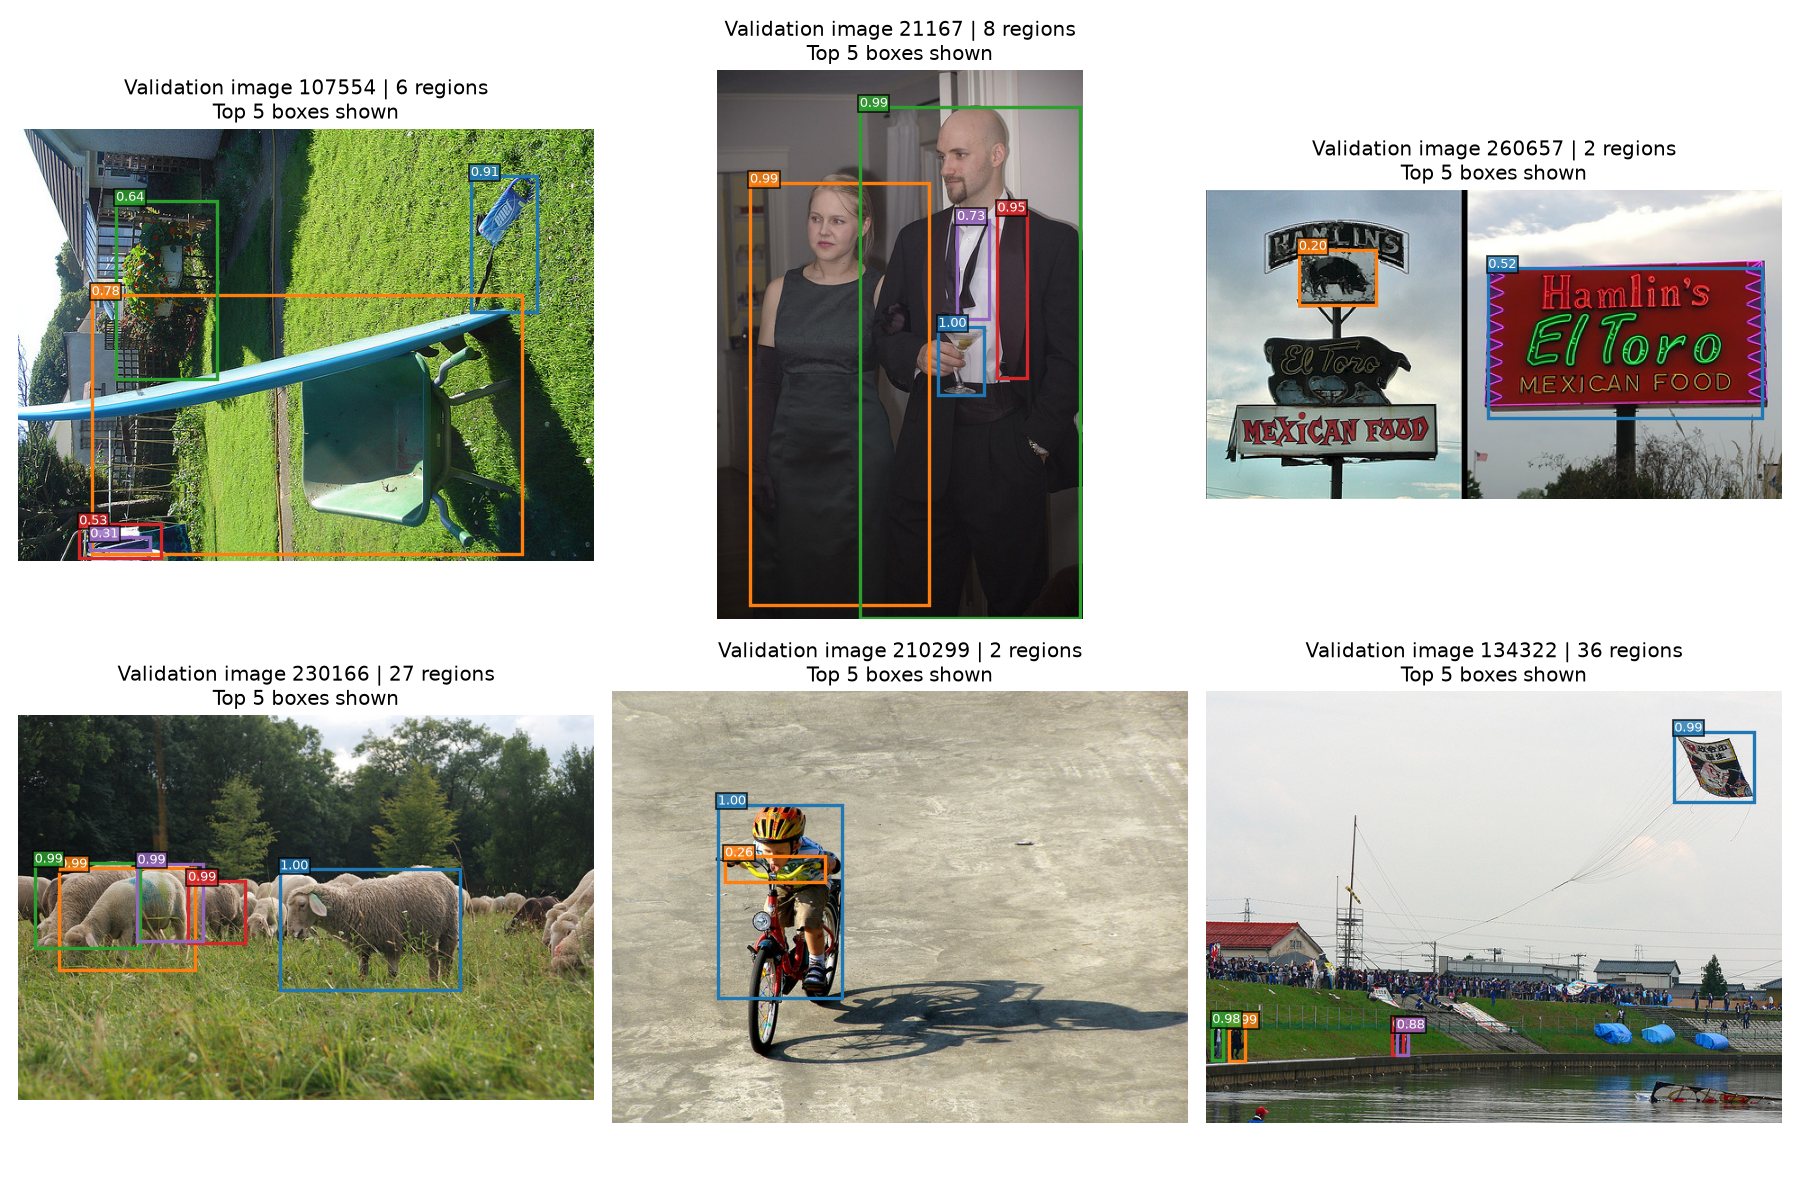


## 1. Imports and settings

All runtime imports are below. Training is started manually by you. Opening this notebook or running it with the default settings starts neither extraction nor training. An exclusive process lock prevents two trainers from writing to the same run.

**How to run:**

1. Open `FinalFusion.ipynb` in the project folder and select the `Python (deep-learning)` kernel.
2. Keep `RUN_FUSION_TRAINING=False` and run all cells once. This loads the saved preparation, defines the model and checks the available caches. It does not train.
3. After all **113,287 train + 5,000 validation** region features are complete and the saved GPU preflight has passed, change `RUN_FUSION_TRAINING=True` in the settings cell and run that settings cell again.
4. Run the training cell in **section 5**. The earlier imports and definition cells must already have run. Keep extraction and new-image inference off.
5. When training stops, run **section 6** to view the saved results. To continue an interrupted run, repeat the setup and the same training cell; it resumes from `last.pt` automatically.

No main fusion training result is claimed in this notebook before you launch it. The existing preflight and throughput diagnostics are separate disposable checks.


In [14]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

import json
import hashlib
import pickle
from pathlib import Path
from collections import Counter, defaultdict
import re
import inspect
import unicodedata
import importlib.metadata as package_metadata
import numpy as np
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.bleu.bleu_scorer import BleuScorer
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.cider.cider_scorer import CiderScorer
import torch
from torch import nn
import copy
import csv
import os
import random
import shutil
import time
from datetime import datetime, timezone
from functools import partial
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.ops import nms
from PIL import Image, ImageOps
import argparse
import ast
import gc
import socket
import sys
import uuid
from contextlib import contextmanager
import matplotlib.pyplot as plt
from torchvision.models import resnet50, ResNet50_Weights
import math

# Imports for the saved greedy/beam comparison.
import textwrap


In [15]:
PROJECT_DIR = Path(r"C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final")
RAW_IMAGE_ROOT = Path(r"C:\Users\askat\Downloads\MSCOCO\coco2017")
REGION_CACHE_DIR = PROJECT_DIR / "cache" / "features" / "fasterrcnn_fusion_expanded_v1"
OUTPUT_ROOT = PROJECT_DIR / "experiments" / "final_fusion_v1"
PREFLIGHT_PATH = OUTPUT_ROOT / "checks" / "gpu_preflight_verification.json"
RUN_NAME = "resnet50_fasterrcnn_transformer_fusion_depth3_seed42"
WARM_START_RUN = "resnet50_transformer_depth_3_seed42"
WARM_START_SHA256 = "bff8c8c6d4a8c54205c3b8502c0ef03938d5dfc2a786379f8157eb9151f40b73"
EXTRACTION_DEADLINE_UTC = "2026-11-15T15:00:00+00:00"
EPOCH_ADMISSION_DEADLINE_UTC = None
HARD_DEADLINE_UTC = None
EXTRACT_REGION_FEATURES = False
ALLOW_WEIGHT_DOWNLOAD = False
RUN_FUSION_TRAINING = False
RUN_NEW_IMAGE = False
NEW_IMAGE_PATH = None
torch.set_num_threads(4)
EXPECTED_CODE_IDENTITY = {
    "models_sha256": "727f7ac7e9659a5ce4be3dc66a30f55e6714b87a3a95162f4d0a2ee72cd6e559",
    "models_cell_ast_sha256": "aac377250db8748d6171a43d3dbb5c353a3b3f3977bb2b4314c71fd527fa9c80",
    "runtime_sha256": "ef8a816949b4c38ed44dd906168c9d54dd22378c1f83a76447ab6bf0c4d4d963",
    "runtime_cell_ast_sha256": "56dbfbfbd94403e338dad3f2a6252836a4507418c27a043d872ca04ed07355b4",
    "region_features_sha256": "880a6dbb01e34ec883cc763585f644709e651884e2f8cd24087ef647ec584929",
    "region_features_cell_ast_sha256": "12dc3ba9b3e79b75aeb6668e7e2bbf32b1fd8904ff892c4d40d29e6a978ae10f",
    "region_cache_sha256": "89a32feb28efaba14b8f42261b6cd660766d92bdb680dafebc773c33075d52c7",
    "region_cache_cell_ast_sha256": "ac087c69248d3c06baa52b1d7cc6cc591a6142af1eb23d3d6176981190790728",
    "model_runtime_implementation_id": "ff10ad1e6734bf520794d80f695041cbb6ec12695bd63d27689ffa9535fba794",
    "region_producer_code_id": "a9980e51d7cbd7567b6f1992cb99784728dc9586be4b86b03553f2b7eb0cb5a5"
}


Training has **no wall-clock deadline by default**: both training deadline settings are `None`, so an old date will not block your later manual launch. It runs for at most **100 epochs**, with early stopping **patience 3**. Optional deadlines can be set to future ISO timestamps with a timezone, for example a UTC time ending in `+00:00`; leave them `None` for a normal run. Keep the same configuration when resuming.

The existing extraction deadline is **15 November 2026, 21:00 Asia/Bishkek (15:00 UTC)**. It only applies when explicitly extracting missing regions. Completed compatible features are reused without checking that date. If extraction is unfinished after that time, set a new extraction deadline before resuming it. Missing required train features pause extraction and prevent training on a smaller set.

Use the existing GPU environment. Extraction starts at batch **1** in float32; caption training and validation use batch **64** with AMP. The caption core uses Adam learning rate **0.0001**; new fusion/cross-attention parameters use **0.0005**. Dropout is **0.3**, gradient clipping **5.0**, maximum **100 epochs**, early stopping **patience 3** on full-validation CIDEr-D. These are one agreed configuration, not a parameter search.


In [16]:
def load_region_prepared_data(project_dir, data_root=None):
    project_dir = Path(project_dir)
    data_root = Path(data_root) if data_root is not None else project_dir / "data" / "coco2017"
    for source in ["train2017", "val2017"]:
        annotation_path = data_root / "annotations" / f"captions_{source}.json"
        if not annotation_path.is_file():
            raise FileNotFoundError(
                f"Missing {annotation_path}. Extract the shared training-data bundle beside "
                "Stage5_Starter.ipynb, or set DATA_ROOT to the bundled annotation folder. "
                "Raw train2017/val2017 JPEGs are required for region extraction."
            )
    cache = project_dir / "cache"
    required = [
        "splits.json",
        "prepared.pkl",
        "text_report.json",
        "vocab.json",
        "image_audit.json",
        "test_captions.json",
    ]
    missing = [name for name in required if not (cache / name).is_file()]
    if missing:
        raise FileNotFoundError(
            f"Missing prepared files: {missing}. Extract the shared training-data bundle into PROJECT_DIR. "
            "Do not recreate the split or vocabulary for this comparison."
        )

    # Load saved preparation results, then verify their versions agree.
    split_bytes = (cache / "splits.json").read_bytes()
    vocab_bytes = (cache / "vocab.json").read_bytes()
    prepared_bytes = (cache / "prepared.pkl").read_bytes()
    split_file = json.loads(split_bytes)
    vocab = json.loads(vocab_bytes)
    report = json.loads((cache / "text_report.json").read_text(encoding="utf-8"))
    audit = json.loads((cache / "image_audit.json").read_text(encoding="utf-8"))

    prepared_sha = hashlib.sha256(prepared_bytes).hexdigest()
    assert (
        prepared_sha == report["cache_sha256"]
    ), "Prepared caption cache changed. Rerun preparation."
    prepared = pickle.loads(
        prepared_bytes
    )  # This is our own cache, checked against its saved hash.
    del prepared_bytes

    split_ids = split_file["ids"]
    sources = split_file["feature_sources"]
    assert set(split_ids) == {"train", "val", "test"}
    assert sources == {
        "train": "train2017",
        "val": "val2017",
        "test": "train2017",
    }, "Use the saved labeled split, not official test2017."
    payload = {"config": split_file["config"], "ids": split_ids, "feature_sources": sources}
    split_id = hashlib.sha256(
        json.dumps(payload, sort_keys=True, separators=(",", ":")).encode()
    ).hexdigest()
    assert split_id == split_file["split_id"] == prepared["config"]["split_id"] == vocab["split_id"]

    source_id = split_file["config"]["source_id"]
    assert source_id == prepared["config"]["source_id"] == vocab["source_id"] == audit["source_id"]
    assert prepared["config"] == report["config"]
    assert audit["complete"] and not audit["image_errors"] and not audit["metadata_errors"]
    assert (
        prepared["token_to_id"] == vocab["token_to_id"]
        and prepared["id_to_token"] == vocab["id_to_token"]
    )
    assert vocab["token_to_id"] == {word: index for index, word in enumerate(vocab["id_to_token"])}

    ids = {
        name: vocab["token_to_id"][token]
        for name, token in [
            ("pad", "<pad>"),
            ("unk", "<unk>"),
            ("start", "<start>"),
            ("end", "<end>"),
        ]
    }
    assert len(set(ids.values())) == 4

    # One photograph and its exact duplicates must stay in one labeled split.
    sets = {name: set(values) for name, values in split_ids.items()}
    for name, values in split_ids.items():
        assert values == sorted(sets[name]) and values, f"Invalid or repeated IDs in {name}."
    for left, right in [("train", "val"), ("train", "test"), ("val", "test")]:
        assert not sets[left] & sets[right], f"Image overlap: {left}/{right}."
    assert len(sets["test"]) == split_file["config"]["holdout_size"]

    owners = {
        (sources[name], image_id): name for name, values in sets.items() for image_id in values
    }
    for group in audit["pixel_duplicates"] + audit["file_duplicates"]:
        assigned = {owners[tuple(item)] for item in group if tuple(item) in owners}
        assert len(assigned) <= 1, "Exact duplicate photos cross the labeled splits."

    # Keep the original human references for evaluation.
    raw_by_source = {}
    source_image_ids = {}
    annotation_hashes = {}

    for source in ["train2017", "val2017"]:
        annotation_bytes = (data_root / "annotations" / f"captions_{source}.json").read_bytes()
        annotation_hashes[source] = hashlib.sha256(annotation_bytes).hexdigest()
        annotation = json.loads(annotation_bytes)
        source_image_ids[source] = sorted(row["id"] for row in annotation["images"])
        assert len(source_image_ids[source]) == len(set(source_image_ids[source]))

        raw_by_source[source] = defaultdict(list)
        for row in annotation["annotations"]:
            assert (
                isinstance(row["caption"], str) and row["caption"].strip()
            ), "Empty human reference."
            raw_by_source[source][row["image_id"]].append(row["caption"])
        assert set(raw_by_source[source]) == set(
            source_image_ids[source]
        ), "Missing human descriptions."

        if source == "train2017":
            saved_test = json.loads((cache / "test_captions.json").read_text(encoding="utf-8"))
            assert saved_test["split_id"] == split_id
            expected_test = [
                row for row in annotation["annotations"] if row["image_id"] in sets["test"]
            ]
            assert (
                saved_test["annotations"] == expected_test
            ), "Saved test references differ from the original human captions."
        del annotation_bytes, annotation

    assert sets["train"] | sets["test"] == set(source_image_ids["train2017"])
    assert sets["val"] == set(source_image_ids["val2017"])

    references = {
        name: {image_id: raw_by_source[sources[name]][image_id] for image_id in values}
        for name, values in split_ids.items()
    }
    tokens = {name: prepared[f"{name}_tokens"] for name in split_ids}
    for name, values in tokens.items():
        assert sorted(values) == split_ids[name]
        assert all(
            rows and all(row for row in rows) for rows in values.values()
        ), "Empty tokenized caption."
        if name != "train":
            assert all(
                len(rows) == len(references[name][image_id]) for image_id, rows in values.items()
            ), "Evaluation references were dropped."

    # Test and validation captions must not contribute to the vocabulary.
    train_counts = Counter(
        token for rows in tokens["train"].values() for row in rows for token in row
    )
    assert train_counts == prepared["train_counts"]
    settings = prepared["config"]["settings"]
    regular = [
        token
        for token, count in sorted(train_counts.items(), key=lambda row: (-row[1], row[0]))
        if count >= settings["min_frequency"]
    ][: settings["max_vocab_tokens"]]
    assert (
        vocab["id_to_token"] == settings["special_tokens"] + regular
    ), "Vocabulary must be fitted on training captions only."

    data = {
        "project_dir": project_dir,
        "data_root": data_root,
        "split_ids": split_ids,
        "feature_sources": sources,
        "tokens": tokens,
        "references": references,
        "source_image_ids": source_image_ids,
        "token_to_id": vocab["token_to_id"],
        "id_to_token": vocab["id_to_token"],
        "ids": ids,
        "max_content_tokens": prepared["config"]["max_content_tokens"],
        "text_settings": settings,
        "provenance": {
            "source_id": source_id,
            "split_id": split_id,
            "prepared_sha256": prepared_sha,
            "vocab_sha256": hashlib.sha256(vocab_bytes).hexdigest(),
            "splits_sha256": hashlib.sha256(split_bytes).hexdigest(),
            "annotations_sha256": annotation_hashes,
        },
    }

    print(
        "Verified disjoint labeled splits:",
        {name: len(values) for name, values in split_ids.items()},
    )
    print("Vocabulary:", len(data["id_to_token"]), "| special IDs:", ids)
    return data

In [17]:
class MetricEvaluator:
    def __init__(self, settings):
        version = package_metadata.version("pycocoevalcap")
        if version != "1.2":
            raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
        self.token_pattern = settings["token_pattern"]
        re.compile(self.token_pattern)
        self.metadata = {
            "package": "pycocoevalcap",
            "version": version,
            "bleu": {
                "implementation": "Bleu(4)",
                "aggregation": "corpus",
                "scale": "0..1; no multiplication by 100",
            },
            "cider_d": {
                "implementation": "Cider(n=4,sigma=6.0)",
                "ngrams": 4,
                "sigma": 6.0,
                "scale": "native score, including the implementation's factor 10; no extra multiplication",
                "document_frequency": "all reference sets in the evaluated split",
            },
            "tokenization": {
                "name": "project_regex_v1",
                "normalization": "NFKC,lowercase,smart quotes,whitespace",
                "token_pattern": self.token_pattern,
                "reference_vocabulary_mapping": False,
                "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
            },
            "source_sha256": {
                name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                for name, cls in [
                    ("bleu", Bleu),
                    ("bleu_scorer", BleuScorer),
                    ("cider", Cider),
                    ("cider_scorer", CiderScorer),
                ]
            },
        }

    def tokenize(self, text):
        text = unicodedata.normalize("NFKC", text).lower()
        text = text.translate(
            str.maketrans(
                {
                    "\u2018": "'",
                    "\u2019": "'",
                    "\u02bc": "'",
                    "\u201c": '"',
                    "\u201d": '"',
                    "\u200b": " ",
                    "\ufeff": " ",
                }
            )
        )
        text = " ".join(text.split())
        return " ".join(re.findall(self.token_pattern, text))

    def score(self, records, expected_ids=None):
        # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
        if len(records) < 2:
            raise ValueError("CIDEr-D needs a corpus with at least two images.")
        gts = {}
        res = {}
        for item in records:
            image_id = int(item["image_id"])
            if image_id in gts:
                raise ValueError(f"Duplicate prediction for image {image_id}")
            references = item["references"]
            if not isinstance(references, list) or not references:
                raise ValueError(f"Missing human references for image {image_id}")
            if not all(isinstance(text, str) and text.strip() for text in references):
                raise ValueError(f"Empty or invalid human reference for image {image_id}")
            if not isinstance(item["prediction"], str):
                raise TypeError("Each prediction must be a string.")
            gts[image_id] = [self.tokenize(text) for text in references]
            if not all(gts[image_id]):
                raise ValueError(f"A reference has no tokens for image {image_id}")
            res[image_id] = [self.tokenize(item["prediction"])]
        if expected_ids is not None:
            expected = [int(image_id) for image_id in expected_ids]
            if len(expected) != len(set(expected)) or set(gts) != set(expected):
                raise ValueError("Predictions do not cover exactly the requested evaluation split.")
        bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
        cider_d, _ = Cider(n=4, sigma=6.0).compute_score(gts, res)
        scores = {"bleu1": float(bleu[0]), "bleu4": float(bleu[3]), "cider_d": float(cider_d)}
        if not all(np.isfinite(value) for value in scores.values()):
            raise ValueError("The metric implementation returned a non-finite score.")
        return scores


def check_metrics(evaluator):
    # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
    sentences = [
        "A red bus drives down the road.",
        "Two cats sleep on the green sofa.",
        "A woman holds a yellow umbrella.",
    ]
    records = [
        {"image_id": index, "prediction": text, "references": [text, text]}
        for index, text in enumerate(sentences)
    ]
    exact = evaluator.score(records, expected_ids=range(len(records)))
    assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
    assert abs(exact["cider_d"] - 10) < 1e-6
    unrelated = [
        {**row, "prediction": "unrelated vocabulary never matches anything"} for row in records
    ]
    poor = evaluator.score(unrelated)
    assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
    empty = evaluator.score([{**row, "prediction": ""} for row in records])
    assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
    # These are library corpus scores, not sentence scores averaged by our code.
    gts = {
        row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
    }
    res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
    direct_bleu, _ = Bleu(4).compute_score(gts, res, verbose=0)
    direct_cider, _ = Cider(n=4, sigma=6.0).compute_score(gts, res)
    assert exact == {
        "bleu1": float(direct_bleu[0]),
        "bleu4": float(direct_bleu[3]),
        "cider_d": float(direct_cider),
    }
    try:
        evaluator.score(records, expected_ids=[0, 1, 99])
    except ValueError:
        pass
    else:
        raise AssertionError("Incomplete evaluation corpus was accepted.")
    print(
        "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
    )
    return {"exact": exact, "unrelated": poor, "empty_predictions": empty}

In [18]:
data = load_region_prepared_data(PROJECT_DIR, RAW_IMAGE_ROOT)
evaluator = MetricEvaluator(data["text_settings"])
print("Saved split sizes:", {name:len(ids) for name,ids in data["split_ids"].items()})
print("Vocabulary:", len(data["id_to_token"]), "| special IDs:", data["ids"])


Verified disjoint labeled splits: {'train': 113287, 'val': 5000, 'test': 5000}
Vocabulary: 10004 | special IDs: {'pad': 0, 'unk': 1, 'start': 2, 'end': 3}
Saved split sizes: {'train': 113287, 'val': 5000, 'test': 5000}
Vocabulary: 10004 | special IDs: {'pad': 0, 'unk': 1, 'start': 2, 'end': 3}


## 2. Frozen image representations

The existing ResNet50 cache supplies two views of each image: the exact **float32 global vector [2048]** used by the trained prefix model, and the **float16 spatial grid [49,2048]**. Both retain the earlier 224×224 proportional resize+padding preprocessing. Reading the exact global vector avoids changing the initial prefix through spatial-cache rounding.

The detector is **torchvision Faster R-CNN ResNet50-FPN, COCO_V1**, frozen and in eval mode. It receives original RGB photographs with its own 800/1333 resize and normalization. Selected final boxes are re-pooled through the same FPN and box head, producing up to **36 vectors of width1024**. Selection uses score≥0.2, additional class-agnostic NMS0.5 and top36. If none remain, a marked full-image ROI gives one valid region. Cached normalized xyxy boxes provide region positions. Predicted object names/classes are not decoder inputs.

Validation regions are extracted first, completely. Train extraction follows a seed42 random order through **all 113,287 saved train images**. The earlier **40,000-image pilot cache** is reused through a separately audited migration into `fasterrcnn_fusion_expanded_v1`; it is not an accepted training subset. That migration checks the original rows and preserves their provenance before copying them into the larger cache. Remaining features continue from those saved rows. The original split is never rewritten, and no test image is extracted for this run.


In [19]:
REGION_TORCH_PIN = "2.13.0"
REGION_TORCHVISION_PIN = "0.28.0"
REGION_WEIGHT_NAME = "FasterRCNN_ResNet50_FPN_Weights.COCO_V1"
REGION_CACHE_VERSION = "fasterrcnn_resnet50_fpn_coco_v1_regions_v1"
REGION_DIM = 1024


def region_feature_contract(max_regions=36, score_threshold=0.2, nms_iou=0.5):
    return {
        "version": REGION_CACHE_VERSION,
        "detector": "torchvision.models.detection.fasterrcnn_resnet50_fpn",
        "weights": REGION_WEIGHT_NAME,
        "torch": REGION_TORCH_PIN,
        "torchvision": REGION_TORCHVISION_PIN,
        "input": "EXIF-transposed RGB; ToTensor float32 in [0,1]; original aspect ratio and size",
        "detector_transform": {
            "min_size": 800, "max_size": 1333, "size_divisible": 32,
            "image_mean": [0.485, 0.456, 0.406], "image_std": [0.229, 0.224, 0.225],
        },
        "compute_dtype": "float32; autocast disabled",
        "cnn_frozen": True,
        "detector_eval": True,
        "detector_score_threshold": 0.05,
        "detector_class_nms_iou": 0.5,
        "detector_max_detections": 100,
        "rpn_pre_nms_top_n_test": 1000,
        "rpn_post_nms_top_n_test": 1000,
        "rpn_nms_iou": 0.7,
        "selection": "Final class-NMS detections, score filter, class-agnostic NMS, descending score, top K",
        "score_threshold": float(score_threshold),
        "class_agnostic_nms_iou": float(nms_iou),
        "max_regions": int(max_regions),
        "feature_dimension": REGION_DIM,
        "feature_layer": "box_roi_pool + TwoMLPHead.fc6/ReLU/fc7/ReLU, rerun on selected FINAL boxes",
        "feature_storage_dtype": "float16 after finite/overflow validation; compute and returned features remain float32",
        "boxes": "xyxy in original EXIF-transposed RGB pixel coordinates; zero padding",
        "boxes_normalized": "xyxy divided by original [width,height,width,height]; reporting only",
        "mask": "bool; True means a real selected region, including the full-image fallback",
        "padding": "zero features/boxes/scores, label=-1, mask=False",
        "fallback": "If no boxes remain, ROI-pool the full transformed image; valid count=1, score=0, label=-1, fallback=True",
        "decoder_inputs": "visual features and valid-region mask only; no predicted class labels, scores or object words",
        "test_exposure_note": "COCO detector pretraining may include train2017 images used by the captioning holdout; do not claim an unseen-image encoder test.",
    }


def build_frozen_region_detector(device="cpu", allow_download=False):
    """No model is constructed or downloaded until this function is explicitly called."""
    if torch.__version__.split("+")[0] != REGION_TORCH_PIN or torchvision.__version__.split("+")[0] != REGION_TORCHVISION_PIN:
        raise RuntimeError(f"Use torch=={REGION_TORCH_PIN} and torchvision=={REGION_TORCHVISION_PIN} for this pinned region contract.")
    weights = FasterRCNN_ResNet50_FPN_Weights.COCO_V1
    filename = weights.url.rsplit("/", 1)[-1]
    checkpoint = Path(torch.hub.get_dir()) / "checkpoints" / filename
    if not checkpoint.is_file() and not allow_download:
        raise FileNotFoundError(f"Missing {checkpoint}. Downloading is disabled; set allow_download=True only when ready to obtain the pretrained detector.")
    if checkpoint.is_file():
        digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
        assert digest.startswith("258fb6c6"), "Cached detector weights do not match COCO_V1."
    detector = fasterrcnn_resnet50_fpn(
        weights=weights, weights_backbone=None, progress=True,
        min_size=800, max_size=1333,
        box_score_thresh=0.05, box_nms_thresh=0.5, box_detections_per_img=100,
        rpn_pre_nms_top_n_test=1000, rpn_post_nms_top_n_test=1000, rpn_nms_thresh=0.7,
    )
    detector = detector.to(device=torch.device(device), dtype=torch.float32).requires_grad_(False).eval()
    assert detector.roi_heads.box_head.fc7.out_features == REGION_DIM
    digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    assert digest.startswith("258fb6c6")
    detector.region_feature_metadata = {**region_feature_contract(), "weights_sha256": digest,
                                        "device": str(torch.device(device))}
    return detector


def load_region_image(path):
    """Do not apply the 224x224 classification resize, padding or normalization here."""
    with Image.open(path) as image:
        return transforms.ToTensor()(ImageOps.exif_transpose(image).convert("RGB"))


def _select_region_boxes(detection, transformed_size, max_regions, score_threshold, nms_iou):
    boxes, scores, labels = detection["boxes"], detection["scores"], detection["labels"]
    assert boxes.ndim == 2 and boxes.shape[1] == 4
    assert scores.shape == labels.shape == (len(boxes),)
    assert torch.isfinite(boxes).all() and torch.isfinite(scores).all()
    assert torch.all((scores >= 0) & (scores <= 1))
    if len(boxes):
        assert torch.all(boxes[:, 2:] > boxes[:, :2]) and torch.all(labels > 0)
    keep = scores >= score_threshold
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    if len(boxes):
        order = torch.argsort(scores, descending=True, stable=True)
        boxes, scores, labels = boxes[order], scores[order], labels[order]
        keep = nms(boxes, scores, nms_iou)[:max_regions]
        return {"boxes": boxes[keep], "scores": scores[keep], "labels": labels[keep], "fallback": False}
    height, width = transformed_size
    return {
        "boxes": boxes.new_tensor([[0, 0, width, height]]),
        "scores": scores.new_zeros(1),
        "labels": torch.full((1,), -1, dtype=torch.long, device=boxes.device),
        "fallback": True,
    }


@torch.no_grad()
def extract_region_batch(detector, images, max_regions=36, score_threshold=0.2, nms_iou=0.5):
    """Return one CPU record per image; no files, caches or downloads are written."""
    if not isinstance(max_regions, int) or isinstance(max_regions, bool) or max_regions < 1:
        raise ValueError("max_regions must be a positive integer.")
    if not 0 <= score_threshold <= 1 or not 0 <= nms_iou <= 1:
        raise ValueError("score_threshold and nms_iou must be in [0,1].")
    if not isinstance(images, (list, tuple)) or not images:
        raise ValueError("Pass a nonempty list of original RGB image tensors.")
    if detector.training or any(parameter.requires_grad for parameter in detector.parameters()):
        raise ValueError("The detector must be frozen and in eval() mode.")
    device = next(detector.parameters()).device
    original_sizes = []
    prepared_images = []
    for image in images:
        if image.ndim != 3 or image.shape[0] != 3 or min(image.shape[-2:]) < 1:
            raise ValueError("Each image must have shape [3,H,W].")
        if not image.is_floating_point() or not torch.isfinite(image).all() or image.min() < 0 or image.max() > 1:
            raise ValueError("Use unnormalized RGB float tensors in [0,1].")
        original_sizes.append(tuple(image.shape[-2:]))
        prepared_images.append(image.to(device=device, dtype=torch.float32))

    # All detector/ROI computation stays float32, even inside a caller's AMP context.
    with torch.autocast(device_type=device.type, enabled=False):
        transformed, _ = detector.transform(prepared_images, None)
        fpn_features = detector.backbone(transformed.tensors)
        if isinstance(fpn_features, torch.Tensor):
            fpn_features = {"0": fpn_features}
        proposals, _ = detector.rpn(transformed, fpn_features, None)
        detections, _ = detector.roi_heads(fpn_features, proposals, transformed.image_sizes, None)
        assert len(detections) == len(images)
        selected = [_select_region_boxes(detection, size, max_regions, score_threshold, nms_iou)
                    for detection, size in zip(detections, transformed.image_sizes)]
        selected_boxes = [item["boxes"] for item in selected]

        # NMS/regression changes the proposal rows. Re-pool FINAL selected boxes;
        # never index the earlier proposal feature matrix using final detection IDs.
        roi_maps = detector.roi_heads.box_roi_pool(fpn_features, selected_boxes, transformed.image_sizes)
        roi_vectors = detector.roi_heads.box_head(roi_maps)
        counts = [len(boxes) for boxes in selected_boxes]
        assert roi_vectors.shape == (sum(counts), REGION_DIM) and roi_vectors.dtype == torch.float32
        assert torch.isfinite(roi_vectors).all()
        grouped_vectors = roi_vectors.split(counts, dim=0)

    records = []
    for vectors, selection, original_size, transformed_size in zip(grouped_vectors, selected, original_sizes, transformed.image_sizes):
        count = len(vectors)
        original_height, original_width = original_size
        transformed_height, transformed_width = transformed_size
        scale = selection["boxes"].new_tensor([original_width / transformed_width, original_height / transformed_height,
                                              original_width / transformed_width, original_height / transformed_height])
        boxes = selection["boxes"] * scale  # Exactly one transformed -> original rescaling.
        boxes[:, 0::2].clamp_(min=0, max=original_width)
        boxes[:, 1::2].clamp_(min=0, max=original_height)
        normalized = boxes / boxes.new_tensor([original_width, original_height, original_width, original_height])
        record = {
            "features": torch.zeros(max_regions, REGION_DIM, dtype=torch.float32),
            "boxes": torch.zeros(max_regions, 4, dtype=torch.float32),
            "boxes_normalized": torch.zeros(max_regions, 4, dtype=torch.float32),
            "scores": torch.zeros(max_regions, dtype=torch.float32),
            "labels": torch.full((max_regions,), -1, dtype=torch.long),
            "mask": torch.zeros(max_regions, dtype=torch.bool),
            "num_regions": count, "fallback": selection["fallback"],
            "original_size": original_size, "transformed_size": tuple(transformed_size),
        }
        record["features"][:count] = vectors.cpu()
        record["boxes"][:count] = boxes.cpu()
        record["boxes_normalized"][:count] = normalized.cpu()
        record["scores"][:count] = selection["scores"].cpu()
        record["labels"][:count] = selection["labels"].cpu()
        record["mask"][:count] = True
        assert 1 <= count <= max_regions and int(record["mask"].sum()) == count
        assert torch.isfinite(record["features"].to(torch.float16)).all(), "ROI features overflow float16 storage."
        records.append(record)
    return records

In [20]:
"""Frozen detector cache: complete validation first, then a timeboxed train prefix."""




FUSION_REGION_VERSION = "fasterrcnn_fusion_partial_v1"


def _fusion_utc():
    return datetime.now(timezone.utc)


def _fusion_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, indent=2)
        stream.flush()
        os.fsync(stream.fileno())
    for attempt in range(10):
        try:
            temporary.replace(path)
            return
        except PermissionError:
            if attempt == 9:
                raise
            time.sleep(0.2)


def _fusion_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


def _fusion_file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _fusion_specs(count):
    return {
        "features": ((count, 36, 1024), np.dtype("float16")),
        "mask": ((count, 36), np.dtype("bool")),
        "normalized_boxes": ((count, 36, 4), np.dtype("float32")),
        "boxes": ((count, 36, 4), np.dtype("float32")),
        "scores": ((count, 36), np.dtype("float32")),
        "labels": ((count, 36), np.dtype("int64")),
        "num_regions": ((count,), np.dtype("uint8")),
        "fallback": ((count,), np.dtype("bool")),
    }


def _fusion_paths(directory, source):
    directory = Path(directory)
    return {
        "partial": {name: directory / f"{source}_{name}.partial.npy" for name in _fusion_specs(1)},
        "final": {name: directory / f"{source}_{name}.npy" for name in _fusion_specs(1)},
        "ids": directory / f"{source}_image_ids.json",
        "progress": directory / f"{source}_progress.json",
        "meta": directory / f"{source}_meta.json",
    }


def _fusion_close(arrays):
    for value in arrays.values():
        mapping = getattr(value, "_mmap", None)
        if mapping is not None:
            mapping.close()


def _fusion_validate_chunk(arrays):
    count = arrays["num_regions"]
    mask = arrays["mask"]
    assert np.all((count >= 1) & (count <= 36))
    assert np.array_equal(mask, np.arange(36)[None, :] < count[:, None])
    for name in ["features", "boxes", "normalized_boxes", "scores"]:
        assert np.isfinite(arrays[name]).all(), f"Nonfinite {name}."
        assert np.all(arrays[name][~mask] == 0), f"Invalid {name} padding."
    assert np.all(arrays["labels"][~mask] == -1)
    normalized = arrays["normalized_boxes"][mask]
    boxes = arrays["boxes"][mask]
    assert np.all(normalized >= 0) and np.all(normalized <= 1)
    assert np.all(normalized[:, 2:] > normalized[:, :2])
    assert np.all(boxes >= 0) and np.all(boxes[:, 2:] > boxes[:, :2])
    assert np.all((arrays["scores"][mask] >= 0) & (arrays["scores"][mask] <= 1))
    fallback = arrays["fallback"]
    assert np.all(count[fallback] == 1)
    assert np.all(arrays["labels"][fallback, 0] == -1)
    assert np.all(arrays["scores"][fallback, 0] == 0)
    normal = mask & ~fallback[:, None]
    assert np.all(arrays["labels"][normal] > 0)
    assert np.all(arrays["scores"][normal] >= 0.2)


def _fusion_pack(records):
    arrays = {}
    for name, (shape, dtype) in _fusion_specs(len(records)).items():
        key = "boxes_normalized" if name == "normalized_boxes" else name
        values = [row[key] for row in records]
        if isinstance(values[0], torch.Tensor):
            values = torch.stack(values).detach().cpu().numpy()
        arrays[name] = np.asarray(values, dtype=dtype)
        assert arrays[name].shape == shape
    _fusion_validate_chunk(arrays)
    return arrays


def _fusion_annotation_records(data, source, ordered_ids, raw_root):
    path = Path(data["data_root"]) / "annotations" / f"captions_{source}.json"
    assert _fusion_file_sha(path) == data["provenance"]["annotations_sha256"][source]
    payload = json.loads(path.read_text(encoding="utf-8"))
    images = {row["id"]: row for row in payload["images"]}
    assert set(ordered_ids) <= set(images)
    directory = Path(raw_root) / source
    if not directory.is_dir():
        raise FileNotFoundError(f"Missing original JPEG folder: {directory}")
    with os.scandir(directory) as entries:
        available = {entry.name for entry in entries if entry.is_file()}
    rows = [images[image_id] for image_id in ordered_ids]
    missing = []
    for row in rows:
        assert Path(row["file_name"]).name == row["file_name"]
        if row["file_name"] not in available:
            missing.append(row["file_name"])
    if missing:
        raise FileNotFoundError(f"Missing {len(missing)} original {source} images, e.g. {missing[:3]}")
    return rows


def _fusion_finish_source(directory, source, ordered_ids, progress, config):
    paths = _fusion_paths(directory, source)
    count = progress["processed"]
    assert count > 0 and count <= len(ordered_ids)
    selected_ids = ordered_ids[:count]
    start = time.perf_counter()
    source_arrays, final_arrays = {}, {}
    try:
        for name, (shape, dtype) in _fusion_specs(len(ordered_ids)).items():
            source_arrays[name] = np.load(paths["partial"][name], mmap_mode="r", allow_pickle=False)
            assert source_arrays[name].shape == shape and source_arrays[name].dtype == dtype
        for name, (shape, dtype) in _fusion_specs(count).items():
            # Repeating a failed compaction is safe: the complete metadata is written last.
            final_arrays[name] = np.lib.format.open_memmap(paths["final"][name], mode="w+", dtype=dtype, shape=shape)
        for first in range(0, count, 256):
            last = min(first + 256, count)
            chunk = {name: values[first:last] for name, values in source_arrays.items()}
            _fusion_validate_chunk(chunk)
            for name, values in final_arrays.items():
                values[first:last] = chunk[name]
        for values in final_arrays.values():
            values.flush()
        counts = np.asarray(source_arrays["num_regions"][:count])
        statistics = {
            "images": count, "regions_min": int(counts.min()), "regions_mean": float(counts.mean()),
            "regions_max": int(counts.max()), "valid_regions": int(counts.sum(dtype=np.int64)),
            "fallback_images": int(source_arrays["fallback"][:count].sum(dtype=np.int64)),
            "fallback_rate": float(source_arrays["fallback"][:count].mean()),
            "all_rows_finite_and_masks_valid": True,
        }
    finally:
        _fusion_close(final_arrays)
        _fusion_close(source_arrays)
    hashes = {name: _fusion_file_sha(path) for name, path in paths["final"].items()}
    _fusion_json(paths["ids"], selected_ids)
    compact_seconds = time.perf_counter() - start
    metadata = {
        **progress, "status": "complete", "complete": True, "config": config,
        "cache_key": _fusion_hash(config), "source": source,
        "completed_utc": _fusion_utc().isoformat(), "shape": [count, 36, 1024],
        "actual_ids_sha256": _fusion_hash(selected_ids), "statistics": statistics,
        "compaction_and_hash_seconds": compact_seconds,
        "elapsed_seconds": progress["elapsed_seconds"] + compact_seconds,
        "arrays": {name: {"shape": list(shape), "dtype": str(dtype), "sha256": hashes[name],
                          "bytes": paths["final"][name].stat().st_size}
                   for name, (shape, dtype) in _fusion_specs(count).items()},
        "temporary_files": "Capacity-sized .partial.npy files retained for recovery; final exact-size .npy files are used for training.",
    }
    _fusion_json(paths["meta"], metadata)
    return metadata


def _fusion_extract_source(data, detector, directory, raw_root, source, ordered_ids, deadline, batch_size, min_train_images, config):
    paths = _fusion_paths(directory, source)
    key = _fusion_hash(config)
    if paths["meta"].exists():
        metadata = json.loads(paths["meta"].read_text(encoding="utf-8"))
        assert metadata["complete"] and metadata["cache_key"] == key
        return metadata
    prior = {}
    if paths["progress"].exists():
        prior = json.loads(paths["progress"].read_text(encoding="utf-8"))
        assert prior["cache_key"] == key and prior["source"] == source
        assert prior["planned_ids_sha256"] == _fusion_hash(ordered_ids)
    else:
        if any(path.exists() for group in [paths["partial"], paths["final"]] for path in group.values()):
            raise ValueError("Arrays exist without matching progress metadata; use a new cache directory.")
    offset = int(prior.get("processed", 0))
    assert 0 <= offset <= len(ordered_ids)
    if prior.get("status") == "ready":
        return _fusion_finish_source(directory, source, ordered_ids, prior, config)
    records = _fusion_annotation_records(data, source, ordered_ids, raw_root)
    device = next(detector.parameters()).device
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    start = time.perf_counter()
    previous_seconds = float(prior.get("elapsed_seconds", 0))
    common = {"source": source, "cache_key": key, "planned_count": len(ordered_ids),
              "planned_ids_sha256": _fusion_hash(ordered_ids), "config": config,
              "batch_size": batch_size, "resume_from_row": offset,
              "timing": "Active allocation, JPEG reads, detector computation, writes, final validation, compaction and hashes; pauses excluded.",
              "requested_deadline_utc": deadline.isoformat()}
    arrays = {}
    _fusion_json(paths["progress"], {**common, "status": "initializing", "processed": offset,
                                    "elapsed_seconds": previous_seconds, "complete": False})
    try:
        for name, (shape, dtype) in _fusion_specs(len(ordered_ids)).items():
            path = paths["partial"][name]
            if path.exists():
                arrays[name] = np.load(path, mmap_mode="r+", allow_pickle=False)
                assert arrays[name].shape == shape and arrays[name].dtype == dtype
            else:
                assert offset == 0, f"Missing a committed partial array: {name}"
                arrays[name] = np.lib.format.open_memmap(path, mode="w+", dtype=dtype, shape=shape)

        def checkpoint(status, stop_reason=None):
            for array in arrays.values():
                array.flush()
            if device.type == "cuda":
                torch.cuda.synchronize(device)
            progress = {**common, "status": status, "complete": False, "processed": offset,
                        "elapsed_seconds": previous_seconds + time.perf_counter() - start,
                        "updated_utc": _fusion_utc().isoformat(), "stop_reason": stop_reason}
            _fusion_json(paths["progress"], progress)
            return progress

        try:
            last_print = time.perf_counter()
            reason = "planned_source_complete"
            for first in range(offset, len(ordered_ids), batch_size):
                if _fusion_utc() >= deadline:
                    if source == "val2017" or offset < min_train_images:
                        checkpoint("paused", "deadline_before_required_minimum")
                        raise TimeoutError(f"Deadline reached: {source} has {offset}/{len(ordered_ids)} images. Extend the extraction deadline explicitly to finish required validation/minimum train.")
                    reason = "deadline_train_prefix"
                    break
                last = min(first + batch_size, len(ordered_ids))
                images = []
                for row in records[first:last]:
                    image = load_region_image(Path(raw_root) / source / row["file_name"])
                    assert sorted(image.shape[-2:]) == sorted([row["height"], row["width"]]), "Use original JPEG dimensions, not resized previews."
                    images.append(image)
                output = extract_region_batch(detector, images, max_regions=36, score_threshold=0.2, nms_iou=0.5)
                assert len(output) == last - first
                chunk = _fusion_pack(output)
                for name, array in arrays.items():
                    array[first:last] = chunk[name]
                offset = last
                if time.perf_counter() - last_print >= 20 or offset == len(ordered_ids):
                    progress = checkpoint("running")
                    speed = (offset - common["resume_from_row"]) / max(time.perf_counter() - start, 1e-9)
                    remaining = (len(ordered_ids) - offset) / max(speed, 1e-9)
                    print(f"ROI {source}: {offset:,}/{len(ordered_ids):,} | {speed:.2f} img/s | active {progress['elapsed_seconds']/60:.1f} min | full-source ETA {remaining/60:.1f} min", flush=True)
                    last_print = time.perf_counter()
            assert offset > 0
            if source == "val2017":
                assert offset == len(ordered_ids), "Validation must be complete."
            else:
                assert offset >= min(min_train_images, len(ordered_ids))
            progress = checkpoint("ready", reason)
        except BaseException:
            checkpoint("paused", "interrupted_or_failed")
            raise
    finally:
        _fusion_close(arrays)
    return _fusion_finish_source(directory, source, ordered_ids, progress, config)


def load_fusion_region_cache(data, cache_dir, expected_cache_key=None, producer_code_id=None):
    directory = Path(cache_dir)
    plan_path = directory / "cache_plan.json"
    if not plan_path.exists():
        raise FileNotFoundError("Missing fusion-region cache plan.")
    plan = json.loads(plan_path.read_text(encoding="utf-8"))
    config = plan["config"]
    key = _fusion_hash(config)
    assert key == plan["cache_key"]
    assert config["source_id"] == data["provenance"]["source_id"]
    assert config["split_id"] == data["provenance"]["split_id"]
    assert config["annotations_sha256"] == data["provenance"]["annotations_sha256"]
    if expected_cache_key is not None:
        assert key == expected_cache_key
    if producer_code_id is not None:
        assert config["producer_code_id"] == producer_code_id
    for name, value in region_feature_contract().items():
        assert config["detector_contract"][name] == value
    files = {}
    for source in ["val2017", "train2017"]:
        paths = _fusion_paths(directory, source)
        if not paths["meta"].is_file():
            raise FileNotFoundError(f"Incomplete fusion cache: {source}")
        metadata = json.loads(paths["meta"].read_text(encoding="utf-8"))
        assert metadata["complete"] and metadata["cache_key"] == key
        ids = json.loads(paths["ids"].read_text(encoding="utf-8"))
        assert ids and len(ids) == len(set(ids)) and _fusion_hash(ids) == metadata["actual_ids_sha256"]
        planned = plan["planned_ids"][source]
        assert ids == planned[:len(ids)]
        if source == "val2017":
            assert ids == data["split_ids"]["val"]
        else:
            assert set(ids) <= set(data["split_ids"]["train"])
            assert not set(ids) & set(data["split_ids"]["test"])
        for name, (shape, dtype) in _fusion_specs(len(ids)).items():
            array = np.load(paths["final"][name], mmap_mode="r", allow_pickle=False)
            try:
                assert array.shape == shape and array.dtype == dtype
                assert paths["final"][name].stat().st_size == metadata["arrays"][name]["bytes"]
            finally:
                array._mmap.close()
        files[source] = {**{f"{name}_path": str(path) for name, path in paths["final"].items()},
                         "image_ids_path": str(paths["ids"]), "image_ids": ids,
                         "boxes_normalized": True, "shape": [len(ids), 36, 1024],
                         "cache_key": key, "meta": metadata}
    return files


def extract_fusion_region_cache(data, detector, cache_dir, raw_root, train_order, deadline_utc,
                               batch_size=1, max_train_images=None, min_train_images=2048,
                               producer_code_id=None):
    """Run validation first, then finalize a completed random train prefix at the deadline."""
    assert isinstance(batch_size, int) and not isinstance(batch_size, bool) and batch_size > 0
    assert isinstance(min_train_images, int) and min_train_images > 0
    train_order = [int(value) for value in train_order]
    assert len(train_order) == len(set(train_order)) and train_order
    assert set(train_order) <= set(data["split_ids"]["train"])
    assert not set(train_order) & (set(data["split_ids"]["val"]) | set(data["split_ids"]["test"]))
    limit = len(train_order) if max_train_images is None else int(max_train_images)
    assert 0 < limit <= len(train_order)
    train_order = train_order[:limit]
    if isinstance(deadline_utc, str):
        deadline_utc = datetime.fromisoformat(deadline_utc.replace("Z", "+00:00"))
    assert deadline_utc.tzinfo is not None
    deadline = deadline_utc.astimezone(timezone.utc)
    assert not detector.training and not any(parameter.requires_grad for parameter in detector.parameters())
    identity = detector.region_feature_metadata
    weight_hash = identity["weights_sha256"]
    assert len(weight_hash) == 64 and weight_hash.startswith("258fb6c6")
    if producer_code_id is None:
        producer_code_id = FUSION_REGION_VERSION
    device = next(detector.parameters()).device
    config = {
        "version": FUSION_REGION_VERSION, "producer_code_id": producer_code_id,
        "source_id": data["provenance"]["source_id"], "split_id": data["provenance"]["split_id"],
        "annotations_sha256": data["provenance"]["annotations_sha256"],
        "weights_sha256": weight_hash, "detector_contract": region_feature_contract(),
        "planned_train_ids_sha256": _fusion_hash(train_order),
        "planned_val_ids_sha256": _fusion_hash(data["split_ids"]["val"]),
        "batch_size": batch_size, "minimum_train_images": min_train_images,
        "device": str(device), "gpu": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "torch": torch.__version__, "torchvision": torchvision.__version__,
        "cuda_runtime": torch.version.cuda if device.type == "cuda" else None,
        "selection": "Validation complete first; training keeps a completed prefix of the supplied predeclared random order. No content-based selection.",
    }
    key = _fusion_hash(config)
    planned = {"val2017": list(data["split_ids"]["val"]), "train2017": train_order}
    directory = Path(cache_dir)
    directory.mkdir(parents=True, exist_ok=True)
    plan_path = directory / "cache_plan.json"
    plan = {"config": config, "cache_key": key, "planned_ids": planned}
    if plan_path.exists():
        assert json.loads(plan_path.read_text(encoding="utf-8")) == plan, "Incompatible cached code/device/batch/weights/ID order; use the matching configuration or a new directory."
    else:
        _fusion_json(plan_path, plan)
    # Keep capacity arrays plus exact-size final arrays; reserve enough for both.
    required = 2 * sum(sum(int(np.prod(shape)) * dtype.itemsize for shape, dtype in _fusion_specs(len(ids)).values()) for ids in planned.values())
    existing = sum(path.stat().st_size for path in directory.glob("*.npy"))
    needed = max(0, required - existing) + 2 * 1024**3
    if shutil.disk_usage(directory).free < needed:
        raise OSError(f"Need approximately {needed/1024**3:.2f} GiB additional free space, including recovery arrays and reserve.")
    print(f"Fusion ROI plan: validation={len(planned['val2017']):,}, maximum train={len(train_order):,}, deadline UTC={deadline.isoformat()}, batch={batch_size}", flush=True)
    for source in ["val2017", "train2017"]:
        _fusion_extract_source(data, detector, directory, raw_root, source, planned[source], deadline,
                               batch_size, min_train_images, config)
    files = load_fusion_region_cache(data, directory, key, producer_code_id)
    selected = sorted(files["train2017"]["image_ids"])
    _fusion_json(directory / "selected_train_ids.json", selected)
    _fusion_json(directory / "cache_report.json", {
        "complete": True, "cache_key": key, "config": config,
        "train_images": len(selected), "validation_images": len(files["val2017"]["image_ids"]),
        "train_is_partial": len(selected) < len(data["split_ids"]["train"]),
        "selected_train_ids_path": str(directory / "selected_train_ids.json"),
        "total_active_seconds": sum(item["meta"]["elapsed_seconds"] for item in files.values()),
        "sources": {source: item["meta"] for source, item in files.items()},
        "no_test_images_extracted": True,
    })
    return files

## 3. Trainable fusion and decoder

Each visual source has a trainable projection to512 and LayerNorm. Grid tokens receive row/column embeddings; region tokens receive a learned projection of normalized boxes. Source embeddings distinguish the two sets. Their concatenation is the visual memory **[B,85,512]**. A boolean region mask excludes padded ROI slots from cross-attention.

The decoder has width512, **3 layers, 8 heads and feed-forward width2048**. Text self-attention is causal. Each layer has an additional cross-attention branch controlled by a learned scalar tanh gate initialized to zero. Text still starts after the original global-image prefix. Copied self-attention, feed-forward, embeddings and output weights are trained at the smaller learning rate; the new fusion branch learns faster. CNNs are not part of the optimizer.

This is a warm-started gated extension of the existing Transformer-prefix, not training a new caption language model from scratch. A new model and optimizer are constructed after the disposable preflight.


In [21]:
class GatedCrossAttentionLayer(nn.TransformerDecoderLayer):
    """A decoder block whose new visual residual can start at zero."""

    def __init__(self, d_model, nhead, dim_feedforward, dropout):
        super().__init__(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation="relu", batch_first=True, norm_first=True,
        )
        self.cross_gate = nn.Parameter(torch.zeros(()))

    def forward(self, tokens, memory, causal_mask, text_padding_mask, memory_padding_mask):
        query = self.norm1(tokens)
        attended, _ = self.self_attn(
            query, query, query, attn_mask=causal_mask,
            key_padding_mask=text_padding_mask, need_weights=False,
        )
        tokens = tokens + self.dropout1(attended)

        # With gate=0, the copied image-prefix model is unchanged in eval mode.
        # The gate receives gradients immediately; the new branch learns as it opens.
        attended, _ = self.multihead_attn(
            self.norm2(tokens), memory, memory,
            key_padding_mask=memory_padding_mask, need_weights=False,
        )
        tokens = tokens + torch.tanh(self.cross_gate) * self.dropout2(attended)
        hidden = self.linear2(self.dropout(self.activation(self.linear1(self.norm3(tokens)))))
        return tokens + self.dropout3(hidden)


class FusionCaptionTransformer(nn.Module):
    """Frozen CNN vectors in, trainable visual fusion and caption decoder out."""

    def __init__(
        self, vocab_size, pad_id, grid_feature_dim=2048, region_feature_dim=1024,
        d_model=512, num_layers=3, nhead=8, dim_feedforward=2048,
        dropout=0.3, grid_size=7, max_regions=36, max_positions=34,
    ):
        super().__init__()
        if d_model % nhead or min(num_layers, grid_size, max_regions) < 1:
            raise ValueError("Invalid decoder width, layer count or visual layout.")
        if max_positions < 2:
            raise ValueError("Positions must accommodate the image prefix and a word.")
        self.decoder_type = "transformer_fusion"
        self.d_model = self.hidden_size = d_model
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.grid_size, self.max_regions = grid_size, max_regions
        self.max_positions = max_positions

        # Keep the trained global prefix. Averaging uses the cached ResNet50 grid.
        self.image_projection = nn.Linear(grid_feature_dim, d_model)
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_positions, d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            GatedCrossAttentionLayer(d_model, nhead, dim_feedforward, dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model, vocab_size)

        # Fusion keeps all visual tokens; cross-attention learns how to use them.
        self.grid_projection = nn.Linear(grid_feature_dim, d_model)
        self.region_projection = nn.Linear(region_feature_dim, d_model)
        self.grid_norm = nn.LayerNorm(d_model)
        self.region_norm = nn.LayerNorm(d_model)
        self.row_embedding = nn.Embedding(grid_size, d_model)
        self.column_embedding = nn.Embedding(grid_size, d_model)
        self.source_embedding = nn.Embedding(2, d_model)
        self.region_box_projection = nn.Linear(4, d_model)

        for embedding in [self.embedding, self.position_embedding, self.row_embedding,
                          self.column_embedding, self.source_embedding]:
            nn.init.normal_(embedding.weight, mean=0, std=0.02)
        with torch.no_grad():
            self.embedding.weight[pad_id].zero_()

    def prepare_memory(self, grid_features, region_features, region_mask, region_boxes=None, global_features=None):
        if grid_features.ndim != 3 or grid_features.shape[1:] != (
            self.grid_size ** 2, self.image_projection.in_features
        ):
            raise ValueError("Expected ResNet50 features [B,49,2048].")
        if region_features.ndim != 3 or len(region_features) != len(grid_features):
            raise ValueError("Expected region features [B,K,1024] for the same images.")
        if not 1 <= region_features.shape[1] <= self.max_regions:
            raise ValueError("The number of ROI slots is outside the configured range.")
        if region_features.shape[2] != self.region_projection.in_features:
            raise ValueError("Unexpected region feature dimension.")
        if region_mask.dtype != torch.bool or region_mask.shape != region_features.shape[:2]:
            raise ValueError("region_mask must be bool[B,K], True for valid regions.")
        region_mask = region_mask.to(grid_features.device)
        if not region_mask.any(dim=1).all():
            raise ValueError("Each image needs a valid ROI, including an extraction fallback.")
        if region_boxes is None:
            raise ValueError("Pass cached normalized xyxy boxes [B,K,4].")
        if region_boxes.shape != (*region_features.shape[:2], 4):
            raise ValueError("Expected normalized xyxy boxes [B,K,4].")

        # Ignore padded garbage before it reaches any trainable operation.
        clean_regions = region_features.masked_fill(~region_mask.unsqueeze(-1), 0)
        clean_boxes = region_boxes.masked_fill(~region_mask.unsqueeze(-1), 0)
        grid = self.grid_norm(self.grid_projection(grid_features))
        positions = torch.arange(self.grid_size ** 2, device=grid_features.device)
        grid_positions = self.row_embedding(positions // self.grid_size)
        grid_positions = grid_positions + self.column_embedding(positions % self.grid_size)
        grid = grid + grid_positions.unsqueeze(0) + self.source_embedding.weight[0]
        regions = self.region_norm(self.region_projection(clean_regions))
        regions = regions + self.region_box_projection(clean_boxes) + self.source_embedding.weight[1]
        regions = regions.masked_fill(~region_mask.unsqueeze(-1), 0)

        memory = torch.cat([grid, regions], dim=1)
        grid_is_padding = torch.zeros(grid.shape[:2], dtype=torch.bool, device=grid.device)
        memory_padding_mask = torch.cat([grid_is_padding, ~region_mask], dim=1)
        if global_features is None:
            global_features = grid_features.mean(dim=1)
        elif global_features.shape != (len(grid_features), self.image_projection.in_features):
            raise ValueError("Expected cached global ResNet50 vectors [B,2048].")
        image_token = self.image_projection(global_features).unsqueeze(1)
        return memory, memory_padding_mask, image_token

    def decode_memory(self, memory, memory_padding_mask, image_token, input_ids):
        if input_ids.ndim != 2 or len(input_ids) != len(memory) or input_ids.shape[1] < 1:
            raise ValueError("Each image needs a nonempty word sequence.")
        length = input_ids.shape[1] + 1
        if length > self.max_positions:
            raise ValueError("The image prefix and input words exceed the learned positions.")
        words = self.embedding(input_ids) * self.d_model ** 0.5
        tokens = torch.cat([image_token, words], dim=1)
        positions = torch.arange(length, device=input_ids.device)
        tokens = self.embedding_dropout(tokens + self.position_embedding(positions).unsqueeze(0))
        causal = torch.triu(torch.ones(length, length, dtype=torch.bool, device=tokens.device), 1)
        image_is_padding = torch.zeros(len(input_ids), 1, dtype=torch.bool, device=tokens.device)
        text_padding = torch.cat([image_is_padding, input_ids.eq(self.pad_id)], dim=1)
        for layer in self.layers:
            tokens = layer(tokens, memory, causal, text_padding, memory_padding_mask)
        return self.output(self.output_dropout(self.final_norm(tokens[:, 1:])))

    def forward(self, grid_features, region_features, input_ids, region_mask, region_boxes=None, global_features=None):
        memory, padding, image_token = self.prepare_memory(
            grid_features, region_features, region_mask, region_boxes, global_features
        )
        return self.decode_memory(memory, padding, image_token, input_ids)

    @torch.no_grad()
    def greedy(
        self, grid_features, region_features, start_id, end_id, max_steps=33,
        region_mask=None, region_boxes=None, global_features=None,
    ):
        if not 1 <= max_steps < self.max_positions:
            raise ValueError("Generation must fit the image prefix and learned text positions.")
        was_training = self.training
        self.eval()
        try:
            memory, padding, image_token = self.prepare_memory(
                grid_features, region_features, region_mask, region_boxes, global_features
            )
            prefix = torch.full((len(grid_features), 1), start_id, dtype=torch.long,
                                device=grid_features.device)
            finished = torch.zeros(len(prefix), dtype=torch.bool, device=prefix.device)
            predictions = [[] for _ in range(len(prefix))]
            for _ in range(max_steps):
                logits = self.decode_memory(memory, padding, image_token, prefix)[:, -1]
                logits[:, self.pad_id] = -torch.inf
                logits[:, start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)
                for index, (token_id, done) in enumerate(zip(next_ids.tolist(), finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                prefix = torch.cat([prefix, next_ids.unsqueeze(1)], dim=1)
            return predictions
        finally:
            self.train(was_training)

    def cross_gate_values(self):
        return [float(torch.tanh(layer.cross_gate.detach()).cpu()) for layer in self.layers]


def warm_start_from_prefix(model, checkpoint_path, expected_sha256=None):
    """Copy the existing trained caption core; leave the new cross-attention branch new."""
    checkpoint_path = Path(checkpoint_path)
    digest = hashlib.sha256()
    with checkpoint_path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    digest = digest.hexdigest()
    if expected_sha256 is not None and digest != expected_sha256:
        raise ValueError("The chosen pretrained caption checkpoint changed.")
    source = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    target = model.state_dict()
    copied, consumed = {}, set()
    for name in target:
        origin = None
        if name.startswith(("image_projection.", "embedding.", "position_embedding.",
                            "final_norm.", "output.")):
            origin = name
        elif name.startswith("grid_projection."):
            # Initialize the new grid projection from the useful existing visual mapping.
            origin = name.replace("grid_projection.", "image_projection.", 1)
        elif name.startswith("layers."):
            module = name.split(".")[2]
            if module in {"self_attn", "linear1", "linear2", "norm1"}:
                origin = name
            elif module == "norm3":
                origin = name.replace(".norm3.", ".norm2.")
        if origin is not None:
            if origin not in source or source[origin].shape != target[name].shape:
                raise ValueError(f"Incompatible caption warm-start parameter: {name} <- {origin}")
            target[name] = source[origin].detach().clone()
            copied[name] = origin
            consumed.add(origin)
    if set(source) != consumed:
        raise ValueError(f"Unexpected source checkpoint keys: {sorted(set(source) - consumed)}")
    model.load_state_dict(target, strict=True)
    with torch.no_grad():
        for layer in model.layers:
            layer.cross_gate.zero_()
    all_parameters = dict(model.named_parameters())
    return {
        "source_checkpoint": str(checkpoint_path.resolve()), "source_sha256": digest,
        "copied_parameters": copied,
        "new_parameters": [name for name in all_parameters if name not in copied],
        "copied_parameter_count": sum(all_parameters[name].numel() for name in copied),
        "new_parameter_count": sum(parameter.numel() for name, parameter in all_parameters.items() if name not in copied),
        "total_trainable_parameters": sum(parameter.numel() for parameter in all_parameters.values()),
        "initial_cross_gates": model.cross_gate_values(),
        "initial_behavior": "Copied image-prefix model in eval mode on the supplied global features (mean(grid) fallback); cross-attention residuals initially zero. This is initialization, not a new achieved validation result.",
        "source_unchanged": True,
    }


def fusion_parameter_groups(model, core_lr=1e-4, fusion_lr=5e-4):
    """Use a smaller learning rate for the transferred caption core."""
    core, fusion = [], []
    core_names, fusion_names = [], []
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        is_core = name.startswith(("image_projection.", "embedding.", "position_embedding.",
                                   "final_norm.", "output."))
        if name.startswith("layers."):
            is_core = name.split(".")[2] in {"self_attn", "linear1", "linear2", "norm1", "norm3"}
        if is_core:
            core.append(parameter)
            core_names.append(name)
        else:
            fusion.append(parameter)
            fusion_names.append(name)
    assert len({id(parameter) for parameter in core + fusion}) == len(core) + len(fusion)
    assert len(core) + len(fusion) == sum(parameter.requires_grad for parameter in model.parameters())
    groups = [
        {"params": core, "lr": core_lr, "group_name": "transferred_caption_core"},
        {"params": fusion, "lr": fusion_lr, "group_name": "new_fusion_cross_attention"},
    ]
    report = {"core_lr": core_lr, "fusion_lr": fusion_lr,
              "core_parameter_names": core_names, "fusion_parameter_names": fusion_names,
              "core_parameters": sum(p.numel() for p in core), "fusion_parameters": sum(p.numel() for p in fusion)}
    return groups, report

In [22]:
"""Cached fusion data and one resumable, time-bounded caption training run."""



def fusion_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with temporary.open("w", encoding="utf-8") as stream:
        json.dump(value, stream, ensure_ascii=False, indent=2, allow_nan=False)
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)


def fusion_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def fusion_rng():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_fusion_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state["cuda"])


def fusion_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


def fusion_time(seconds):
    seconds = max(0, int(seconds))
    return f"{seconds // 3600:02d}:{seconds % 3600 // 60:02d}:{seconds % 60:02d}"


def fusion_deadline(value):
    if value is None:
        return float("inf")
    parsed = datetime.fromisoformat(value.replace("Z", "+00:00"))
    if parsed.tzinfo is None:
        raise ValueError("Deadlines must include an explicit UTC offset.")
    return parsed.timestamp()


def _fusion_ids(entry, prefix=""):
    if prefix + "image_ids" in entry:
        values = entry[prefix + "image_ids"]
    else:
        values = json.loads(Path(entry[prefix + "image_ids_path"]).read_text(encoding="utf-8"))
    if not values or any(type(value) is not int for value in values) or len(values) != len(set(values)):
        raise ValueError("Feature row IDs must be nonempty unique integers.")
    return values


class FusionCaptionDataset(Dataset):
    """The selected train IDs or complete validation, reading the two frozen caches."""
    def __init__(self, data, grid_files, region_files, split, image_ids=None, seed=42):
        if split not in ["train", "val"]:
            raise ValueError("Fusion training only uses train and validation; test is excluded.")
        self.data, self.split, self.seed = data, split, seed
        self.image_ids = sorted(data["split_ids"][split] if image_ids is None else image_ids)
        assert self.image_ids and len(self.image_ids) == len(set(self.image_ids))
        assert set(self.image_ids) <= set(data["split_ids"][split])
        self.arrays = {}
        source = data["feature_sources"][split]
        grid_entry, region_entry = grid_files[source], region_files[source]
        grid_ids, region_ids = _fusion_ids(grid_entry), _fusion_ids(region_entry)
        self.grid_rows = {image_id: row for row, image_id in enumerate(grid_ids)}
        self.region_rows = {image_id: row for row, image_id in enumerate(region_ids)}
        assert all(image_id in self.grid_rows and image_id in self.region_rows for image_id in self.image_ids)
        grid_path = grid_entry.get("path", grid_entry.get("features_path"))
        assert grid_path is not None
        boxes_path = region_entry.get("normalized_boxes_path", region_entry.get("boxes_normalized_path", region_entry.get("boxes_path")))
        assert boxes_path is not None, "Region boxes are required for position embeddings."
        self.boxes_normalized = bool(region_entry.get("boxes_normalized", False) or
                                     "normalized_boxes_path" in region_entry or "boxes_normalized_path" in region_entry)
        self.sizes = {}
        if not self.boxes_normalized:
            annotation_path = Path(data["data_root"]) / "annotations" / f"captions_{source}.json"
            annotation = json.loads(annotation_path.read_text(encoding="utf-8"))
            self.sizes = {row["id"]: (row["width"], row["height"]) for row in annotation["images"]}
            del annotation
        paths = {"grid": grid_path, "regions": region_entry["features_path"],
                 "region_mask": region_entry["mask_path"], "region_boxes": boxes_path}
        self.global_rows = None
        if "global_path" in grid_entry:
            paths["global_features"] = grid_entry["global_path"]
            global_ids = _fusion_ids(grid_entry, "global_") if ("global_image_ids" in grid_entry or "global_image_ids_path" in grid_entry) else grid_ids
            self.global_rows = {image_id: row for row, image_id in enumerate(global_ids)}
            assert all(image_id in self.global_rows for image_id in self.image_ids)
        try:
            for name, path in paths.items():
                self.arrays[name] = np.load(path, mmap_mode="r", allow_pickle=False)
            assert self.arrays["grid"].shape == (len(grid_ids), 49, 2048)
            assert self.arrays["regions"].shape == (len(region_ids), 36, 1024)
            assert self.arrays["region_mask"].shape == (len(region_ids), 36)
            assert self.arrays["region_mask"].dtype == np.bool_
            assert self.arrays["region_boxes"].shape == (len(region_ids), 36, 4)
            if self.global_rows is not None:
                assert self.arrays["global_features"].shape == (len(self.global_rows), 2048)
            selected_rows = [self.region_rows[image_id] for image_id in self.image_ids]
            assert self.arrays["region_mask"][selected_rows].any(axis=1).all(), "Every selected image needs a valid region."
            self.set_epoch(0)
        except BaseException:
            self.close()
            raise
        self.provenance = {"source": source, "image_ids_sha256": fusion_hash(self.image_ids),
            "grid_ids_sha256": fusion_hash(grid_ids), "region_ids_sha256": fusion_hash(region_ids),
            "grid_cache_key": grid_entry.get("cache_key"), "region_cache_key": region_entry.get("cache_key"),
            "paths": {name: str(Path(path).resolve()) for name, path in paths.items()},
            "shapes": {name: list(array.shape) for name, array in self.arrays.items()},
            "boxes_normalized": self.boxes_normalized}

    def set_epoch(self, epoch):
        self.epoch = int(epoch)
        rng = random.Random(self.seed + self.epoch)
        self.caption_choices = [rng.randrange(len(self.data["tokens"][self.split][image_id]))
                                if self.split == "train" else 0 for image_id in self.image_ids]

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        grid_row, region_row = self.grid_rows[image_id], self.region_rows[image_id]
        tokens = self.data["tokens"][self.split][image_id][self.caption_choices[index]]
        special = self.data["ids"]
        caption = [special["start"]] + [self.data["token_to_id"].get(word, special["unk"])
                   for word in tokens[:self.data["max_content_tokens"]]] + [special["end"]]
        boxes = self.arrays["region_boxes"][region_row].copy().astype(np.float32)
        if not self.boxes_normalized:
            width, height = self.sizes[image_id]
            boxes /= np.asarray([width, height, width, height], dtype=np.float32)
        item = {"grid": torch.from_numpy(self.arrays["grid"][grid_row].copy()).float(),
                "regions": torch.from_numpy(self.arrays["regions"][region_row].copy()).float(),
                "region_mask": torch.from_numpy(self.arrays["region_mask"][region_row].copy()),
                "region_boxes": torch.from_numpy(boxes),
                "caption": torch.tensor(caption, dtype=torch.long),
                "image_id": image_id, "references": self.data["references"][self.split][image_id]}
        if self.global_rows is not None:
            item["global_features"] = torch.from_numpy(self.arrays["global_features"][self.global_rows[image_id]].copy()).float()
        return item

    def close(self):
        for array in self.arrays.values():
            array._mmap.close()
        self.arrays = {}


def fusion_collate(items, pad_id):
    result = {name: torch.stack([item[name] for item in items])
              for name in ["grid", "regions", "region_mask", "region_boxes"]}
    if "global_features" in items[0]:
        result["global_features"] = torch.stack([item["global_features"] for item in items])
    result.update(captions=pad_sequence([item["caption"] for item in items], batch_first=True, padding_value=pad_id),
                  image_ids=[item["image_id"] for item in items],
                  references=[item["references"] for item in items])
    return result


def fusion_loader(dataset, batch_size, indices=None, seed=42, pin_memory=False):
    chosen = dataset if indices is None else Subset(dataset, indices)
    return DataLoader(chosen, batch_size=batch_size, shuffle=False, num_workers=0,
                      collate_fn=partial(fusion_collate, pad_id=dataset.data["ids"]["pad"]),
                      generator=torch.Generator().manual_seed(seed), pin_memory=pin_memory)


def fusion_device_batch(batch, device):
    return {name: value.to(device, non_blocking=True) if isinstance(value, torch.Tensor) else value
            for name, value in batch.items()}


def fusion_logits(model, batch):
    extra = {"global_features": batch["global_features"]} if "global_features" in batch else {}
    return model(batch["grid"], batch["regions"], batch["captions"][:, :-1],
                 batch["region_mask"], batch["region_boxes"], **extra)


def fusion_greedy(model, batch, ids, max_steps):
    extra = {"global_features": batch["global_features"]} if "global_features" in batch else {}
    return model.greedy(batch["grid"], batch["regions"], ids["start"], ids["end"],
                        max_steps=max_steps, region_mask=batch["region_mask"],
                        region_boxes=batch["region_boxes"], **extra)


def fusion_optimizer_step(model, optimizer, scaler, clip=5.0, amp=True,
                          diagnostics=None, max_consecutive_overflows=8):
    """Unscale, clip and step; AMP overflows skip the update and reduce the scale."""
    if not math.isfinite(clip) or clip <= 0 or max_consecutive_overflows < 1:
        raise ValueError("Use a positive finite clip norm and overflow limit.")
    if diagnostics is None:
        # Standalone batch callers also retain a consecutive-overflow guard.
        if not hasattr(scaler, "fusion_diagnostics"):
            scaler.fusion_diagnostics = {}
        diagnostics = scaler.fusion_diagnostics
    diagnostics.setdefault("gradient_diagnostics_scope", "Counters start when overflow-aware stepping is first used; earlier checkpoint steps are not inferred.")
    scale_before = float(scaler.get_scale())
    if not math.isfinite(scale_before) or scale_before <= 0:
        raise FloatingPointError("AMP scale must stay finite and positive; inspect the saved checkpoint.")
    scaler.unscale_(optimizer)
    parameters = [parameter for parameter in model.parameters() if parameter.grad is not None]
    if not parameters:
        raise RuntimeError("No gradients are available for the optimizer step.")
    skipped = False
    try:
        norm = nn.utils.clip_grad_norm_(parameters, clip, error_if_nonfinite=True)
    except RuntimeError as error:
        if "non-finite" not in str(error):
            raise
        gradients = [parameter.grad for parameter in parameters]
        nonfinite = any(not bool(torch.isfinite(gradient).all()) for gradient in gradients)
        if nonfinite:
            if not amp or not scaler.is_enabled():
                raise FloatingPointError("Nonfinite unscaled gradients without AMP; no optimizer step was taken.") from error
            optimizer_has_nonfinite = any(
                parameter.grad is not None and not bool(torch.isfinite(parameter.grad).all())
                for group in optimizer.param_groups for parameter in group["params"])
            if not optimizer_has_nonfinite:
                raise FloatingPointError("Nonfinite gradients are outside the AMP optimizer; refusing an unchecked update.") from error
            # unscale_ recorded the overflow. GradScaler.step skips Adam safely.
            skipped = True
            norm = None
        else:
            # A float32 norm reduction can overflow even if every gradient is finite.
            # GradScaler would not skip that case, so clip using a float64 norm.
            norms = [torch.linalg.vector_norm(gradient.detach().double()) for gradient in gradients]
            norm = torch.linalg.vector_norm(torch.stack(norms))
            if not bool(torch.isfinite(norm)):
                raise FloatingPointError("The gradient norm is still nonfinite in float64; no optimizer step was taken.") from error
            coefficient = min(1.0, clip / (float(norm) + 1e-6))
            with torch.no_grad():
                for gradient in gradients:
                    gradient.mul_(coefficient)
            diagnostics["gradient_norm_fallback_steps"] = diagnostics.get("gradient_norm_fallback_steps", 0) + 1

    scaler.step(optimizer)
    scaler.update()
    scale_after = float(scaler.get_scale())
    if not math.isfinite(scale_after) or scale_after <= 0:
        raise FloatingPointError("AMP scale became nonfinite or nonpositive; inspect the last safe checkpoint.")
    diagnostics.update(last_optimizer_step_skipped=skipped, last_amp_scale_before=scale_before,
                       last_amp_scale_after=scale_after, last_gradient_norm=None if norm is None else float(norm))
    if skipped:
        diagnostics["amp_skipped_steps"] = diagnostics.get("amp_skipped_steps", 0) + 1
        diagnostics["epoch_amp_skipped_steps"] = diagnostics.get("epoch_amp_skipped_steps", 0) + 1
        diagnostics["amp_consecutive_skips"] = diagnostics.get("amp_consecutive_skips", 0) + 1
        event = {"epoch":diagnostics.get("epoch"), "next_index_before_batch":diagnostics.get("next_index"),
                 "scale_before":scale_before, "scale_after":scale_after,
                 "consecutive_skips":diagnostics["amp_consecutive_skips"]}
        diagnostics.setdefault("amp_overflow_events", []).append(event)
        print(f"AMP overflow: skipped optimizer step; scale {scale_before:g} -> {scale_after:g} "
              f"(consecutive {diagnostics['amp_consecutive_skips']}/{max_consecutive_overflows}).", flush=True)
        if scale_after >= scale_before:
            raise FloatingPointError("AMP overflow did not reduce its scale; stop before further training.")
        if diagnostics["amp_consecutive_skips"] >= max_consecutive_overflows:
            raise FloatingPointError(f"{max_consecutive_overflows} consecutive AMP overflows; stop and inspect the model/data.")
    else:
        diagnostics["amp_consecutive_skips"] = 0
        diagnostics["successful_optimizer_steps"] = diagnostics.get("successful_optimizer_steps", 0) + 1
        diagnostics["epoch_successful_optimizer_steps"] = diagnostics.get("epoch_successful_optimizer_steps", 0) + 1
    return skipped


def fusion_train_batch(model, batch, optimizer, scaler, device, pad_id, amp=True, clip=5.0,
                       diagnostics=None, max_consecutive_overflows=8):
    model.train()
    batch = fusion_device_batch(batch, device)
    targets = batch["captions"][:, 1:]
    token_count = int(targets.ne(pad_id).sum())
    assert token_count > 0
    optimizer.zero_grad(set_to_none=True)
    enabled = amp and torch.device(device).type == "cuda"
    with torch.autocast(device_type=torch.device(device).type, dtype=torch.float16, enabled=enabled):
        logits = fusion_logits(model, batch)
        loss_sum = nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                                               ignore_index=pad_id, reduction="sum")
        loss = loss_sum / token_count
    if not torch.isfinite(loss):
        raise FloatingPointError("Non-finite caption loss; preserve the last committed checkpoint.")
    scale = float(scaler.get_scale())
    if not math.isfinite(scale) or scale <= 0:
        raise FloatingPointError("AMP scale must stay finite and positive before backward.")
    scaler.scale(loss).backward()
    fusion_optimizer_step(model, optimizer, scaler, clip, amp, diagnostics, max_consecutive_overflows)
    # Loss describes the evaluated tokens, including a batch whose AMP update was skipped.
    return float(loss_sum.detach()), token_count


class FusionTimeLimit(RuntimeError):
    pass


@torch.no_grad()
def evaluate_fusion(model, dataset, data, config, device, evaluator, hard_deadline=None):
    if dataset.split != "val":
        raise ValueError("This run only evaluates validation; test remains unused.")
    if not config.get("diagnostic", False):
        assert dataset.image_ids == data["split_ids"]["val"] and len(dataset) == 5000
    model.eval()
    records, total_loss, total_tokens = [], 0.0, 0
    enabled = config.get("amp", True) and torch.device(device).type == "cuda"
    deadline = fusion_deadline(hard_deadline)
    for number, batch in enumerate(fusion_loader(dataset, config.get("validation_batch_size", config["batch_size"]),
                                                seed=config["seed"], pin_memory=enabled), 1):
        if time.time() >= deadline:
            raise FusionTimeLimit("Validation reached the hard deadline. Partial-corpus metrics are not calculated.")
        moved = fusion_device_batch(batch, device)
        targets = moved["captions"][:, 1:]
        with torch.autocast(device_type=torch.device(device).type, dtype=torch.float16, enabled=enabled):
            logits = fusion_logits(model, moved)
            loss_sum = nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1),
                                                   ignore_index=data["ids"]["pad"], reduction="sum")
            predicted = fusion_greedy(model, moved, data["ids"], config.get("max_generation_steps", 33))
        total_loss += float(loss_sum)
        total_tokens += int(targets.ne(data["ids"]["pad"]).sum())
        for image_id, tokens, refs in zip(batch["image_ids"], predicted, batch["references"]):
            records.append({"image_id": image_id, "prediction": " ".join(data["id_to_token"][token] for token in tokens),
                            "token_ids": tokens, "references": refs})
        if number % 20 == 0:
            print(f"  Validation generation {len(records):,}/{len(dataset):,}", flush=True)
    assert len(records) == len(dataset) and total_tokens > 0
    scores = evaluator.score(records, expected_ids=dataset.image_ids)
    return {"loss": total_loss / total_tokens, **scores}, records


def _fusion_torch_save(path, payload):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def write_fusion_checkpoint(path, model, optimizer, scaler, state, identity):
    payload = {"format_version": 1, "identity": identity, "state": copy.deepcopy(state),
               "model": model.state_dict(), "optimizer": optimizer.state_dict(),
               "scaler": scaler.state_dict(), "rng": fusion_rng()}
    _fusion_torch_save(path, payload)
    _fusion_torch_save(Path(path).with_name(Path(path).stem + "_weights.pt"), model.state_dict())


def load_fusion_checkpoint(path, model, optimizer, scaler, identity):
    payload = torch.load(path, map_location="cpu", weights_only=False)
    if payload["identity"] != identity:
        raise ValueError("Checkpoint config, model, data, subset, feature cache or scorer differs.")
    assert payload["format_version"] == 1
    model.load_state_dict(payload["model"], strict=True)
    optimizer.load_state_dict(payload["optimizer"])
    scaler.load_state_dict(payload["scaler"])
    restore_fusion_rng(payload["rng"])
    state = payload["state"]
    timing = Path(path).parent / "timing.json"
    if timing.exists():
        latest = json.loads(timing.read_text(encoding="utf-8"))
        if latest.get("checkpoint_serial") == state.get("checkpoint_serial"):
            state["training_seconds"] = latest["training_seconds"]
            state["epoch_seconds"] = latest["epoch_seconds"]
    return state


def fusion_summary(folder, config, state, parameter_count, train_ids):
    best = state["best_record"] or {}
    summary = {"encoder": "resnet50_spatial+fasterrcnn_resnet50_fpn", "decoder": "gated_cross_attention_transformer",
               "run_name": config["run_name"], "train_images": len(train_ids), "validation_images": state["validation_images"],
               "trainable_parameters": parameter_count, "best_epoch": state["best_epoch"],
               "best_is_initial_baseline": state["best_epoch"] == 0, "best_cider_d": state["best_score"],
               "val_loss": best.get("val_loss"), "bleu1": best.get("bleu1"), "bleu4": best.get("bleu4"),
               "cider_d": best.get("cider_d"), "bad_epochs": state["bad_epochs"],
               "epoch": state["epoch"], "phase": state["phase"], "stop_reason": state.get("stop_reason"),
               "training_seconds": state["training_seconds"], "training_time": fusion_time(state["training_seconds"]),
               "initial_validation_seconds": state.get("initial_validation_seconds", 0), "devices": state["devices"],
               "amp_skipped_steps": state.get("amp_skipped_steps", 0),
               "successful_optimizer_steps": state.get("successful_optimizer_steps", 0),
               "amp_consecutive_skips": state.get("amp_consecutive_skips", 0),
               "last_amp_scale": state.get("last_amp_scale_after"),
               "gradient_norm_fallback_steps": state.get("gradient_norm_fallback_steps", 0),
               "gradient_diagnostics_scope": state.get("gradient_diagnostics_scope", "No overflow-aware optimizer steps recorded yet."),
               "loss_note": "Train loss counts every evaluated non-PAD target token; AMP-skipped batches do not update weights and are counted separately.",
               "data_note": f"Fusion stage uses {len(train_ids):,} images from its saved train ID list. The warm-start caption model previously trained on the full original project train split.",
               "timing_note": "Active run includes initial validation, training, validation and checkpoint I/O; excludes loading, extraction, preflight and paused downtime.",
               "test_evaluated": False}
    fusion_json(folder / "summary.json", summary)
    fusion_json(folder / "history.json", state["history"])
    if state["history"]:
        temporary = folder / "history.csv.tmp"
        columns = ["epoch", "train_loss", "val_loss", "bleu1", "bleu4", "cider_d", "train_images_seen",
                   "partial_epoch", "validation_seconds", "epoch_seconds", "amp_skipped_steps",
                   "epoch_amp_skipped_steps", "successful_optimizer_steps", "epoch_successful_optimizer_steps",
                   "amp_scale"]
        with temporary.open("w", encoding="utf-8", newline="") as stream:
            writer = csv.DictWriter(stream, fieldnames=columns)
            writer.writeheader()
            writer.writerows([{key: row.get(key) for key in columns} for row in state["history"]])
        temporary.replace(folder / "history.csv")
    return summary


def train_fusion(data, config, evaluator, device, output_root, model_factory, train_dataset,
                 val_dataset, optimizer_factory=None, resume=True, after_checkpoint=None):
    """One initialized architecture, with all-data validation and safe time-limit stopping."""
    device = torch.device(device)
    config = dict(config)
    assert config["seed"] == 42
    assert train_dataset.split == "train" and val_dataset.split == "val"
    assert train_dataset.image_ids == sorted(train_dataset.image_ids)
    if not config.get("diagnostic", False):
        assert val_dataset.image_ids == data["split_ids"]["val"] and len(val_dataset) == 5000
        assert config.get("evaluate_initial", True), "Save the complete initialized baseline first."
    name = config["run_name"]
    if Path(name).name != name or name in [".", ".."]:
        raise ValueError("run_name must be one directory name.")
    folder = Path(output_root) / name
    folder.mkdir(parents=True, exist_ok=True)
    identity = {"config": config, "data": data["provenance"], "metrics": evaluator.metadata,
                "train_ids": train_dataset.image_ids, "validation_ids": val_dataset.image_ids,
                "grid_and_region_data": {"train": train_dataset.provenance, "val": val_dataset.provenance}}
    if (folder / "config.json").exists():
        if json.loads((folder / "config.json").read_text(encoding="utf-8")) != identity:
            raise ValueError("Existing run differs from the agreed config or data. Use a new name.")
        if not resume:
            raise ValueError("Existing run needs resume=True; it will not be replaced.")
    elif any(folder.iterdir()):
        raise ValueError("Output directory is not empty and has no matching configuration.")
    fusion_json(folder / "config.json", identity)
    fusion_json(folder / "train_image_ids.json", train_dataset.image_ids)
    fusion_json(folder / "validation_image_ids.json", val_dataset.image_ids)
    fusion_json(folder / "vocabulary.json", {"id_to_token": data["id_to_token"], "token_to_id": data["token_to_id"],
                                             "source_sha256": data["provenance"].get("vocab_sha256")})
    fusion_seed(config["seed"])
    model = model_factory().to(device)
    optimizer = optimizer_factory(model) if optimizer_factory else torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    enabled = config.get("amp", True) and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=enabled)
    count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    if shutil.disk_usage(folder).free < count * 4 * 10 + 128 * 1024**2:
        raise OSError("Insufficient space for full and plain best/last checkpoints plus atomic temporary writes.")
    details = {"device": str(device), "name": torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
               "torch": torch.__version__, "cuda_runtime": torch.version.cuda}
    state = {"epoch": 0 if config.get("evaluate_initial", True) else 1,
             "phase": "initial_evaluate" if config.get("evaluate_initial", True) else "train",
             "next_index": 0, "train_loss_sum": 0.0, "train_token_count": 0, "best_score": None,
             "best_epoch": None, "best_record": None, "bad_epochs": 0, "history": [], "devices": [details],
             "training_seconds": 0.0, "epoch_seconds": 0.0, "validation_images": len(val_dataset),
             "checkpoint_serial": 0, "stop_reason": None, "partial_epoch": False}
    if (folder / "last.pt").exists():
        state = load_fusion_checkpoint(folder / "last.pt", model, optimizer, scaler, identity)
        if details not in state["devices"]:
            state["devices"].append(details)
        print(f"Resume epoch {state['epoch']}, phase {state['phase']}, trained images {state['next_index']:,}", flush=True)
    if state["phase"] == "finished":
        summary = fusion_summary(folder, config, state, count, train_dataset.image_ids)
        train_dataset.close()
        val_dataset.close()
        return summary

    hard_stop = fusion_deadline(config.get("hard_deadline_utc"))
    admission_stop = fusion_deadline(config.get("epoch_admission_deadline_utc", config.get("train_deadline_utc")))
    started = time.perf_counter()
    previous_seconds = state["training_seconds"]
    epoch_started = started
    previous_epoch_seconds = state["epoch_seconds"]

    def commit(best=False):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        state["training_seconds"] = previous_seconds + time.perf_counter() - started
        state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
        state["checkpoint_serial"] += 1
        if best:
            write_fusion_checkpoint(folder / "best.pt", model, optimizer, scaler, state, identity)
        write_fusion_checkpoint(folder / "last.pt", model, optimizer, scaler, state, identity)
        state["training_seconds"] = previous_seconds + time.perf_counter() - started
        state["epoch_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
        fusion_json(folder / "timing.json", {"checkpoint_serial": state["checkpoint_serial"],
                    "training_seconds": state["training_seconds"], "epoch_seconds": state["epoch_seconds"]})
        fusion_summary(folder, config, state, count, train_dataset.image_ids)
        fusion_json(folder / "status.json", {"phase": state["phase"], "epoch": state["epoch"],
                    "next_index": state["next_index"], "train_images": len(train_dataset),
                    "best_epoch": state["best_epoch"], "best_cider_d": state["best_score"],
                    "bad_epochs": state["bad_epochs"], "updated_utc": datetime.now(timezone.utc).isoformat(),
                    "amp_skipped_steps": state.get("amp_skipped_steps", 0),
                    "amp_consecutive_skips": state.get("amp_consecutive_skips", 0),
                    "amp_scale": state.get("last_amp_scale_after"),
                    "stop_reason": state.get("stop_reason"), "active_seconds": state["training_seconds"]})
        if after_checkpoint is not None:
            after_checkpoint(copy.deepcopy(state))

    if not (folder / "last.pt").exists():
        commit()
    try:
        while state["phase"] != "finished":
            if state["phase"] == "epoch_done":
                reserve = max(config.get("validation_reserve_seconds", 240),
                              max((row["validation_seconds"] for row in state["history"]), default=0) * 1.35 + 60)
                latest_train_seconds = state["history"][-1].get("train_seconds", 0)
                if (time.time() >= admission_stop or time.time() + reserve + latest_train_seconds * 1.1 >= hard_stop):
                    state.update(phase="finished", stop_reason="time_budget_before_new_epoch")
                    commit()
                    break
                state.update(epoch=state["epoch"] + 1, phase="train", next_index=0,
                             train_loss_sum=0.0, train_token_count=0, epoch_seconds=0.0, partial_epoch=False,
                             epoch_amp_skipped_steps=0, epoch_successful_optimizer_steps=0)
                epoch_started = time.perf_counter()
                previous_epoch_seconds = 0.0

            if state["phase"] == "train":
                epoch = state["epoch"]
                train_dataset.set_epoch(epoch)
                order = torch.randperm(len(train_dataset), generator=torch.Generator().manual_seed(config["seed"] + epoch)).tolist()
                completed_at_start = state["next_index"]
                segment_start = time.perf_counter()
                print(f"Epoch {epoch}/{config.get('max_epochs',100)} | {len(train_dataset):,} train images | active {fusion_time(state['training_seconds'])}", flush=True)
                for batch in fusion_loader(train_dataset, config["batch_size"], order[state["next_index"]:],
                                            seed=config["seed"] + epoch, pin_memory=enabled):
                    reserve = max(config.get("validation_reserve_seconds", 240),
                                  max((row["validation_seconds"] for row in state["history"]), default=0) * 1.35 + 60)
                    if time.time() + reserve >= hard_stop:
                        state.update(partial_epoch=True, stop_reason="time_budget_partial_epoch")
                        break
                    loss_sum, tokens = fusion_train_batch(model, batch, optimizer, scaler, device, data["ids"]["pad"],
                                                          amp=config.get("amp", True), clip=config.get("gradient_clip", 5.0),
                                                          diagnostics=state)
                    state["train_loss_sum"] += loss_sum
                    state["train_token_count"] += tokens
                    state["next_index"] += len(batch["image_ids"])
                    number = (state["next_index"] + config["batch_size"] - 1) // config["batch_size"]
                    if number % config.get("print_every_batches", 100) == 0:
                        elapsed = time.perf_counter() - segment_start
                        throughput = (state["next_index"] - completed_at_start) / max(elapsed, 1e-6)
                        eta = (len(train_dataset) - state["next_index"]) / max(throughput, 1e-6)
                        print(f"  {state['next_index']:,}/{len(train_dataset):,} | loss {state['train_loss_sum']/state['train_token_count']:.4f} | {throughput:.1f} img/s | train ETA {fusion_time(eta)}", flush=True)
                        fusion_json(folder / "status.json", {"phase":"train", "epoch":epoch, "next_index":state["next_index"],
                            "train_images":len(train_dataset), "train_loss":state["train_loss_sum"]/state["train_token_count"],
                            "images_per_second":throughput, "train_eta_seconds":eta,
                            "updated_utc":datetime.now(timezone.utc).isoformat(), "best_epoch":state["best_epoch"],
                            "best_cider_d":state["best_score"], "bad_epochs":state["bad_epochs"],
                            "amp_skipped_steps":state.get("amp_skipped_steps",0),
                            "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
                            "amp_scale":state.get("last_amp_scale_after")})
                    if state.get("last_optimizer_step_skipped",False) or number % config.get("checkpoint_every_batches", 200) == 0:
                        commit()
                state["phase"] = "evaluate"
                state["train_seconds"] = previous_epoch_seconds + time.perf_counter() - epoch_started
                commit()

            if state["phase"] in ["initial_evaluate", "evaluate"]:
                initial = state["phase"] == "initial_evaluate"
                print(f"Full validation for {'initialized baseline (epoch 0)' if initial else 'epoch '+str(state['epoch'])}: {len(val_dataset):,} images", flush=True)
                validation_start = time.perf_counter()
                scores, records = evaluate_fusion(model, val_dataset, data, config, device, evaluator, config.get("hard_deadline_utc"))
                if device.type == "cuda":
                    torch.cuda.synchronize(device)
                validation_seconds = time.perf_counter() - validation_start
                if initial:
                    state["initial_validation_seconds"] = validation_seconds
                row = {"epoch":state["epoch"],
                       "train_loss":state["train_loss_sum"]/state["train_token_count"] if state["train_token_count"] else None,
                       "val_loss":scores["loss"], "bleu1":scores["bleu1"], "bleu4":scores["bleu4"], "cider_d":scores["cider_d"],
                       "train_images_seen":state["next_index"], "partial_epoch":state["partial_epoch"],
                       "train_seconds":state.get("train_seconds",0), "validation_seconds":validation_seconds,
                       "epoch_seconds":previous_epoch_seconds + time.perf_counter() - epoch_started,
                       "amp_skipped_steps":state.get("amp_skipped_steps",0),
                       "epoch_amp_skipped_steps":state.get("epoch_amp_skipped_steps",0),
                       "successful_optimizer_steps":state.get("successful_optimizer_steps",0),
                       "epoch_successful_optimizer_steps":state.get("epoch_successful_optimizer_steps",0),
                       "amp_scale":float(scaler.get_scale())}
                state["history"].append(row)
                fusion_json(folder / "predictions" / f"val_epoch_{state['epoch']:03d}.json", records)
                fusion_json(folder / "validation_last.json", records)
                improved = state["best_score"] is None or scores["cider_d"] > state["best_score"]
                if improved:
                    state.update(best_score=scores["cider_d"], best_epoch=state["epoch"], best_record=row, bad_epochs=0)
                    fusion_json(folder / "validation_best.json", records)
                elif not initial:
                    state["bad_epochs"] += 1
                done = state["partial_epoch"] or state["bad_epochs"] >= config.get("patience",3) or state["epoch"] >= config.get("max_epochs",100)
                if done and state["stop_reason"] is None:
                    state["stop_reason"] = "early_stopping" if state["bad_epochs"] >= config.get("patience",3) else "max_epochs"
                state["phase"] = "finished" if done else "epoch_done"
                commit(best=improved)
                print(f"Epoch {state['epoch']} | val loss {scores['loss']:.4f} | BLEU-4 {scores['bleu4']:.4f} | CIDEr-D {scores['cider_d']:.4f} | patience {state['bad_epochs']}/{config.get('patience',3)} | active {fusion_time(state['training_seconds'])}", flush=True)
        return fusion_summary(folder, config, state, count, train_dataset.image_ids)
    except FusionTimeLimit as error:
        state.update(phase="finished", stop_reason="hard_deadline_during_validation")
        commit()
        print(str(error), flush=True)
        return fusion_summary(folder, config, state, count, train_dataset.image_ids)
    except BaseException:
        # Do not serialize an optimizer that may have been interrupted inside step().
        # last.pt records the last fully committed batch; later work can repeat safely.
        fusion_json(folder / "status.json", {"phase":"interrupted", "resume_from":"last.pt",
                    "updated_utc":datetime.now(timezone.utc).isoformat(), "test_evaluated":False,
                    "amp_skipped_steps":state.get("amp_skipped_steps",0),
                    "amp_consecutive_skips":state.get("amp_consecutive_skips",0),
                    "amp_scale":state.get("last_amp_scale_after")})
        raise
    finally:
        train_dataset.close()
        val_dataset.close()

In [23]:
def final_file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def final_ast_sha256(source, remove_imports=False):
    tree = ast.parse(source)
    if remove_imports:
        tree.body = [node for node in tree.body if not isinstance(node, (ast.Import, ast.ImportFrom))]
    return hashlib.sha256(ast.dump(tree).encode()).hexdigest()

def final_code_identity(source_dir=None, notebook_path=None, expected=None):
    """Notebook code is checked against its saved tagged cells before training."""
    if notebook_path is not None:
        if expected is None:
            raise ValueError("The notebook needs its generated source fingerprints.")
        notebook = json.loads(Path(notebook_path).read_text(encoding="utf-8"))
        cells = {cell.get("metadata", {}).get("final_fusion_section"): "".join(cell["source"])
                 for cell in notebook["cells"] if cell["cell_type"] == "code"}
        for name in ["models", "runtime", "region_features", "region_cache"]:
            if final_ast_sha256(cells[name]) != expected[name + "_cell_ast_sha256"]:
                raise ValueError(f"The saved notebook {name} code changed; run and save new matching checks first.")
        return dict(expected)
    source_dir = Path(source_dir)
    paths = {"models":source_dir/"models.py", "runtime":source_dir/"runtime.py",
             "region_features":source_dir.parent/"stage5_handoff/region_features.py",
             "region_cache":source_dir/"region_cache.py"}
    identity = {}
    for name,path in paths.items():
        source = path.read_text(encoding="utf-8")
        identity[name + "_sha256"] = final_file_sha256(path)
        identity[name + "_cell_ast_sha256"] = final_ast_sha256(source, remove_imports=True)
    identity["model_runtime_implementation_id"] = hashlib.sha256("\n".join(
        ast.dump(ast.parse(paths[name].read_text(encoding="utf-8"))) for name in ["models","runtime"]
    ).encode()).hexdigest()
    identity["region_producer_code_id"] = hashlib.sha256("\n".join(
        ast.dump(ast.parse(paths[name].read_text(encoding="utf-8"))) for name in ["region_features","region_cache"]
    ).encode()).hexdigest()
    return identity

def load_final_grid_features(data, project_dir):
    root = Path(project_dir)/"cache/features"
    grid_root = root/"resnet50_spatial_v1"
    files = {}
    for source in ["train2017","val2017"]:
        grid_path, global_path = grid_root/f"{source}.npy", root/f"{source}.npy"
        grid_meta = json.loads((grid_root/f"{source}_meta.json").read_text(encoding="utf-8"))
        global_meta = json.loads((root/f"{source}_meta.json").read_text(encoding="utf-8"))
        grid_ids = json.loads((grid_root/f"{source}_image_ids.json").read_text(encoding="utf-8"))
        global_ids = json.loads((root/f"{source}_image_ids.json").read_text(encoding="utf-8"))
        assert grid_ids == global_ids == data["source_image_ids"][source]
        assert grid_meta["complete"] and global_meta["complete"]
        for meta in [grid_meta,global_meta]:
            assert meta["config"]["source_id"] == data["provenance"]["source_id"]
            assert meta["config"]["weights"] == "ResNet50_Weights.IMAGENET1K_V2"
            key = hashlib.sha256(json.dumps(meta["config"],sort_keys=True).encode()).hexdigest()
            assert key == meta["cache_key"], "Cached ResNet50 configuration fingerprint changed."
        assert grid_meta["config"]["global_cache_keys"][source] == global_meta["cache_key"]
        assert grid_path.stat().st_size == grid_meta["feature_file_bytes"]
        assert global_path.stat().st_size == global_meta["feature_file_bytes"]
        for path,shape,dtype in [(grid_path,(len(grid_ids),49,2048),np.float16),
                                 (global_path,(len(grid_ids),2048),np.float32)]:
            array = np.load(path,mmap_mode="r",allow_pickle=False)
            try:
                assert array.shape == shape and array.dtype == dtype
            finally:
                array._mmap.close()
        files[source] = {"path":str(grid_path),"image_ids":grid_ids,"cache_key":grid_meta["cache_key"],
            "global_path":str(global_path),"global_image_ids":global_ids,"global_cache_key":global_meta["cache_key"],
            "grid_meta_sha256":final_file_sha256(grid_root/f"{source}_meta.json"),
            "global_meta_sha256":final_file_sha256(root/f"{source}_meta.json")}
    return files

def validate_final_control(data, project_dir, evaluator):
    control = Path(project_dir)/"experiments/all_encoders_v5_100epochs"/WARM_START_RUN
    settings = json.loads((control/"config.json").read_text(encoding="utf-8"))
    assert settings["metrics"] == evaluator.metadata, "Keep the exact existing caption scorer and tokenizer."
    for key in ["source_id","split_id","prepared_sha256","vocab_sha256","splits_sha256","annotations_sha256"]:
        assert settings["data"][key] == data["provenance"][key], f"Warm-start data differs: {key}"
    assert final_file_sha256(control/"best_weights.pt") == WARM_START_SHA256
    return control

def require_full_fusion_train(data, region_files):
    """The final experiment requires every saved train image; a pilot cache is insufficient."""
    expected_ids = sorted(data["split_ids"]["train"])
    assert len(expected_ids) == 113287 and len(set(expected_ids)) == 113287
    train_ids = sorted(region_files["train2017"]["image_ids"])
    if train_ids != expected_ids:
        missing = len(set(expected_ids)-set(train_ids))
        raise ValueError(f"Full train is required: cache has {len(train_ids):,} rows, needs exactly 113,287 saved train IDs ({missing:,} missing). Finish expanded extraction before training.")
    assert not set(train_ids) & (set(data["split_ids"]["val"]) | set(data["split_ids"]["test"]))
    assert region_files["val2017"]["image_ids"] == data["split_ids"]["val"]
    assert len(data["split_ids"]["val"]) == 5000
    return train_ids

def make_final_config(data, region_files, code_identity):
    train_ids = require_full_fusion_train(data,region_files)
    return {"run_name":RUN_NAME,"seed":42,"batch_size":64,"validation_batch_size":64,
        "learning_rate":0.0001,"core_learning_rate":0.0001,"fusion_learning_rate":0.0005,
        "optimizer":"Adam","weight_decay":0.0,"amp":True,"gradient_clip":5.0,
        "max_epochs":100,"patience":3,"max_generation_steps":33,
        "print_every_batches":100,"checkpoint_every_batches":200,"evaluate_initial":True,
        "epoch_admission_deadline_utc":EPOCH_ADMISSION_DEADLINE_UTC,
        "hard_deadline_utc":HARD_DEADLINE_UTC,"validation_reserve_seconds":300,
        "d_model":512,"num_layers":3,"nhead":8,"dim_feedforward":2048,"dropout":0.3,
        "grid_size":7,"grid_feature_dim":2048,"region_feature_dim":1024,"max_regions":36,
        "fusion":"Separate learned projections+LayerNorm, grid row/column and region xyxy positions, source embeddings; concatenated visual memory",
        "cross_attention":"Three trainable tanh-gated cross-attention residuals, initialized at zero",
        "prefix":"Exact existing float32 global ResNet50 features preserve the pretrained image prefix",
        "cnn_trainable":False,"trainable":"Caption decoder, visual projections, fusion positions/norms/gates/cross-attention",
        "warm_start_run":WARM_START_RUN,"warm_start_sha256":WARM_START_SHA256,
        "warm_start_caption_train_images":113287,"new_fusion_train_images":len(train_ids),
        "new_fusion_train_is_subset":False,"full_train_required":True,
        "train_policy":"All 113,287 saved train image IDs are required; sorted IDs for caption selection. No partial-cache training.",
        "region_cache_namespace":"fasterrcnn_fusion_expanded_v1",
        "extraction_policy":"The 40k pilot is reused through an audited migration; the expanded cache must contain all 113,287 train and 5,000 validation images.",
        "region_cache_key":region_files["train2017"]["cache_key"],
        "region_cache_producer_code_id":region_files["train2017"]["meta"]["config"]["producer_code_id"],
        "implementation_id":code_identity["model_runtime_implementation_id"],"code":code_identity,
        "test_policy":"No test inference or metrics. COCO detector pretraining overlaps the source of the project holdout.",
        "baseline_policy":"Evaluate initialized model on all5000 validation images at epoch0; retain it if no trained epoch improves CIDEr-D."}

def require_final_preflight(path, code_identity, data):
    path = Path(path)
    report = json.loads(path.read_text(encoding="utf-8"))
    assert report.get("passed") is True, "A successful real GPU preflight is required."
    model_hash = report.get("model_source_sha256",report.get("model_sha256"))
    runtime_hash = report.get("runtime_source_sha256",report.get("runtime_sha256"))
    assert model_hash == code_identity["models_sha256"], "Model code changed after preflight."
    assert runtime_hash == code_identity["runtime_sha256"], "Runtime code changed after preflight."
    if "split_id" in report:
        assert report["split_id"] == data["provenance"]["split_id"]
    return report

@contextmanager
def final_training_lock(output_root):
    output_root = Path(output_root)
    output_root.mkdir(parents=True,exist_ok=True)
    path = output_root/"fusion_training.lock"
    token = uuid.uuid4().hex
    identity = {"token":token,"pid":os.getpid(),"host":socket.gethostname(),
                "started_utc":datetime.now(timezone.utc).isoformat(),"run_name":RUN_NAME}
    try:
        with path.open("x",encoding="utf-8") as stream:
            json.dump(identity,stream,indent=2)
    except FileExistsError as error:
        raise RuntimeError(f"An active/stale fusion lock exists: {path}. Check its PID before starting another process; never remove a live lock.") from error
    try:
        yield
    finally:
        if path.exists() and json.loads(path.read_text(encoding="utf-8")).get("token") == token:
            path.unlink()

def start_final_training(data, project_dir, code_identity, preflight_path=None, device=None):
    project_dir = Path(project_dir)
    output_root = project_dir/"experiments/final_fusion_v1"
    checks = output_root/"checks"
    if preflight_path is None:
        preflight_path = checks/"gpu_preflight_verification.json"
    preflight = require_final_preflight(preflight_path,code_identity,data)
    evaluator = MetricEvaluator(data["text_settings"])
    control = validate_final_control(data,project_dir,evaluator)
    grid_files = load_final_grid_features(data,project_dir)
    regions = load_fusion_region_cache(data,project_dir/"cache/features/fasterrcnn_fusion_expanded_v1",
                                      producer_code_id=code_identity["region_producer_code_id"])
    train_ids = require_full_fusion_train(data,regions)
    selected_path = project_dir/"cache/features/fasterrcnn_fusion_expanded_v1/selected_train_ids.json"
    assert json.loads(selected_path.read_text(encoding="utf-8")) == train_ids
    config = make_final_config(data,regions,code_identity)
    device = torch.device("cuda" if device is None else device)
    if device.type != "cuda" or not torch.cuda.is_available():
        raise RuntimeError("The scheduled final run requires the checked CUDA GPU.")
    with final_training_lock(output_root):
        checks.mkdir(parents=True,exist_ok=True)
        fusion_json(checks/"gpu_preflight_verification.json",preflight)
        train_data = FusionCaptionDataset(data,grid_files,regions,"train",image_ids=train_ids,seed=42)
        val_data = FusionCaptionDataset(data,grid_files,regions,"val",seed=42)
        def factory():
            model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"])
            warm = warm_start_from_prefix(model,control/"best_weights.pt",WARM_START_SHA256)
            fusion_json(checks/"warm_start_report.json",warm)
            return model
        def optimizer_factory(model):
            groups, report = fusion_parameter_groups(model,core_lr=config["core_learning_rate"],fusion_lr=config["fusion_learning_rate"])
            fusion_json(checks/"optimizer_groups.json",report)
            return torch.optim.Adam(groups,weight_decay=0.0)
        try:
            print("Final fusion uses",len(train_ids),"fixed train images and all5000 validation images.",flush=True)
            result = train_fusion(data,config,evaluator,device,output_root,factory,train_data,val_data,
                                  optimizer_factory=optimizer_factory,resume=True)
        finally:
            train_data.close()
            val_data.close()
            gc.collect()
            torch.cuda.empty_cache()
    return result

def extract_final_regions(data, project_dir, raw_root, code_identity, allow_download=False):
    """Extract every saved train image; an unfinished deadline pauses instead of accepting a subset."""
    directory = Path(project_dir)/"cache/features/fasterrcnn_fusion_expanded_v1"
    try:
        regions = load_fusion_region_cache(data,directory,producer_code_id=code_identity["region_producer_code_id"])
        require_full_fusion_train(data,regions)
        return regions
    except FileNotFoundError:
        pass
    if not torch.cuda.is_available():
        raise RuntimeError("This timeboxed extraction requires CUDA.")
    order = random.Random(42).sample(sorted(data["split_ids"]["train"]),len(data["split_ids"]["train"]))
    assert len(order) == 113287
    detector = build_frozen_region_detector("cuda",allow_download=allow_download)
    try:
        regions = extract_fusion_region_cache(data,detector,directory,raw_root,order,
            deadline_utc=EXTRACTION_DEADLINE_UTC,batch_size=1,max_train_images=len(order),
            min_train_images=len(order),producer_code_id=code_identity["region_producer_code_id"])
        require_full_fusion_train(data,regions)
        return regions
    finally:
        del detector
        gc.collect()
        torch.cuda.empty_cache()

def show_final_status(project_dir, plot=False):
    project_dir = Path(project_dir)
    region_dir = project_dir/"cache/features/fasterrcnn_fusion_expanded_v1"
    for source in ["val2017","train2017"]:
        path = region_dir/f"{source}_meta.json"
        if not path.exists():
            path = region_dir/f"{source}_progress.json"
        if path.exists():
            item = json.loads(path.read_text(encoding="utf-8"))
            print("Region cache",source,"| status",item.get("status"),"| rows",item.get("processed",item.get("actual_count")),
                  "| active seconds",round(item.get("elapsed_seconds",0),1))
    folder = project_dir/"experiments/final_fusion_v1"/RUN_NAME
    summary_path = folder/"summary.json"
    if not summary_path.exists():
        print("No completed validation checkpoint is recorded for the final fusion run yet.")
        return None
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    print(json.dumps(summary,indent=2,ensure_ascii=False))
    if summary.get("best_is_initial_baseline"):
        print("The best checkpoint is still the initialized pretrained baseline, not an achieved fusion improvement.")
    if summary.get("phase") == "finished" and (folder/"best_weights.pt").is_file():
        weights = torch.load(folder/"best_weights.pt",map_location="cpu",weights_only=True)
        gates = [float(torch.tanh(weights[f"layers.{i}.cross_gate"])) for i in range(3)]
        print("Best checkpoint cross-attention gates:",gates)
        del weights
    if plot and (folder/"history.json").exists():
        history = json.loads((folder/"history.json").read_text(encoding="utf-8"))
        if history:
            figure,axes = plt.subplots(1,2,figsize=(11,4))
            epochs = [row["epoch"] for row in history]
            axes[0].plot(epochs,[row["cider_d"] for row in history],marker="o")
            axes[0].set(title="Full validation CIDEr-D",xlabel="Epoch (0 = initialized baseline)",ylabel="Native CIDEr-D")
            axes[1].plot(epochs,[row["val_loss"] for row in history],marker="o",label="Validation")
            learned = [row for row in history if row.get("train_loss") is not None]
            axes[1].plot([row["epoch"] for row in learned],[row["train_loss"] for row in learned],marker="o",label="Train")
            axes[1].set(title="Token-weighted caption loss",xlabel="Epoch",ylabel="Cross entropy")
            axes[1].legend()
            figure.tight_layout()
            plt.show()
    return summary

In [24]:
control_dir = validate_final_control(data, PROJECT_DIR, evaluator)
grid_files = load_final_grid_features(data, PROJECT_DIR)
print("Pinned caption checkpoint:", control_dir / "best_weights.pt")
print("Grid/global cache source rows:", {name:len(entry["image_ids"]) for name,entry in grid_files.items()})
print("Metrics: pycocoevalcap1.2, project regex tokenization, corpus BLEU1/4 and native CIDEr-D.")


Pinned caption checkpoint: C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final\experiments\all_encoders_v5_100epochs\resnet50_transformer_depth_3_seed42\best_weights.pt
Grid/global cache source rows: {'train2017': 118287, 'val2017': 5000}
Metrics: pycocoevalcap1.2, project regex tokenization, corpus BLEU1/4 and native CIDEr-D.


## 4. Create or reuse detector regions

Set `EXTRACT_REGION_FEATURES=True` only when extraction should run. Completed compatible caches are reused. Incomplete caches retain durable progress and continue only with matching code, settings, IDs, weights and device. The cache has its own timer, metadata and hashes. Both the maximum and minimum required train count are **113,287**, so a deadline pauses unfinished extraction instead of finalizing a smaller train cache. Before training, the code compares the exact cache IDs with every ID in the saved train split and requires all 5,000 validation images. The initial 40k cache remains available for provenance and diagnostics.


In [25]:
region_files = None
if EXTRACT_REGION_FEATURES:
    checked_code = final_code_identity(notebook_path=PROJECT_DIR / "FinalFusion.ipynb", expected=EXPECTED_CODE_IDENTITY)
    region_files = extract_final_regions(data, PROJECT_DIR, RAW_IMAGE_ROOT, checked_code, allow_download=ALLOW_WEIGHT_DOWNLOAD)
else:
    try:
        region_files = load_fusion_region_cache(data, REGION_CACHE_DIR, producer_code_id=EXPECTED_CODE_IDENTITY["region_producer_code_id"])
    except FileNotFoundError as error:
        print(error)
        print("Extraction remains off. Wait for the complete expanded cache before starting training.")
if region_files is not None:
    require_full_fusion_train(data, region_files)
    print("Finalized cache shapes:", {name:entry["shape"] for name,entry in region_files.items()})
    print("Verified full fusion train images:", len(region_files["train2017"]["image_ids"]))


Finalized cache shapes: {'val2017': [5000, 36, 1024], 'train2017': [113287, 36, 1024]}
Verified full fusion train images: 113287


## 5. Training, validation and checkpoint rules

Train uses **one randomly chosen human caption per image per epoch**, with a private RNG seeded42+epoch and all 113,287 image IDs in sorted order before shuffling. Validation loss uses the first fixed caption, while generation metrics retain every original human reference. Input is `<start>` plus previous words; targets are next words plus `<end>`. Loss is summed over non-PAD target tokens and divided by their count. AMP gradients are unscaled before clipping.

Greedy generation uses the image and its own previous predicted words, blocks PAD/newSTART and stops atEND or33steps. Every validation metric call covers all5,000 IDs and their raw human captions. Reference words are not mapped to`<unk>`. BLEU1/4 use0–1; CIDEr-D uses the implementation's native scale including its factor10. These are project-tokenized local scores, not official PTB leaderboard scores.

A real batch64 GPU forward/backward/generation, mask checks, temporary four-image memorization and checkpoint/RNG reload must pass first. The saved preflight report must match the current model/runtime hashes. Set `RUN_FUSION_TRAINING=True` to start/resume only this run after those checks. An active process lock rejects a duplicate notebook/CLI trainer. A stale lock is never removed automatically: inspect its PID first.

Best and last checkpoints include model, Adam, AMP scaler, RNG, epoch/batch progress, loss totals, early-stopping state and history. Plain weights, configuration, vocabulary, train/validation IDs and predictions are saved too. Resume uses the same data and configuration. A time limit retains the best completed full-validation checkpoint; partial validation never produces a metric score. An interrupted optimizer step is not serialized; work after the last safe checkpoint can repeat.


## Resume after the AMP overflow fix

The run completed epochs 1 and 2 (best validation CIDEr-D **0.904864**). It stopped during epoch 3 when gradient clipping rejected an AMP overflow. The last valid checkpoint contains **25,600 / 113,287** images from epoch 3.

Reload this notebook from disk, then restart the kernel and run all cells. `RUN_FUSION_TRAINING=True` is retained from your settings. Training resumes automatically from `last.pt`, including Adam, AMP scaler, random states and early stopping. No image features need to be extracted again.

For an isolated AMP gradient overflow, the optimizer step is skipped and the scaler is reduced. The finite batch loss still contributes to the token-weighted training loss. Skipped updates are logged and saved; repeated overflows raise an error instead of silently continuing. Non-finite loss or non-AMP gradients still stop the run. Normal gradient clipping remains 5.0.

Original notebook, checkpoints and verification reports are preserved in the AMP-fix backup. Only runtime code fingerprints in the resumable checkpoint metadata were migrated; weights, optimizer/scaler state, random states and training progress are preserved. Validation metric definitions are unchanged.

In [ ]:
if RUN_FUSION_TRAINING:
    checked_code = final_code_identity(notebook_path=PROJECT_DIR / "FinalFusion.ipynb", expected=EXPECTED_CODE_IDENTITY)
    final_result = start_final_training(data, PROJECT_DIR, checked_code, preflight_path=PREFLIGHT_PATH)
else:
    print("Training is off. After setup and full-cache checks, set RUN_FUSION_TRAINING=True and run this cell to start or resume.")


Final fusion uses 113287 fixed train images and all5000 validation images.
Resume epoch 3, phase train, trained images 25,600
Epoch 3/100 | 113,287 train images | active 00:23:12
AMP overflow: skipped optimizer step; scale 262144 -> 131072 (consecutive 1/8).
  32,000/113,287 | loss 2.1816 | 150.8 img/s | train ETA 00:08:59
  38,400/113,287 | loss 2.1821 | 171.7 img/s | train ETA 00:07:16


## 6. Saved results and limits

The history includes epoch0 explicitly. The summary states whether the best checkpoint is still that initialized baseline. If training finishes, inspect the learned cross gates alongside full-validation CIDEr-D and token loss. Active run time includes initial validation, training, validation and checkpoint I/O, but excludes extraction, preflight, loading and pauses. Actual GPU/software details are saved.

The COCO detector has object-detection pretraining on the train2017 source, whereas the earlier CNN was ImageNet-pretrained. The project's held-out test also comes from train2017. This is therefore a comparison of systems with different pretraining and input resolution, not evidence that regions alone caused any gain. **No test evaluation is performed here.** The manual Qwen100 package remains separate.


In [ ]:
saved_summary = show_final_status(PROJECT_DIR, plot=True)
if PREFLIGHT_PATH.exists():
    saved_checks = json.loads(PREFLIGHT_PATH.read_text(encoding="utf-8"))
    print("Recorded GPU preflight passed:", saved_checks.get("passed"))
else:
    print("GPU preflight report is not yet present in the project checks folder.")


## 7. Optional caption for a new photograph

This section stays off by default. After training, set `NEW_IMAGE_PATH` to an original image and `RUN_NEW_IMAGE=True` to load the saved best decoder plus both frozen CNNs. It uses the same padding, normalization, detector regions and cache rounding as training. Generation is greedy and uses no human caption or test metric. The returned timer covers feature extraction and generation; loading the model weights happens before that timer.

Cached pretrained weights are required unless `ALLOW_WEIGHT_DOWNLOAD=True` is deliberately selected. GPU inference follows the training precision; CPU inference is available but may differ slightly in floating-point values. The image itself is displayed without changing the original file.


In [ ]:
"""Optional new-image inference; inline after the notebook's region helper definitions.

This fragment calls the already included build_frozen_region_detector,
extract_region_batch and region_feature_contract functions. Defining these
functions does not load weights, download anything or generate captions.
"""



FUSION_RESNET50_SHA256 = "11ad3fa62ca79e40addfd354a8ec4b7c75143b3038b8d2a807fbc68deab379ca"
FUSION_DETECTOR_SHA256 = "258fb6c638b15964ddcdd1ae0748c5eef1be9e732750120cc857feed3faac384"


def _inference_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8 * 1024 * 1024),b""):
            digest.update(block)
    return digest.hexdigest()


def build_frozen_fusion_encoders(device, project_dir=None, allow_download=False):
    """Load the two fixed encoders only when explicitly called."""
    device = torch.device(device)
    project_dir = Path.cwd() if project_dir is None else Path(project_dir)
    weights = ResNet50_Weights.IMAGENET1K_V2
    filename = weights.url.rsplit("/",1)[-1]
    candidates = [
        project_dir / "cache" / "models" / "checkpoints" / filename,
        Path(torch.hub.get_dir()) / "checkpoints" / filename,
        Path.home() / ".cache" / "torch" / "hub" / "checkpoints" / filename,
    ]
    weight_path = next((path for path in candidates if path.is_file()),None)
    if weight_path is None:
        if not allow_download:
            raise FileNotFoundError(
                f"Cached {filename} is missing. Supply the project's cached weights; "
                "downloads are disabled unless allow_download=True is explicitly set."
            )
        weights.get_state_dict(progress=True,check_hash=True)
        weight_path = Path(torch.hub.get_dir()) / "checkpoints" / filename
    if _inference_file_hash(weight_path) != FUSION_RESNET50_SHA256:
        raise ValueError("ResNet50 weights differ from the training feature cache.")

    backbone = resnet50(weights=None)
    backbone.load_state_dict(torch.load(weight_path,map_location="cpu",weights_only=True),strict=True)
    grid_encoder = nn.Sequential(*list(backbone.children())[:-2]).requires_grad_(False).to(device).eval()
    # Use the original pooling module on its feature map, before cache rounding.
    global_pool = backbone.avgpool.requires_grad_(False).to(device).eval()
    del backbone
    detector = build_frozen_region_detector(device,allow_download=allow_download)
    if detector.region_feature_metadata["weights_sha256"] != FUSION_DETECTOR_SHA256:
        raise ValueError("Faster R-CNN weights differ from the training region cache.")
    assert not any(parameter.requires_grad for parameter in grid_encoder.parameters())
    assert not any(parameter.requires_grad for parameter in detector.parameters())
    actual_device = next(grid_encoder.parameters()).device
    metadata = {
        "resnet50_weights":"ResNet50_Weights.IMAGENET1K_V2",
        "resnet50_weights_sha256":FUSION_RESNET50_SHA256,
        "resnet50_image":"EXIF transpose, RGB, ImageOps.pad224x224 BILINEAR, centered",
        "padding_color":[124,116,104],
        "normalization":{"mean":[0.485,0.456,0.406],"std":[0.229,0.224,0.225]},
        "resnet50_compute":"CUDA autocast float16" if actual_device.type == "cuda" else "CPU float32 fallback",
        "grid":"layer4 NCHW -> flatten spatial dimensions -> [B,49,2048]; float16 round then float32",
        "global":"AdaptiveAvgPool2d on the feature map inside the same autocast forward, before grid storage rounding; float32 result",
        "detector":dict(detector.region_feature_metadata),
        "regions":"Original RGB float32[0,1]; detector FP32; selected final-box ROI vectors float16 round then float32",
        "region_settings":region_feature_contract(36,0.2,0.5),
        "cnn_frozen":True,"device":str(actual_device),
        "precision_note":"The preprocessing and storage rounding match training. CPU fallback and different GPU batch/kernel paths can produce small numerical differences.",
    }
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    return {"grid_encoder":grid_encoder,"global_pool":global_pool,"detector":detector,
            "resnet_transform":transform,"device":actual_device,"metadata":metadata}


@torch.no_grad()
def extract_fusion_image_features(image_path, encoders):
    """Produce the same three cached feature inputs for one original JPEG/image."""
    image_path = Path(image_path)
    device = torch.device(encoders["device"])
    for name in ["grid_encoder","detector"]:
        encoder = encoders[name]
        if encoder.training or any(parameter.requires_grad for parameter in encoder.parameters()):
            raise ValueError("Both visual encoders must stay frozen and in eval mode.")
    with Image.open(image_path) as image:
        rgb = ImageOps.exif_transpose(image).convert("RGB")
        original_size = rgb.size
        original_tensor = transforms.ToTensor()(rgb)
        padded = ImageOps.pad(rgb,(224,224),method=Image.Resampling.BILINEAR,
                              color=(124,116,104),centering=(0.5,0.5))
        resnet_input = encoders["resnet_transform"](padded).unsqueeze(0).to(device)

    with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"):
        feature_map = encoders["grid_encoder"](resnet_input)
        # Do not reconstruct this from an already rounded/float32-averaged grid.
        global_features = encoders["global_pool"](feature_map).flatten(1)
    if feature_map.shape != (1,2048,7,7) or global_features.shape != (1,2048):
        raise ValueError("Unexpected ResNet50 feature shape.")
    grid = feature_map.flatten(2).transpose(1,2).contiguous().to(torch.float16).float()
    global_features = global_features.float()
    # The helper disables autocast internally and re-pools the final selected boxes.
    record = extract_region_batch(encoders["detector"],[original_tensor],
                                  max_regions=36,score_threshold=0.2,nms_iou=0.5)[0]
    regions = record["features"].to(torch.float16).float().unsqueeze(0).to(device)
    mask = record["mask"].unsqueeze(0).to(device)
    boxes = record["boxes_normalized"].float().unsqueeze(0).to(device)
    assert torch.isfinite(grid).all() and torch.isfinite(global_features).all()
    assert torch.isfinite(regions).all() and torch.isfinite(boxes).all() and mask.any()
    count = int(record["num_regions"])
    features = {"grid":grid,"global_features":global_features,"regions":regions,
                "region_mask":mask,"region_boxes":boxes}
    audit = {"image_path":str(image_path.resolve()),"image_sha256":_inference_file_hash(image_path),
             "original_rgb_size_width_height":list(original_size),"valid_regions":count,
             "region_fallback":bool(record["fallback"]),
             "region_boxes_xyxy":record["boxes"][:count].tolist(),
             "region_boxes_normalized":record["boxes_normalized"][:count].tolist(),
             "region_scores":record["scores"][:count].tolist(),
             "region_labels":record["labels"][:count].tolist(),
             "preprocessing":encoders["metadata"]}
    return features,audit


@torch.no_grad()
def caption_new_image(image_path, caption_model, vocabulary, encoders, max_steps=33):
    """Greedy caption; load the chosen caption best_weights separately beforehand."""
    if not 1 <= max_steps <= 33:
        raise ValueError("Use the fixed maximum of33 generated steps, or a smaller display limit.")
    token_to_id = vocabulary["token_to_id"]
    id_to_token = vocabulary["id_to_token"]
    ids = {name:token_to_id[token] for name,token in [
        ("pad","<pad>"),("unk","<unk>"),("start","<start>"),("end","<end>")
    ]}
    if caption_model.pad_id != ids["pad"] or caption_model.output.out_features != len(id_to_token):
        raise ValueError("The vocabulary does not match this caption model.")
    device = next(caption_model.parameters()).device
    if device != torch.device(encoders["device"]):
        raise ValueError("Caption decoder and visual encoders must use the same device.")
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    started = time.perf_counter()
    features,audit = extract_fusion_image_features(image_path,encoders)
    was_training = caption_model.training
    caption_model.eval()
    try:
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=device.type == "cuda"):
            tokens = caption_model.greedy(
                features["grid"],features["regions"],ids["start"],ids["end"],max_steps=max_steps,
                region_mask=features["region_mask"],region_boxes=features["region_boxes"],
                global_features=features["global_features"],
            )[0]
    finally:
        caption_model.train(was_training)
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    assert ids["pad"] not in tokens and ids["start"] not in tokens and ids["end"] not in tokens
    return {"caption":" ".join(id_to_token[index] for index in tokens),"token_ids":tokens,
            "generation":{"method":"greedy","max_steps":max_steps,"uses_human_references":False},
            "inference_seconds":time.perf_counter()-started,**audit}

In [ ]:
if RUN_NEW_IMAGE:
    if NEW_IMAGE_PATH is None or not Path(NEW_IMAGE_PATH).is_file():
        raise FileNotFoundError("Set NEW_IMAGE_PATH to an existing original photograph.")
    best_weights_path = OUTPUT_ROOT / RUN_NAME / "best_weights.pt"
    if not best_weights_path.is_file():
        raise FileNotFoundError("A saved best fusion checkpoint is required before new-image inference.")
    inference_device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    caption_model = FusionCaptionTransformer(len(data["id_to_token"]), data["ids"]["pad"])
    caption_model.load_state_dict(torch.load(best_weights_path, map_location="cpu", weights_only=True), strict=True)
    caption_model = caption_model.to(inference_device).eval()
    frozen_encoders = None
    try:
        frozen_encoders = build_frozen_fusion_encoders(
            inference_device, project_dir=PROJECT_DIR, allow_download=ALLOW_WEIGHT_DOWNLOAD)
        new_image_result = caption_new_image(NEW_IMAGE_PATH, caption_model, data, frozen_encoders)
        print("Caption:", new_image_result["caption"])
        print("Regions:", new_image_result["valid_regions"], "| full-image fallback:", new_image_result["region_fallback"])
        print("Feature extraction + generation seconds:", round(new_image_result["inference_seconds"], 3))
        with Image.open(NEW_IMAGE_PATH) as image:
            plt.figure(figsize=(8, 6))
            plt.imshow(ImageOps.exif_transpose(image).convert("RGB"))
            plt.title(new_image_result["caption"])
            plt.axis("off")
            plt.show()
    finally:
        del frozen_encoders, caption_model
        gc.collect()
        if inference_device.type == "cuda":
            torch.cuda.empty_cache()
else:
    print("New-image inference remains off.")


## 8. Compare greedy, beam 3 and beam 5 on one checkpoint

This follow-up uses an immutable copy of the best checkpoint available at **epoch 11**. Greedy, beam size 3 and beam size 5 use the same weights and all **5,000 validation images**, with every original human reference. The length penalty stays **0.6**. Training can continue and may find a later best checkpoint; this table remains tied to its recorded SHA256. Wider beams are candidates to compare, not a guaranteed improvement.

CIDEr-D uses the existing native scale; corpus BLEU-1/4 are on 0–1. Beam scoring divides accumulated log probability by `((5+L)/6)**0.6`, where `L` excludes START and includes END when emitted. PAD and a second START are forbidden. Finished captions remain candidates while live beams continue, up to 33 generated tokens. Beam size 1 matches greedy. Choose decoding settings using validation; this section never evaluates test.

**To view saved tables, run imports, project settings, decoding settings and the two saved-results cells.** They read JSON without loading a model or generating captions. The snapshot and evaluation switches below both default to `False`. Existing training settings are preserved: do not rerun training cells while another trainer is active.

For a later best checkpoint, choose a **new, unused** `DECODING_ROOT`, then explicitly enable only `CREATE_NEW_DECODING_SNAPSHOT`. Snapshot creation refuses an existing folder and records the real checkpoint epoch and hashes. Turn it off again before enabling `RUN_DECODING_COMPARISON`. Never point a new run at the epoch10 folder. The saved epoch10 output and its read-only path are retained below.

Evaluation uses batch 16, AMP and two CPU threads; the run cell restores the previous thread count. `DECODING_BEAM_SIZES=(3,5)` controls the widths. Atomic chunks resume only with identical snapshot, data, settings, code and device. This updated runner writes a new evaluation identity; **old partial evaluations require the old notebook version**. Completed epoch10 JSON remains readable here. GPU training can overlap this comparison, so the reported times are not an isolated speed benchmark. No CNN or decoder weights are changed by decoding.


In [ ]:
@torch.no_grad()
def fusion_beam_search(
    model, grid_features, region_features, start_id, end_id, max_steps=33,
    region_mask=None, region_boxes=None, global_features=None,
    beam_size=3, length_penalty=0.6,
):
    """Return token lists without START/EOS/PAD, using frozen model weights.

    Keep up to K live non-EOS prefixes and K completed captions per image.
    Live prefixes at the same step are ranked by cumulative log probability.
    Completed/final candidates use score / ((5 + L) / 6)**alpha, where L
    excludes START and includes EOS when emitted. At the length limit, compare
    both completed captions and unfinished prefixes using that same formula.
    Beam size 1 deliberately uses the model's exact greedy implementation.
    """
    if type(beam_size) is not int or beam_size < 1:
        raise ValueError("beam_size must be a positive integer.")
    if type(max_steps) is not int or not 1 <= max_steps < model.max_positions:
        raise ValueError("max_steps must fit the word positions after the image prefix.")
    if not isinstance(length_penalty, (int, float)) or not math.isfinite(length_penalty) or length_penalty < 0:
        raise ValueError("length_penalty must be finite and nonnegative.")
    special = (model.pad_id, start_id, end_id)
    if any(type(value) is not int or value < 0 for value in special) or len(set(special)) != 3:
        raise ValueError("PAD, START and END must have distinct nonnegative integer IDs.")
    was_training = model.training
    model.eval()
    try:
        if beam_size == 1:
            return model.greedy(
                grid_features, region_features, start_id, end_id, max_steps=max_steps,
                region_mask=region_mask, region_boxes=region_boxes, global_features=global_features,
            )
        memory, memory_padding, image_token = model.prepare_memory(
            grid_features, region_features, region_mask, region_boxes, global_features,
        )
        batch_size = len(memory)
        if batch_size == 0:
            return []
        device = memory.device
        prefixes = torch.full((batch_size, 1, 1), start_id, dtype=torch.long, device=device)
        live_scores = torch.zeros(batch_size, 1, dtype=torch.float32, device=device)
        finished_scores = torch.full((batch_size, beam_size), -torch.inf, device=device)
        finished_tokens = torch.full((batch_size, beam_size, max_steps + 1), model.pad_id,
                                     dtype=torch.long, device=device)
        finished_lengths = torch.zeros(batch_size, beam_size, dtype=torch.long, device=device)
        current_beams = 0
        legal_tokens = None
        live_length = 0

        for length in range(1, max_steps + 1):
            beams = prefixes.shape[1]
            if beams != current_beams:
                # Every beam for one image sees identical visual memory/masks.
                beam_memory = memory.repeat_interleave(beams, dim=0)
                beam_padding = memory_padding.repeat_interleave(beams, dim=0)
                beam_image = image_token.repeat_interleave(beams, dim=0)
                current_beams = beams
            logits = model.decode_memory(
                beam_memory, beam_padding, beam_image, prefixes.reshape(batch_size * beams, -1),
            )[:, -1]
            vocab_size = logits.shape[-1]
            if max(special) >= vocab_size:
                raise ValueError("Special token ID is outside the model vocabulary.")
            # Preserve the original model probabilities: mask AFTER log_softmax.
            log_probs = torch.log_softmax(logits.float(), dim=-1).reshape(batch_size, beams, vocab_size)
            if torch.isnan(log_probs).any():
                raise FloatingPointError("Nonfinite model probabilities during beam generation.")
            log_probs[:, :, model.pad_id] = -torch.inf
            log_probs[:, :, start_id] = -torch.inf

            # Store EOS candidates without removing other still-live alternatives.
            penalty = ((5 + length) / 6) ** length_penalty
            eos_scores = (live_scores + log_probs[:, :, end_id]) / penalty
            eos_tokens = torch.full((batch_size, beams, max_steps + 1), model.pad_id,
                                    dtype=torch.long, device=device)
            eos_tokens[:, :, :prefixes.shape[-1]] = prefixes
            eos_tokens[:, :, prefixes.shape[-1]] = end_id
            candidate_finished_scores = torch.cat([finished_scores, eos_scores], dim=1)
            candidate_finished_tokens = torch.cat([finished_tokens, eos_tokens], dim=1)
            candidate_finished_lengths = torch.cat([
                finished_lengths, torch.full((batch_size, beams), length, dtype=torch.long, device=device),
            ], dim=1)
            finished_scores, chosen = candidate_finished_scores.topk(beam_size, dim=1)
            finished_tokens = candidate_finished_tokens.gather(
                1, chosen.unsqueeze(-1).expand(-1, -1, max_steps + 1),
            )
            finished_lengths = candidate_finished_lengths.gather(1, chosen)

            if legal_tokens is None:
                vocabulary = torch.arange(vocab_size, device=device)
                legal_tokens = vocabulary[(vocabulary != model.pad_id) &
                                          (vocabulary != start_id) & (vocabulary != end_id)]
            if len(legal_tokens) == 0:
                live_scores.fill_(-torch.inf)
                break
            candidates = live_scores.unsqueeze(-1) + log_probs.index_select(-1, legal_tokens)
            next_beams = min(beam_size, beams * len(legal_tokens))
            live_scores, chosen = candidates.flatten(1).topk(next_beams, dim=1)
            parents = chosen // len(legal_tokens)
            next_tokens = legal_tokens[chosen % len(legal_tokens)]
            prefixes = torch.cat([
                prefixes.gather(1, parents.unsqueeze(-1).expand(-1, -1, prefixes.shape[-1])),
                next_tokens.unsqueeze(-1),
            ], dim=-1)
            live_length = length
            # Completed beams alone cannot justify early stopping under length normalization.
            if not torch.isfinite(live_scores).any():
                break

        live_penalty = ((5 + live_length) / 6) ** length_penalty
        final_scores = torch.cat([finished_scores, live_scores / live_penalty], dim=1)
        best_scores, selected = final_scores.max(dim=1)
        if not torch.isfinite(best_scores).all():
            raise FloatingPointError("No finite caption candidate survived beam generation.")
        selected = selected.tolist()
        finished_cpu = finished_tokens.cpu().tolist()
        lengths_cpu = finished_lengths.cpu().tolist()
        prefixes_cpu = prefixes.cpu().tolist()
        result = []
        for index, candidate in enumerate(selected):
            if candidate < beam_size:
                # Positions 1..L-1 are content; position L is EOS.
                length = lengths_cpu[index][candidate]
                result.append(finished_cpu[index][candidate][1:length])
            else:
                result.append(prefixes_cpu[index][candidate - beam_size][1:])
        return result
    finally:
        model.train(was_training)


In [ ]:
def beam_eval_hash(value):
    return hashlib.sha256(json.dumps(value,sort_keys=True,separators=(",",":"),allow_nan=False).encode()).hexdigest()


def beam_eval_file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b""):
            digest.update(block)
    return digest.hexdigest()


def beam_eval_json(path,value):
    path = Path(path)
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary = path.with_suffix(path.suffix+".tmp")
    with temporary.open("w",encoding="utf-8") as stream:
        json.dump(value,stream,indent=2,ensure_ascii=False,allow_nan=False)
        stream.flush()
        os.fsync(stream.fileno())
    temporary.replace(path)


def beam_eval_function_id(functions):
    sources = [ast.dump(ast.parse(textwrap.dedent(inspect.getsource(inspect.unwrap(function)))))
               for function in functions]
    return beam_eval_hash(sources)


@contextmanager
def beam_evaluation_lock(output_dir):
    path = Path(output_dir)/"evaluation.lock"
    token = uuid.uuid4().hex
    try:
        with path.open("x",encoding="utf-8") as stream:
            json.dump({"token":token,"pid":os.getpid(),"created_utc":datetime.now(timezone.utc).isoformat()},stream)
    except FileExistsError as error:
        raise RuntimeError(f"An evaluation lock exists: {path}. Check its PID; do not remove a live lock.") from error
    try:
        yield
    finally:
        if path.exists() and json.loads(path.read_text(encoding="utf-8")).get("token") == token:
            path.unlink()


def beam_validate_records(records,expected_ids,data,max_steps):
    if [record["image_id"] for record in records] != list(expected_ids):
        raise ValueError("Prediction IDs do not match the exact expected validation order.")
    forbidden = {data["ids"]["pad"],data["ids"]["start"],data["ids"]["end"]}
    vocabulary = data["id_to_token"]
    for record in records:
        tokens = record["token_ids"]
        if (not isinstance(tokens,list) or len(tokens) > max_steps or
                any(type(token) is not int or not 0 <= token < len(vocabulary) or token in forbidden for token in tokens)):
            raise ValueError("A generated caption has invalid IDs, special tokens or length.")
        if record["prediction"] != " ".join(vocabulary[token] for token in tokens):
            raise ValueError("Stored text differs from its generated token IDs.")
        if record["references"] != data["references"]["val"][record["image_id"]]:
            raise ValueError("A raw human reference set changed in a prediction chunk.")


def beam_validate_chunk(chunk,identity_hash,mode,first,last,expected_ids,data,max_steps):
    if (chunk.get("identity_sha256") != identity_hash or chunk.get("mode") != mode or
            chunk.get("first_index") != first or chunk.get("last_index") != last):
        raise ValueError("Prediction chunk belongs to a different snapshot/configuration/range.")
    seconds = chunk.get("generation_seconds")
    if not isinstance(seconds,(int,float)) or not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Prediction chunk has an invalid timer.")
    beam_validate_records(chunk["records"],expected_ids,data,max_steps)


def beam_load_completed_chunks(folder,identity_hash,mode,dataset,data,config):
    folder = Path(folder)
    chunk_dir = folder/"chunks"
    size = config["batch_size"]
    expected_names = {f"batch_{first:05d}_{min(first+size,len(dataset)):05d}.json"
                      for first in range(0,len(dataset),size)}
    if any(path.name not in expected_names for path in chunk_dir.glob("*.json")):
        raise ValueError("Unexpected prediction chunk filename; use the original evaluation configuration.")
    records,seconds,missing = [],0.0,False
    for first in range(0,len(dataset),size):
        last = min(first+size,len(dataset))
        path = chunk_dir/f"batch_{first:05d}_{last:05d}.json"
        if not path.exists():
            missing = True
            continue
        if missing:
            raise ValueError("A prediction chunk follows a missing earlier chunk; refusing to hide a gap.")
        chunk = json.loads(path.read_text(encoding="utf-8"))
        beam_validate_chunk(chunk,identity_hash,mode,first,last,dataset.image_ids[first:last],data,config["max_steps"])
        records.extend(chunk["records"])
        seconds += chunk["generation_seconds"]
    return records,seconds


@torch.no_grad()
def beam_evaluate_mode(model,dataset,data,config,device,evaluator,mode,output_dir,identity_hash,
                       max_new_batches=None,_after_chunk=None):
    """Resume atomic chunks; partial generation never produces a corpus metric."""
    beam_sizes = config.get("beam_sizes",[3])
    if dataset.split != "val" or mode not in ["greedy",*[f"beam{size}" for size in beam_sizes]]:
        raise ValueError("Use greedy or a configured beam width on the labeled validation split.")
    if max_new_batches is not None and (type(max_new_batches) is not int or max_new_batches < 1):
        raise ValueError("max_new_batches must be a positive optional work limit.")
    folder = Path(output_dir)/mode
    (folder/"chunks").mkdir(parents=True,exist_ok=True)
    records,generation_seconds = beam_load_completed_chunks(folder,identity_hash,mode,dataset,data,config)
    device = torch.device(device)
    use_amp = bool(config["amp"] and device.type == "cuda")
    model.eval()
    fusion_seed(config["seed"])
    loader = iter(fusion_loader(dataset,config["batch_size"],indices=list(range(len(records),len(dataset))),
                               seed=config["seed"],pin_memory=use_amp))
    new_batches = 0
    try:
        while len(records) < len(dataset):
            if max_new_batches is not None and new_batches >= max_new_batches:
                break
            if device.type == "cuda": torch.cuda.synchronize(device)
            started = time.perf_counter()
            batch = next(loader)
            moved = fusion_device_batch(batch,device)
            extras = {"region_mask":moved["region_mask"],"region_boxes":moved["region_boxes"],
                      "global_features":moved["global_features"]}
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=use_amp):
                if mode == "greedy":
                    tokens = model.greedy(moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                                          max_steps=config["max_steps"],**extras)
                else:
                    tokens = fusion_beam_search(model,moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                        max_steps=config["max_steps"],beam_size=int(mode[4:]),length_penalty=config["length_penalty"],**extras)
            if len(tokens) != len(batch["image_ids"]):
                raise ValueError("Decoder returned a different number of captions than images.")
            chunk_records = [{"image_id":int(image_id),"prediction":" ".join(data["id_to_token"][token] for token in row),
                              "token_ids":row,"references":references}
                             for image_id,row,references in zip(batch["image_ids"],tokens,batch["references"])]
            if device.type == "cuda": torch.cuda.synchronize(device)
            seconds = time.perf_counter()-started
            first,last = len(records),len(records)+len(chunk_records)
            chunk = {"identity_sha256":identity_hash,"mode":mode,"first_index":first,"last_index":last,
                     "generation_seconds":seconds,"records":chunk_records}
            beam_validate_chunk(chunk,identity_hash,mode,first,last,dataset.image_ids[first:last],data,config["max_steps"])
            beam_eval_json(folder/"chunks"/f"batch_{first:05d}_{last:05d}.json",chunk)
            records.extend(chunk_records)
            generation_seconds += seconds
            new_batches += 1
            beam_eval_json(folder/"progress.json",{"status":"generating","identity_sha256":identity_hash,
                "completed_images":len(records),"required_images":len(dataset),"generation_seconds":generation_seconds,
                "updated_utc":datetime.now(timezone.utc).isoformat()})
            if new_batches == 1 or new_batches % 20 == 0 or len(records) == len(dataset):
                speed = len(records)/max(generation_seconds,1e-9)
                print(f"{mode}: {len(records):,}/{len(dataset):,} | {speed:.1f} img/s | generation {generation_seconds:.1f} s",flush=True)
            if _after_chunk is not None: _after_chunk(chunk)
            del batch,moved,tokens
        if len(records) != len(dataset):
            partial = {"status":"partial","identity_sha256":identity_hash,"mode":mode,"completed_images":len(records),
                       "required_images":len(dataset),"generation_seconds":generation_seconds,"metrics_computed":False}
            beam_eval_json(folder/"progress.json",partial)
            return partial
        beam_validate_records(records,dataset.image_ids,data,config["max_steps"])
        predictions_hash = beam_eval_hash(records)
        predictions_path = folder/"validation_predictions.json"
        if predictions_path.exists():
            if beam_eval_hash(json.loads(predictions_path.read_text(encoding="utf-8"))) != predictions_hash:
                raise ValueError("Final prediction file differs from its validated chunks.")
        else:
            beam_eval_json(predictions_path,records)
        metrics_path = folder/"metrics.json"
        if metrics_path.exists():
            result = json.loads(metrics_path.read_text(encoding="utf-8"))
            if (result.get("identity_sha256") != identity_hash or result.get("predictions_sha256") != predictions_hash or
                    result.get("status") != "complete" or result.get("mode") != mode or result.get("images") != len(dataset) or
                    set(result.get("scores",{})) != {"bleu1","bleu4","cider_d"} or
                    not all(math.isfinite(float(value)) for value in result["scores"].values())):
                raise ValueError("Saved metrics do not match the exact current full prediction corpus.")
            return result
        started = time.perf_counter()
        scores = evaluator.score(records,expected_ids=dataset.image_ids)
        metric_seconds = time.perf_counter()-started
        if set(scores) != {"bleu1","bleu4","cider_d"} or not all(math.isfinite(float(value)) for value in scores.values()):
            raise ValueError("The verified scorer returned unexpected or nonfinite corpus scores.")
        result = {"status":"complete","identity_sha256":identity_hash,"mode":mode,"images":len(records),
                  "scores":scores,"generation_seconds":generation_seconds,"metric_seconds":metric_seconds,
                  "evaluation_seconds":generation_seconds+metric_seconds,"predictions_sha256":predictions_hash,
                  "average_words":sum(len(record["token_ids"]) for record in records)/len(records),
                  "predictions_file":str((folder/"validation_predictions.json").resolve()),"metrics_computed":True}
        beam_eval_json(metrics_path,result)
        beam_eval_json(folder/"progress.json",result)
        return result
    except BaseException as error:
        beam_eval_json(folder/"progress.json",{"status":"interrupted","identity_sha256":identity_hash,
            "completed_images":len(records),"required_images":len(dataset),"generation_seconds":generation_seconds,
            "error_type":type(error).__name__,"error":str(error),"metrics_computed":False})
        raise


def load_beam_snapshot(snapshot_dir,data,evaluator,dataset,code_identity):
    """Use only the copied full checkpoint; never combine live weights and live metadata."""
    snapshot_dir = Path(snapshot_dir)
    metadata = json.loads((snapshot_dir/"snapshot.json").read_text(encoding="utf-8"))
    path = snapshot_dir/"best.pt"
    expected_hash = metadata["full_checkpoint_sha256"]
    if beam_eval_file_sha(path) != expected_hash:
        raise ValueError("The pinned full checkpoint SHA256 changed.")
    payload = torch.load(path,map_location="cpu",weights_only=False)
    if beam_eval_file_sha(path) != expected_hash:
        raise ValueError("The checkpoint changed while it was being read.")
    identity,state = payload["identity"],payload["state"]
    assert payload["format_version"] == 1
    assert identity["data"] == data["provenance"] and identity["metrics"] == evaluator.metadata
    assert identity["validation_ids"] == data["split_ids"]["val"] == dataset.image_ids
    assert len(dataset) == 5000 and len(set(dataset.image_ids)) == 5000
    assert identity["train_ids"] == sorted(data["split_ids"]["train"]) and len(identity["train_ids"]) == 113287
    assert not set(dataset.image_ids)&(set(data["split_ids"]["train"])|set(data["split_ids"]["test"]))
    assert identity["grid_and_region_data"]["val"] == dataset.provenance
    trained = identity["config"]
    assert trained["code"]["models_sha256"] == code_identity["models_sha256"]
    assert trained["code"]["region_producer_code_id"] == code_identity["region_producer_code_id"]
    assert metadata["snapshot_epoch"] == state["epoch"] and metadata["best_epoch"] == state["best_epoch"]
    assert state["epoch"] == state["best_epoch"] and metadata["best_record"] == state["best_record"]
    if not all(bool(torch.isfinite(value).all()) for value in payload["model"].values() if value.is_floating_point()):
        raise FloatingPointError("Pinned checkpoint has nonfinite model weights.")
    return payload,metadata


def run_fusion_decoding_comparison(project_dir,snapshot_dir,output_dir,raw_root=None,code_identity=None,
                                   batch_size=16,amp=True,length_penalty=0.6,device=None,max_new_batches=None,
                                   beam_sizes=(3,5)):
    """Read-only evaluation. Defaults compare greedy, beam3 and beam5 on all 5,000 validation IDs."""
    if type(batch_size) is not int or batch_size < 1 or not math.isfinite(length_penalty) or length_penalty < 0:
        raise ValueError("Use a positive batch size and finite nonnegative length penalty.")
    if (not isinstance(beam_sizes,(list,tuple)) or not beam_sizes or
            any(type(size) is not int or size < 2 for size in beam_sizes) or len(beam_sizes) != len(set(beam_sizes))):
        raise ValueError("beam_sizes must contain distinct integer widths >=2, for example (3,5).")
    beam_sizes = list(beam_sizes)
    if code_identity is None:
        code_identity = globals().get("EXPECTED_CODE_IDENTITY")
    if not code_identity:
        raise ValueError("Pass the verified model/cache code identity from this notebook or runner.")
    project_dir,snapshot_dir,output_dir = Path(project_dir),Path(snapshot_dir),Path(output_dir)
    if output_dir.exists() and any(output_dir.iterdir()) and not (output_dir/"evaluation_identity.json").is_file():
        raise ValueError("Use a dedicated empty evaluation directory, or resume one with its saved identity.")
    output_dir.mkdir(parents=True,exist_ok=True)
    dataset = model = None
    with beam_evaluation_lock(output_dir):
        try:
            data = load_region_prepared_data(project_dir,raw_root)
            evaluator = MetricEvaluator(data["text_settings"])
            grids = load_final_grid_features(data,project_dir)
            regions = load_fusion_region_cache(data,project_dir/"cache/features/fasterrcnn_fusion_expanded_v1",
                                              producer_code_id=code_identity["region_producer_code_id"])
            dataset = FusionCaptionDataset(data,grids,regions,"val",seed=42)
            payload,snapshot = load_beam_snapshot(snapshot_dir,data,evaluator,dataset,code_identity)
            device = torch.device(device if device is not None else ("cuda:0" if torch.cuda.is_available() else "cpu"))
            details = {"device":str(device),"gpu":torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                       "torch":torch.__version__,"cuda_runtime":torch.version.cuda,"cpu_threads":torch.get_num_threads()}
            config = {"seed":42,"batch_size":batch_size,"amp":bool(amp),"amp_enabled":bool(amp and device.type == "cuda"),
                      "max_steps":33,"beam_sizes":beam_sizes,"length_penalty":length_penalty,
                      "length_penalty_formula":"((5+L)/6)^alpha; L excludes START and includes EOS when emitted",
                      "methods":["greedy",*[f"beam{size}" for size in beam_sizes]],
                      "selection":"Fixed beam-width comparison on validation; no model training and no test evaluation"}
            identity = {"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],
                        "snapshot_epoch":snapshot["snapshot_epoch"],"model_source_sha256":code_identity["models_sha256"],
                        "data":data["provenance"],"validation_ids":dataset.image_ids,"cache":dataset.provenance,
                        "scorer":evaluator.metadata,"config":config,"device":details,
                        "beam_implementation_id":beam_eval_function_id([fusion_beam_search]),
                        "evaluation_implementation_id":beam_eval_function_id([beam_validate_records,beam_validate_chunk,
                            beam_load_completed_chunks,beam_evaluate_mode])}
            identity_path = output_dir/"evaluation_identity.json"
            if identity_path.exists() and json.loads(identity_path.read_text(encoding="utf-8")) != identity:
                raise ValueError("Existing evaluation belongs to another snapshot/settings/device/code; use a new directory.")
            beam_eval_json(identity_path,identity)
            beam_eval_json(output_dir/"snapshot_metadata.json",snapshot)
            beam_eval_json(output_dir/"scorer.json",evaluator.metadata)
            beam_eval_json(output_dir/"validation_image_ids.json",dataset.image_ids)
            trained = payload["identity"]["config"]
            model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"],
                grid_feature_dim=trained["grid_feature_dim"],region_feature_dim=trained["region_feature_dim"],
                d_model=trained["d_model"],num_layers=trained["num_layers"],nhead=trained["nhead"],
                dim_feedforward=trained["dim_feedforward"],dropout=trained["dropout"],
                grid_size=trained["grid_size"],max_regions=trained["max_regions"],max_positions=34)
            model.load_state_dict(payload["model"],strict=True)
            del payload
            model = model.to(device).eval()
            model.requires_grad_(False)
            identity_hash = beam_eval_hash(identity)
            results = {mode:beam_evaluate_mode(model,dataset,data,config,device,evaluator,mode,output_dir,
                                              identity_hash,max_new_batches=max_new_batches)
                       for mode in config["methods"]}
            complete = all(result["status"] == "complete" for result in results.values())
            comparison = {"status":"complete" if complete else "partial","identity_sha256":identity_hash,
                "snapshot_epoch":snapshot["snapshot_epoch"],"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],
                "snapshot_scope":snapshot.get("scope","Pinned best at snapshot time; ongoing training can produce a later best."),
                "validation_images":5000,"device":details,"results":results,"test_evaluated":False,
                "model_training_performed":False,"original_checkpoints_modified":False,
                "timing_note":"Per-mode generation includes cache loading, device copies and decoding; scoring is separate. Model loading, artifact I/O and pauses are excluded. Main training continues on the same GPU, so these times are not an isolated architecture benchmark."}
            if complete:
                comparison["differences_from_greedy"] = {
                    mode:{key:result["scores"][key]-results["greedy"]["scores"][key]
                          for key in ["cider_d","bleu1","bleu4"]}
                    for mode,result in results.items() if mode != "greedy"}
                comparison["beam_deltas"] = comparison["differences_from_greedy"]
                comparison["selected_mode_by_validation_cider"] = max(
                    results,key=lambda mode:results[mode]["scores"]["cider_d"])
                # Keep the original beam3 field readable by the existing comparison display.
                if "beam3" in results:
                    comparison["beam_minus_greedy"] = comparison["differences_from_greedy"]["beam3"]
                temporary = output_dir/"comparison.csv.tmp"
                with temporary.open("w",newline="",encoding="utf-8") as stream:
                    writer = csv.DictWriter(stream,fieldnames=["mode","snapshot_epoch","images","bleu1","bleu4","cider_d",
                        "generation_seconds","metric_seconds","evaluation_seconds","average_words","device"])
                    writer.writeheader()
                    for mode,result in results.items():
                        writer.writerow({"mode":mode,"snapshot_epoch":snapshot["snapshot_epoch"],"images":result["images"],
                            **result["scores"],**{key:result[key] for key in ["generation_seconds","metric_seconds","evaluation_seconds","average_words"]},
                            "device":details["gpu"] or details["device"]})
                temporary.replace(output_dir/"comparison.csv")
            beam_eval_json(output_dir/"comparison.json",comparison)
            return comparison
        finally:
            if dataset is not None: dataset.close()
            model = None
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()


def decoding_file_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8*1024*1024),b""):
            digest.update(block)
    return digest.hexdigest()


def save_decoding_snapshot(source_dir,snapshot_dir):
    """Create a new immutable snapshot; use a new folder for a later checkpoint."""
    source_dir,snapshot_dir = Path(source_dir),Path(snapshot_dir)
    snapshot_dir.mkdir(parents=True,exist_ok=False)
    source = source_dir/"best.pt"
    before = source.stat()
    destination = snapshot_dir/"best.pt"
    shutil.copyfile(source,destination)
    after = source.stat()
    if (before.st_size,before.st_mtime_ns) != (after.st_size,after.st_mtime_ns):
        raise RuntimeError("Best changed during copy. Keep this failed copy unused and retry in a new folder.")
    digest = decoding_file_sha(destination)
    if digest != decoding_file_sha(source):
        raise RuntimeError("Source and snapshot differ. Do not evaluate this copy.")
    payload = torch.load(destination,map_location="cpu",weights_only=False)
    state = payload["state"]
    assert state["best_epoch"] == state["epoch"]
    assert state["phase"] in ["epoch_done","finished"]
    if not all(bool(torch.isfinite(value).all()) for value in payload["model"].values()
               if isinstance(value,torch.Tensor) and value.is_floating_point()):
        raise FloatingPointError("Snapshot has a nonfinite model parameter.")
    weights = snapshot_dir/"best_weights.pt"
    torch.save(payload["model"],weights)
    original_predictions = source_dir/"predictions"/f"val_epoch_{state['best_epoch']:03d}.json"
    if original_predictions.is_file():
        shutil.copy2(original_predictions,snapshot_dir/"source_validation.json")
    metadata = {
        "full_checkpoint_sha256":digest,"weights_sha256":decoding_file_sha(weights),
        "original_best_path":str(source.resolve()),"copied_utc":datetime.now(timezone.utc).isoformat(),
        "snapshot_epoch":state["epoch"],"best_epoch":state["best_epoch"],
        "best_record":state["best_record"],"source_run":source_dir.name,
        "implementation_id":payload["identity"]["config"]["implementation_id"],
        "scope":"Best available at snapshot time; all decoding settings must use this same immutable snapshot.",
        "original_checkpoint_modified":False,"training_interrupted":False,
    }
    (snapshot_dir/"snapshot.json").write_text(json.dumps(metadata,indent=2)+"\n",encoding="utf-8")
    return metadata


In [ ]:
DECODING_ROOT = PROJECT_DIR / "experiments" / "final_fusion_decoding_v1" / "epoch11_beams3_5"
DECODING_SNAPSHOT_DIR = DECODING_ROOT / "best_snapshot"
DECODING_OUTPUT_DIR = DECODING_ROOT / "validation_comparison"
CREATE_NEW_DECODING_SNAPSHOT = False
RUN_DECODING_COMPARISON = False
DECODING_BEAM_SIZES = (3, 5)
DECODING_BATCH_SIZE = 16
DECODING_CPU_THREADS = 2
DECODING_LENGTH_PENALTY = 0.6


In [ ]:
if CREATE_NEW_DECODING_SNAPSHOT:
    new_decoding_snapshot = save_decoding_snapshot(OUTPUT_ROOT / RUN_NAME, DECODING_SNAPSHOT_DIR)
    print("Saved immutable checkpoint from epoch:", new_decoding_snapshot["snapshot_epoch"])
    print("Checkpoint SHA256:", new_decoding_snapshot["full_checkpoint_sha256"])
else:
    print("Snapshot creation is off. Existing checkpoints are unchanged.")


In [ ]:
if RUN_DECODING_COMPARISON:
    decoding_previous_threads = torch.get_num_threads()
    try:
        torch.set_num_threads(DECODING_CPU_THREADS)
        decoding_comparison = run_fusion_decoding_comparison(
            PROJECT_DIR, DECODING_SNAPSHOT_DIR, DECODING_OUTPUT_DIR,
            raw_root=RAW_IMAGE_ROOT, code_identity=EXPECTED_CODE_IDENTITY,
            batch_size=DECODING_BATCH_SIZE, amp=True,
            length_penalty=DECODING_LENGTH_PENALTY, device="cuda:0",
            beam_sizes=DECODING_BEAM_SIZES,
        )
    finally:
        torch.set_num_threads(decoding_previous_threads)
else:
    print("Decoding comparison is off. The saved-results cells only read existing results.")


In [ ]:
def print_saved_decoding_comparison(comparison):
    print("Saved decoding comparison | snapshot epoch:", comparison["snapshot_epoch"])
    print("Status:", comparison["status"], "| validation images:", comparison["validation_images"])
    print("Checkpoint SHA256:", comparison["snapshot_full_checkpoint_sha256"])
    if comparison["status"] != "complete":
        print("Generation is incomplete. Full-corpus comparison is not available yet.")
        return
    methods = ["greedy"] + sorted(
        [method for method in comparison["results"] if method.startswith("beam")],
        key=lambda method: int(method[4:]),
    )
    print(f"{'Method':<10} {'BLEU-1':>10} {'BLEU-4':>10} {'CIDEr-D':>10} {'Seconds':>10}")
    for method in methods:
        result = comparison["results"][method]
        scores = result["scores"]
        print(f"{method:<10} {scores['bleu1']:>10.5f} {scores['bleu4']:>10.5f} "
              f"{scores['cider_d']:>10.5f} {result['evaluation_seconds']:>10.1f}")
    for method in methods[1:]:
        delta = comparison["results"][method]["scores"]["cider_d"] - comparison["results"]["greedy"]["scores"]["cider_d"]
        print(f"{method} minus greedy CIDEr-D: {delta:+.6f}")
    if "selected_mode_by_validation_cider" in comparison:
        print("Highest validation CIDEr-D:", comparison["selected_mode_by_validation_cider"])
    print("Device:", comparison["device"].get("gpu") or comparison["device"]["device"])
    print(comparison["timing_note"])
    print("All methods use the same fixed checkpoint. No training or test evaluation was performed.")


saved_comparison_path = DECODING_OUTPUT_DIR / "comparison.json"
if saved_comparison_path.is_file():
    saved_decoding_comparison = json.loads(saved_comparison_path.read_text(encoding="utf-8"))
    print_saved_decoding_comparison(saved_decoding_comparison)
else:
    print("No saved decoding comparison is present at:", saved_comparison_path)


Recorded from saved result JSON during notebook packaging:
Saved decoding comparison | snapshot epoch: 11
Status: complete | validation images: 5000
Checkpoint SHA256: 5c8f939ab6c5c71f39f7711ef437c25bb4fdd237a26f86c24b407bfa2e7a7d5b
Method         BLEU-1     BLEU-4    CIDEr-D    Seconds
greedy        0.73323    0.28482    0.93851       83.5
beam3         0.73660    0.30700    0.97609      187.2
beam5         0.73241    0.30742    0.97416      211.3
beam3 minus greedy CIDEr-D: +0.037585
beam5 minus greedy CIDEr-D: +0.035653
Highest validation CIDEr-D: beam3
Device: NVIDIA GeForce RTX 4060 Laptop GPU
Per-mode generation includes cache loading, device copies and decoding; scoring is separate. Model loading, artifact I/O and pauses are excluded. Main training continues on the same GPU, so these times are not an isolated architecture benchmark.
All methods use the same fixed checkpoint. No training or test evaluation was performed.


### Saved epoch 10 comparison — historical, read only

This is the earlier completed greedy/beam3 comparison on its own fixed epoch10 checkpoint. Its original output is preserved unchanged below. It is not the new epoch 11 result; compare decoding methods within each table. The cell reads the existing epoch10 JSON and never resumes or overwrites that experiment.

In [ ]:
historical_comparison_path = (
    PROJECT_DIR / "experiments" / "final_fusion_decoding_v1" /
    "epoch10_beam3" / "validation_comparison" / "comparison.json"
)
print("Historical epoch 10 comparison (read only):", historical_comparison_path)
if historical_comparison_path.is_file():
    historical_decoding_comparison = json.loads(historical_comparison_path.read_text(encoding="utf-8"))
    print_saved_decoding_comparison(historical_decoding_comparison)
else:
    print("The original recorded epoch 10 table remains in this cell's saved output.")


Recorded from saved result JSON during notebook packaging:
Saved decoding comparison | snapshot epoch: 10
Status: complete | validation images: 5000
Checkpoint SHA256: 2303bb5b2d9fe46cde8885f350e72c3f3e282f9ec33b807d0b43380ab8f682f2
Method         BLEU-1     BLEU-4    CIDEr-D    Seconds
greedy        0.73363    0.28517    0.93753      111.9
beam3         0.73710    0.30711    0.97332      225.9
Beam3 minus greedy CIDEr-D: +0.035789
Device: NVIDIA GeForce RTX 4060 Laptop GPU
Per-mode generation includes cache loading, device copies and decoding; scoring is separate. Model loading, artifact I/O and pauses are excluded. Main training continues on the same GPU, so these times are not an isolated architecture benchmark.
Both methods use the same fixed checkpoint. No training or test evaluation was performed.


## 9. Validation search: beam width and length penalty

Training is stopped, and `RUN_FUSION_TRAINING=False` above reflects that choice. This section evaluates immutable **epoch13 and epoch11 checkpoints** with the same grid: **greedy plus 15 beam settings** per checkpoint. Widths are **3, 5, 7** and length penalties are **0, 0.3, 0.6, 0.9, 1.2**. Every setting uses all **5,000 validation images**. All CNN, fusion and decoder weights stay fixed. Every prediction retains its image ID, generated token IDs and all original human references. Test remains unused.

Only four expensive generation passes are needed **per checkpoint**: greedy and one pass per beam width. Live prefixes are always ranked by raw log probability, and completed captions never remove live prefixes. Therefore each width can share its decoder traversal across all five penalties, while maintaining a separate completed-caption ranking for each penalty. The original incremental top-K order is retained. A first-batch check compares width3/alpha0.6 against the original helper under the same device and AMP settings. Exact behavior across different kernels or devices is not promised.

Choose the checkpoint and decoding setting by full validation CIDEr-D. A newer checkpoint with better greedy captions can still score lower under beam search, which is why both checkpoints use the same grid here. BLEU-1/4 are also reported, and all metrics keep their existing scale. This selection is validation tuning, not evidence from the untouched test split. Wider beams or larger penalties are not guaranteed to improve captions. **Primary selection uses only the 32 new variants with the same batch64/AMP/device settings.** The earlier epoch10 and epoch11 tables above remain unchanged as history; their batch16/AMP outputs may differ slightly, so they do not enter this controlled selection.

**To read saved results, run imports, project settings, the search settings cell and the final saved-search cell.** This does not load a model, create a snapshot or run generation. `CREATE_NEW_SEARCH_SNAPSHOT` and `RUN_DECODING_SEARCH` both default to `False`. The search cell loops over the two entries in `SEARCH_JOBS`; no model code is copied. Optional snapshot creation targets the separate `new_best_snapshot` directory and refuses an existing folder. To evaluate that later snapshot, add a new `SEARCH_JOBS` entry with its own unused results directory and turn snapshot creation off again. The pinned epoch11 and epoch13 folders remain unchanged.

The search resumes atomic chunks only with the same snapshot, data, batch size, CPU threads, device and code. All five alpha outputs for a width are saved together. Generation time is reported **once per width**, not summed across repeated alpha rows. Corpus scoring is timed separately for each setting; active wall time additionally includes setup, the reference check and file I/O. No training is launched here.


In [ ]:
@torch.no_grad()
def fusion_beam_search_many(
    model, grid_features, region_features, start_id, end_id, max_steps=33,
    region_mask=None, region_boxes=None, global_features=None,
    beam_size=3, length_penalties=(0.0, 0.3, 0.6, 0.9, 1.2),
):
    """Return {alpha: token lists}, without changing the original beam policy.

    Live prefixes are selected by raw cumulative log probability. Finished
    captions never remove live prefixes. Therefore the decoder traversal does
    not depend on alpha; only finished/final ranking does. Keep a separate
    finished top-K buffer for each alpha with the original topk input order.

    Equivalence assumes deterministic eval-mode logits for the same inputs.
    Floating-point/tie behavior can still depend on device and PyTorch kernels.
    This is a shared traversal per beam width, not across different widths.
    """
    if type(beam_size) is not int or beam_size < 1:
        raise ValueError("beam_size must be a positive integer.")
    if type(max_steps) is not int or not 1 <= max_steps < model.max_positions:
        raise ValueError("max_steps must fit the word positions after the image prefix.")
    if not isinstance(length_penalties, (list, tuple)) or not length_penalties:
        raise ValueError("length_penalties must be a nonempty list or tuple.")
    if any(not isinstance(alpha, (int, float)) or not math.isfinite(alpha) or alpha < 0
           for alpha in length_penalties):
        raise ValueError("Every length penalty must be finite and nonnegative.")
    alphas = [float(alpha) for alpha in length_penalties]
    if len(alphas) != len(set(alphas)):
        raise ValueError("Length penalties must be distinct.")
    special = (model.pad_id, start_id, end_id)
    if any(type(value) is not int or value < 0 for value in special) or len(set(special)) != 3:
        raise ValueError("PAD, START and END must have distinct nonnegative integer IDs.")
    was_training = model.training
    model.eval()
    try:
        if beam_size == 1:
            greedy = model.greedy(
                grid_features, region_features, start_id, end_id, max_steps=max_steps,
                region_mask=region_mask, region_boxes=region_boxes, global_features=global_features,
            )
            return {alpha: [list(tokens) for tokens in greedy] for alpha in alphas}
        memory, memory_padding, image_token = model.prepare_memory(
            grid_features, region_features, region_mask, region_boxes, global_features,
        )
        batch_size = len(memory)
        if batch_size == 0:
            return {alpha: [] for alpha in alphas}
        device = memory.device
        prefixes = torch.full((batch_size, 1, 1), start_id, dtype=torch.long, device=device)
        live_scores = torch.zeros(batch_size, 1, dtype=torch.float32, device=device)
        finished = {
            alpha: (
                torch.full((batch_size, beam_size), -torch.inf, device=device),
                torch.full((batch_size, beam_size, max_steps + 1), model.pad_id,
                           dtype=torch.long, device=device),
                torch.zeros(batch_size, beam_size, dtype=torch.long, device=device),
            )
            for alpha in alphas
        }
        current_beams = 0
        legal_tokens = None
        live_length = 0

        for length in range(1, max_steps + 1):
            beams = prefixes.shape[1]
            if beams != current_beams:
                beam_memory = memory.repeat_interleave(beams, dim=0)
                beam_padding = memory_padding.repeat_interleave(beams, dim=0)
                beam_image = image_token.repeat_interleave(beams, dim=0)
                current_beams = beams
            logits = model.decode_memory(
                beam_memory, beam_padding, beam_image, prefixes.reshape(batch_size * beams, -1),
            )[:, -1]
            vocab_size = logits.shape[-1]
            if max(special) >= vocab_size:
                raise ValueError("Special token ID is outside the model vocabulary.")
            log_probs = torch.log_softmax(logits.float(), dim=-1).reshape(batch_size, beams, vocab_size)
            if torch.isnan(log_probs).any():
                raise FloatingPointError("Nonfinite model probabilities during beam generation.")
            log_probs[:, :, model.pad_id] = -torch.inf
            log_probs[:, :, start_id] = -torch.inf

            # Alpha does not change this EOS prefix or any live continuation.
            raw_eos_scores = live_scores + log_probs[:, :, end_id]
            eos_tokens = torch.full((batch_size, beams, max_steps + 1), model.pad_id,
                                    dtype=torch.long, device=device)
            eos_tokens[:, :, :prefixes.shape[-1]] = prefixes
            eos_tokens[:, :, prefixes.shape[-1]] = end_id
            eos_lengths = torch.full((batch_size, beams), length, dtype=torch.long, device=device)
            for alpha in alphas:
                finished_scores, finished_tokens, finished_lengths = finished[alpha]
                penalty = ((5 + length) / 6) ** alpha
                eos_scores = raw_eos_scores / penalty
                candidate_scores = torch.cat([finished_scores, eos_scores], dim=1)
                candidate_tokens = torch.cat([finished_tokens, eos_tokens], dim=1)
                candidate_lengths = torch.cat([finished_lengths, eos_lengths], dim=1)
                finished_scores, chosen = candidate_scores.topk(beam_size, dim=1)
                finished_tokens = candidate_tokens.gather(
                    1, chosen.unsqueeze(-1).expand(-1, -1, max_steps + 1),
                )
                finished_lengths = candidate_lengths.gather(1, chosen)
                finished[alpha] = (finished_scores, finished_tokens, finished_lengths)

            if legal_tokens is None:
                vocabulary = torch.arange(vocab_size, device=device)
                legal_tokens = vocabulary[(vocabulary != model.pad_id) &
                                          (vocabulary != start_id) & (vocabulary != end_id)]
            if len(legal_tokens) == 0:
                live_scores.fill_(-torch.inf)
                break
            candidates = live_scores.unsqueeze(-1) + log_probs.index_select(-1, legal_tokens)
            next_beams = min(beam_size, beams * len(legal_tokens))
            live_scores, chosen = candidates.flatten(1).topk(next_beams, dim=1)
            parents = chosen // len(legal_tokens)
            next_tokens = legal_tokens[chosen % len(legal_tokens)]
            prefixes = torch.cat([
                prefixes.gather(1, parents.unsqueeze(-1).expand(-1, -1, prefixes.shape[-1])),
                next_tokens.unsqueeze(-1),
            ], dim=-1)
            live_length = length
            if not torch.isfinite(live_scores).any():
                break

        prefixes_cpu = prefixes.cpu().tolist()
        results = {}
        for alpha in alphas:
            finished_scores, finished_tokens, finished_lengths = finished[alpha]
            live_penalty = ((5 + live_length) / 6) ** alpha
            final_scores = torch.cat([finished_scores, live_scores / live_penalty], dim=1)
            best_scores, selected = final_scores.max(dim=1)
            if not torch.isfinite(best_scores).all():
                raise FloatingPointError("No finite caption candidate survived beam generation.")
            selected = selected.tolist()
            finished_cpu = finished_tokens.cpu().tolist()
            lengths_cpu = finished_lengths.cpu().tolist()
            result = []
            for index, candidate in enumerate(selected):
                if candidate < beam_size:
                    length = lengths_cpu[index][candidate]
                    result.append(finished_cpu[index][candidate][1:length])
                else:
                    result.append(prefixes_cpu[index][candidate - beam_size][1:])
            results[alpha] = result
        return results
    finally:
        model.train(was_training)


In [ ]:
def search_mode_name(width,alpha):
    return f"beam{width}_alpha{alpha:g}".replace(".","p")


def search_group_modes(group,config):
    if group == "greedy":
        return ["greedy"]
    if group not in [f"beam{width}" for width in config["beam_sizes"]]:
        raise ValueError("The generation group is not configured.")
    return [search_mode_name(int(group[4:]),alpha) for alpha in config["length_penalties"]]


def search_validate_chunk(chunk,identity_hash,group,first,last,dataset,data,config):
    if (chunk.get("identity_sha256") != identity_hash or chunk.get("group") != group or
            chunk.get("first_index") != first or chunk.get("last_index") != last):
        raise ValueError("Grouped prediction chunk belongs to a different snapshot/configuration/range.")
    seconds = chunk.get("generation_seconds")
    if not isinstance(seconds,(int,float)) or not math.isfinite(seconds) or seconds < 0:
        raise ValueError("Invalid grouped generation timer.")
    if set(chunk.get("records_by_mode",{})) != set(search_group_modes(group,config)):
        raise ValueError("A grouped chunk must contain every configured alpha atomically.")
    for records in chunk["records_by_mode"].values():
        beam_validate_records(records,dataset.image_ids[first:last],data,config["max_steps"])
    if first == 0 and group == "beam3" and config["verify_reference"]:
        reference = chunk.get("reference_check",{})
        if reference.get("passed") is not True or reference.get("images") != last-first:
            raise ValueError("The first width3 chunk lacks its original-helper equivalence check.")


def search_load_chunks(folder,identity_hash,group,dataset,data,config):
    chunk_dir = Path(folder)/"chunks"
    size = config["batch_size"]
    names = {f"batch_{first:05d}_{min(first+size,len(dataset)):05d}.json" for first in range(0,len(dataset),size)}
    if any(path.name not in names for path in chunk_dir.glob("*.json")):
        raise ValueError("Unexpected grouped chunk name.")
    modes = search_group_modes(group,config)
    records = {mode:[] for mode in modes}
    seconds,missing,reference = 0.0,False,None
    for first in range(0,len(dataset),size):
        last = min(first+size,len(dataset))
        path = chunk_dir/f"batch_{first:05d}_{last:05d}.json"
        if not path.exists():
            missing = True
            continue
        if missing:
            raise ValueError("A grouped chunk follows a missing earlier chunk.")
        chunk = json.loads(path.read_text(encoding="utf-8"))
        search_validate_chunk(chunk,identity_hash,group,first,last,dataset,data,config)
        for mode in modes:
            records[mode].extend(chunk["records_by_mode"][mode])
        seconds += chunk["generation_seconds"]
        if first == 0: reference = chunk.get("reference_check")
    return records,seconds,reference


def search_score_variant(mode,group,records,shared_seconds,output_dir,identity_hash,dataset,data,config,evaluator):
    beam_validate_records(records,dataset.image_ids,data,config["max_steps"])
    folder = Path(output_dir)/"modes"/mode
    folder.mkdir(parents=True,exist_ok=True)
    prediction_hash = beam_eval_hash(records)
    prediction_path = folder/"validation_predictions.json"
    if prediction_path.exists():
        if beam_eval_hash(json.loads(prediction_path.read_text(encoding="utf-8"))) != prediction_hash:
            raise ValueError("Final predictions differ from validated grouped chunks.")
    else:
        beam_eval_json(prediction_path,records)
    metrics_path = folder/"metrics.json"
    if metrics_path.exists():
        saved = json.loads(metrics_path.read_text(encoding="utf-8"))
        if (saved.get("identity_sha256") != identity_hash or saved.get("predictions_sha256") != prediction_hash or
                saved.get("status") != "complete" or saved.get("mode") != mode or saved.get("generation_group") != group or
                saved.get("images") != len(dataset) or set(saved.get("scores",{})) != {"bleu1","bleu4","cider_d"} or
                not all(math.isfinite(float(score)) for score in saved["scores"].values())):
            raise ValueError("Saved metrics belong to a different full prediction corpus.")
        return saved
    started = time.perf_counter()
    scores = evaluator.score(records,expected_ids=dataset.image_ids)
    scoring_seconds = time.perf_counter()-started
    if set(scores) != {"bleu1","bleu4","cider_d"} or not all(math.isfinite(float(score)) for score in scores.values()):
        raise ValueError("Unexpected or nonfinite corpus scores.")
    result = {"status":"complete","identity_sha256":identity_hash,"mode":mode,"images":len(records),
              "generation_group":group,"shared_group_generation_seconds":shared_seconds,
              "individual_generation_seconds":None,"scoring_seconds":scoring_seconds,"scores":scores,
              "predictions_sha256":prediction_hash,"predictions_file":str(prediction_path.resolve()),
              "average_words":sum(len(record["token_ids"]) for record in records)/len(records),
              "timing_note":"Generation belongs to the shared width pass; do not sum it across alpha rows."}
    beam_eval_json(metrics_path,result)
    return result


@torch.no_grad()
def evaluate_search_group(model,dataset,data,config,device,evaluator,group,output_dir,identity_hash,
                           max_new_batches=None,after_chunk=None):
    """One traversal per width; all alpha outputs for each batch are committed together."""
    if dataset.split != "val":
        raise ValueError("Only the labeled validation split is evaluated.")
    if max_new_batches is not None and (type(max_new_batches) is not int or max_new_batches < 1):
        raise ValueError("max_new_batches must be a positive optional work limit.")
    modes = search_group_modes(group,config)
    folder = Path(output_dir)/"groups"/group
    (folder/"chunks").mkdir(parents=True,exist_ok=True)
    records,seconds,reference = search_load_chunks(folder,identity_hash,group,dataset,data,config)
    completed = len(records[modes[0]])
    device = torch.device(device)
    enabled = bool(config["amp"] and device.type == "cuda")
    model.eval()
    fusion_seed(config["seed"])
    loader = iter(fusion_loader(dataset,config["batch_size"],indices=list(range(completed,len(dataset))),
                               seed=config["seed"],pin_memory=enabled))
    batches = 0
    try:
        while completed < len(dataset):
            if max_new_batches is not None and batches >= max_new_batches: break
            if device.type == "cuda": torch.cuda.synchronize(device)
            started = time.perf_counter()
            batch = next(loader)
            moved = fusion_device_batch(batch,device)
            extras = {"region_mask":moved["region_mask"],"region_boxes":moved["region_boxes"],
                      "global_features":moved["global_features"]}
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=enabled):
                if group == "greedy":
                    predictions = {"greedy":model.greedy(moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                                                       max_steps=config["max_steps"],**extras)}
                else:
                    width = int(group[4:])
                    outputs = fusion_beam_search_many(model,moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                        max_steps=config["max_steps"],beam_size=width,length_penalties=config["length_penalties"],**extras)
                    if set(outputs) != set(config["length_penalties"]):
                        raise ValueError("Grouped beam search omitted or added a length penalty.")
                    predictions = {search_mode_name(width,alpha):outputs[alpha] for alpha in config["length_penalties"]}
            chunk_records = {}
            for mode,tokens in predictions.items():
                if len(tokens) != len(batch["image_ids"]): raise ValueError("Decoder caption count differs from image count.")
                chunk_records[mode] = [{"image_id":int(image_id),"token_ids":row,
                    "prediction":" ".join(data["id_to_token"][token] for token in row),"references":refs}
                    for image_id,row,refs in zip(batch["image_ids"],tokens,batch["references"])]
            if device.type == "cuda": torch.cuda.synchronize(device)
            elapsed = time.perf_counter()-started
            first,last = completed,completed+len(batch["image_ids"])
            if first == 0 and group == "beam3" and config["verify_reference"]:
                check_started = time.perf_counter()
                with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=enabled):
                    original = fusion_beam_search(model,moved["grid"],moved["regions"],data["ids"]["start"],data["ids"]["end"],
                        max_steps=config["max_steps"],beam_size=3,length_penalty=0.6,**extras)
                if original != predictions[search_mode_name(3,0.6)]:
                    raise AssertionError("Grouped width3/alpha0.6 differs from the original beam helper on the same batch.")
                if device.type == "cuda": torch.cuda.synchronize(device)
                reference = {"passed":True,"images":last-first,"beam_size":3,"length_penalty":0.6,
                             "seconds":time.perf_counter()-check_started,"note":"Excluded from the shared generation timer; included in total wall time."}
                print("Real-batch grouped/original beam3 alpha0.6 equivalence passed.",flush=True)
            chunk = {"identity_sha256":identity_hash,"group":group,"first_index":first,"last_index":last,
                     "generation_seconds":elapsed,"records_by_mode":chunk_records,
                     "reference_check":reference if first == 0 else None}
            search_validate_chunk(chunk,identity_hash,group,first,last,dataset,data,config)
            beam_eval_json(folder/"chunks"/f"batch_{first:05d}_{last:05d}.json",chunk)
            for mode in modes: records[mode].extend(chunk_records[mode])
            completed,seconds,batches = last,seconds+elapsed,batches+1
            beam_eval_json(folder/"progress.json",{"status":"generating","identity_sha256":identity_hash,"group":group,
                "completed_images":completed,"required_images":len(dataset),"shared_generation_seconds":seconds,
                "modes":modes,"updated_utc":datetime.now(timezone.utc).isoformat()})
            if batches == 1 or batches % 10 == 0 or completed == len(dataset):
                print(f"{group} ({len(modes)} variants): {completed:,}/{len(dataset):,} | {completed/max(seconds,1e-9):.1f} img/s | shared {seconds:.1f} s",flush=True)
            if after_chunk is not None: after_chunk(chunk)
            del batch,moved,predictions,chunk_records
        if completed < len(dataset):
            partial = {"status":"partial","group":group,"completed_images":completed,"required_images":len(dataset),
                       "generation_seconds":seconds,"modes":modes,"metrics_computed":False,"reference_check":reference}
            beam_eval_json(folder/"progress.json",partial)
            return partial
        results = {}
        for mode in modes:
            results[mode] = search_score_variant(mode,group,records[mode],seconds,output_dir,identity_hash,dataset,data,config,evaluator)
            if after_chunk is not None: after_chunk(None)
        complete = {"status":"complete","group":group,"images":len(dataset),"generation_seconds":seconds,
                    "modes":modes,"results":results,"metrics_computed":True,"reference_check":reference}
        beam_eval_json(folder/"progress.json",complete)
        return complete
    except BaseException as error:
        beam_eval_json(folder/"progress.json",{"status":"interrupted","group":group,"completed_images":completed,
            "required_images":len(dataset),"shared_generation_seconds":seconds,"error_type":type(error).__name__,
            "error":str(error),"metrics_computed":False})
        raise


def run_fusion_decoding_search(project_dir,snapshot_dir,output_dir,raw_root=None,code_identity=None,
                               batch_size=64,beam_sizes=(3,5,7),length_penalties=(0.0,0.3,0.6,0.9,1.2),
                               amp=True,device=None,max_new_batches=None,verify_reference=True):
    if (type(batch_size) is not int or batch_size < 1 or not isinstance(beam_sizes,(tuple,list)) or not beam_sizes or
            any(type(width) is not int or width < 2 for width in beam_sizes) or len(set(beam_sizes)) != len(beam_sizes)):
        raise ValueError("Use a positive batch size and distinct integer beam widths >=2.")
    if (not isinstance(length_penalties,(tuple,list)) or not length_penalties or
            any(type(alpha) not in [int,float] or not math.isfinite(alpha) or alpha < 0 for alpha in length_penalties) or
            len(set(length_penalties)) != len(length_penalties)):
        raise ValueError("Use distinct finite nonnegative length penalties.")
    if verify_reference and (3 not in beam_sizes or 0.6 not in length_penalties):
        raise ValueError("The original-helper pilot requires width3 and alpha0.6 in the fixed search.")
    mode_names = [search_mode_name(width,alpha) for width in beam_sizes for alpha in length_penalties]
    if len(mode_names) != len(set(mode_names)):
        raise ValueError("Length penalties produce colliding output names; use clearly separated values.")
    code_identity = code_identity or globals().get("EXPECTED_CODE_IDENTITY")
    if not code_identity: raise ValueError("Pass the known model/cache code identity.")
    project_dir,snapshot_dir,output_dir = Path(project_dir),Path(snapshot_dir),Path(output_dir)
    if output_dir.exists() and any(output_dir.iterdir()) and not (output_dir/"evaluation_identity.json").exists():
        raise ValueError("Use a new dedicated output directory or resume its saved identity.")
    output_dir.mkdir(parents=True,exist_ok=True)
    started = time.perf_counter()
    dataset = model = None
    identity_hash = None
    previous_wall = 0.0
    timing_ready = False
    def save_timing(chunk=None):
        if timing_ready:
            beam_eval_json(output_dir/"timing.json",{"identity_sha256":identity_hash,
                "active_wall_seconds":previous_wall+time.perf_counter()-started,
                "note":"Includes data/model loading, shared generation, reference check, scoring and artifact I/O; excludes pauses between attempts."})
    with beam_evaluation_lock(output_dir):
        try:
            data = load_region_prepared_data(project_dir,raw_root)
            evaluator = MetricEvaluator(data["text_settings"])
            grids = load_final_grid_features(data,project_dir)
            regions = load_fusion_region_cache(data,project_dir/"cache/features/fasterrcnn_fusion_expanded_v1",
                                              producer_code_id=code_identity["region_producer_code_id"])
            dataset = FusionCaptionDataset(data,grids,regions,"val",seed=42)
            payload,snapshot = load_beam_snapshot(snapshot_dir,data,evaluator,dataset,code_identity)
            device = torch.device(device if device is not None else ("cuda:0" if torch.cuda.is_available() else "cpu"))
            details = {"device":str(device),"gpu":torch.cuda.get_device_name(device) if device.type == "cuda" else None,
                       "torch":torch.__version__,"cuda_runtime":torch.version.cuda,"cpu_threads":torch.get_num_threads()}
            config = {"seed":42,"batch_size":batch_size,"amp":bool(amp),"amp_enabled":bool(amp and device.type == "cuda"),
                "max_steps":33,"beam_sizes":list(beam_sizes),"length_penalties":[float(alpha) for alpha in length_penalties],
                "verify_reference":bool(verify_reference),"groups":["greedy",*[f"beam{width}" for width in beam_sizes]],
                "length_penalty_formula":"((5+L)/6)^alpha; L excludes START and includes emitted EOS",
                "selection":"Fixed 16-variant validation decoding search; no model training or test evaluation"}
            identity = {"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],"snapshot_epoch":snapshot["snapshot_epoch"],
                "model_source_sha256":code_identity["models_sha256"],"data":data["provenance"],"validation_ids":dataset.image_ids,
                "cache":dataset.provenance,"scorer":evaluator.metadata,"config":config,"device":details,
                "beam_many_implementation_id":beam_eval_function_id([fusion_beam_search_many]),
                "original_beam_implementation_id":beam_eval_function_id([fusion_beam_search]),
                "evaluation_implementation_id":beam_eval_function_id([search_mode_name,search_group_modes,search_validate_chunk,
                    search_load_chunks,search_score_variant,evaluate_search_group,beam_validate_records])}
            identity_path = output_dir/"evaluation_identity.json"
            if identity_path.exists() and json.loads(identity_path.read_text(encoding="utf-8")) != identity:
                raise ValueError("Snapshot/search settings/device/code changed; use a different evaluation directory.")
            beam_eval_json(identity_path,identity)
            identity_hash = beam_eval_hash(identity)
            timing_path = output_dir/"timing.json"
            if timing_path.exists():
                saved = json.loads(timing_path.read_text(encoding="utf-8"))
                if saved["identity_sha256"] != identity_hash: raise ValueError("Timing belongs to another evaluation.")
                previous_wall = float(saved["active_wall_seconds"])
                if not math.isfinite(previous_wall) or previous_wall < 0:
                    raise ValueError("Saved evaluation wall time must be finite and nonnegative.")
            timing_ready = True
            beam_eval_json(output_dir/"snapshot_metadata.json",snapshot)
            beam_eval_json(output_dir/"scorer.json",evaluator.metadata)
            beam_eval_json(output_dir/"validation_image_ids.json",dataset.image_ids)
            trained = payload["identity"]["config"]
            model = FusionCaptionTransformer(len(data["id_to_token"]),data["ids"]["pad"],
                grid_feature_dim=trained["grid_feature_dim"],region_feature_dim=trained["region_feature_dim"],
                d_model=trained["d_model"],num_layers=trained["num_layers"],nhead=trained["nhead"],
                dim_feedforward=trained["dim_feedforward"],dropout=trained["dropout"],grid_size=trained["grid_size"],
                max_regions=trained["max_regions"],max_positions=34)
            model.load_state_dict(payload["model"],strict=True)
            del payload
            model = model.to(device).eval().requires_grad_(False)
            groups = {group:evaluate_search_group(model,dataset,data,config,device,evaluator,group,output_dir,identity_hash,
                                                   max_new_batches=max_new_batches,after_chunk=save_timing)
                      for group in config["groups"]}
            complete = all(group["status"] == "complete" for group in groups.values())
            results = {mode:result for group in groups.values() for mode,result in group.get("results",{}).items()}
            comparison = {"status":"complete" if complete else "partial","identity_sha256":identity_hash,
                "snapshot_epoch":snapshot["snapshot_epoch"],"snapshot_full_checkpoint_sha256":snapshot["full_checkpoint_sha256"],
                "validation_images":5000,"configured_variants":1+len(beam_sizes)*len(length_penalties),
                "groups":groups,"results":results,"device":details,
                "unique_generation_seconds":sum(group["generation_seconds"] for group in groups.values()),
                "total_scoring_seconds":sum(result["scoring_seconds"] for result in results.values()),
                "active_wall_seconds":previous_wall+time.perf_counter()-started,
                "timing_note":"Each width generation pass is counted once. Alpha variants share that pass; their repeated CSV timer column must not be summed. Wall time includes setup, scoring, reference check and I/O.",
                "test_evaluated":False,"model_training_performed":False,"original_checkpoints_modified":False}
            if complete:
                comparison["selected_mode_by_validation_cider"] = max(results,key=lambda mode:results[mode]["scores"]["cider_d"])
                comparison["differences_from_greedy"] = {mode:{key:result["scores"][key]-results["greedy"]["scores"][key]
                    for key in ["cider_d","bleu1","bleu4"]} for mode,result in results.items() if mode != "greedy"}
                temporary = output_dir/"comparison.csv.tmp"
                columns = ["mode","generation_group","snapshot_epoch","images","bleu1","bleu4","cider_d",
                           "shared_group_generation_seconds","scoring_seconds","average_words","device"]
                with temporary.open("w",newline="",encoding="utf-8") as stream:
                    writer = csv.DictWriter(stream,fieldnames=columns)
                    writer.writeheader()
                    for mode,result in results.items():
                        writer.writerow({"mode":mode,"generation_group":result["generation_group"],"snapshot_epoch":snapshot["snapshot_epoch"],
                            "images":result["images"],**result["scores"],"shared_group_generation_seconds":result["shared_group_generation_seconds"],
                            "scoring_seconds":result["scoring_seconds"],"average_words":result["average_words"],"device":details["gpu"] or details["device"]})
                temporary.replace(output_dir/"comparison.csv")
            beam_eval_json(output_dir/"comparison.json",comparison)
            save_timing()
            return comparison
        finally:
            if dataset is not None: dataset.close()
            model = None
            gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
            save_timing()


In [ ]:
SEARCH_ROOT = PROJECT_DIR / "experiments" / "final_fusion_decoding_v1" / "epochs11_13_decoding_search"
SEARCH_JOBS = [
    ("epoch13", SEARCH_ROOT / "best_snapshot", SEARCH_ROOT / "validation_search"),
    ("epoch11", SEARCH_ROOT / "best_snapshot_epoch11", SEARCH_ROOT / "validation_search_epoch11"),
]
NEW_SEARCH_SNAPSHOT_DIR = SEARCH_ROOT / "new_best_snapshot"
CREATE_NEW_SEARCH_SNAPSHOT = False
RUN_DECODING_SEARCH = False
SEARCH_BEAM_WIDTHS = (3, 5, 7)
SEARCH_LENGTH_PENALTIES = (0.0, 0.3, 0.6, 0.9, 1.2)
SEARCH_BATCH_SIZE = 64
SEARCH_CPU_THREADS = 2


In [ ]:
if CREATE_NEW_SEARCH_SNAPSHOT:
    new_search_snapshot = save_decoding_snapshot(OUTPUT_ROOT / RUN_NAME, NEW_SEARCH_SNAPSHOT_DIR)
    print("Saved immutable checkpoint from epoch:", new_search_snapshot["snapshot_epoch"])
    print("Checkpoint SHA256:", new_search_snapshot["full_checkpoint_sha256"])
else:
    print("Search snapshot creation is off. Existing checkpoints are unchanged.")


In [ ]:
if RUN_DECODING_SEARCH:
    search_previous_threads = torch.get_num_threads()
    try:
        torch.set_num_threads(SEARCH_CPU_THREADS)
        decoding_searches = {}
        for search_name, search_snapshot_dir, search_output_dir in SEARCH_JOBS:
            print("Evaluating saved checkpoint:", search_name)
            decoding_searches[search_name] = run_fusion_decoding_search(
                PROJECT_DIR, search_snapshot_dir, search_output_dir,
                raw_root=RAW_IMAGE_ROOT, code_identity=EXPECTED_CODE_IDENTITY,
                batch_size=SEARCH_BATCH_SIZE, beam_sizes=SEARCH_BEAM_WIDTHS,
                length_penalties=SEARCH_LENGTH_PENALTIES,
                amp=True, device="cuda:0", verify_reference=True,
            )
    finally:
        torch.set_num_threads(search_previous_threads)
else:
    print("Decoding search is off. The final saved-search cell only reads existing results.")


In [ ]:
def print_saved_decoding_search(comparison):
    print("Saved decoding search | checkpoint epoch:", comparison["snapshot_epoch"])
    print("Status:", comparison["status"], "| validation images:", comparison["validation_images"])
    print("Checkpoint SHA256:", comparison["snapshot_full_checkpoint_sha256"])
    if comparison["status"] != "complete":
        print("The complete 16-configuration comparison is not available yet.")
        return
    modes = sorted(comparison["results"], key=lambda mode: comparison["results"][mode]["scores"]["cider_d"], reverse=True)
    print(f"{'Mode':<20} {'BLEU-1':>9} {'BLEU-4':>9} {'CIDEr-D':>9} {'Score sec':>10}")
    for mode in modes:
        row = comparison["results"][mode]
        scores = row["scores"]
        print(f"{mode:<20} {scores['bleu1']:>9.5f} {scores['bleu4']:>9.5f} "
              f"{scores['cider_d']:>9.5f} {row['scoring_seconds']:>10.1f}")
    selected = comparison["selected_mode_by_validation_cider"]
    delta = comparison["results"][selected]["scores"]["cider_d"] - comparison["results"]["greedy"]["scores"]["cider_d"]
    print("Recommended setting by validation CIDEr-D:", selected)
    print(f"CIDEr-D difference from this checkpoint's greedy: {delta:+.6f}")
    print("Shared generation time, counted once per width:")
    for group, row in comparison["groups"].items():
        print(f"  {group:<8} {row['generation_seconds']:.1f} seconds")
    print(f"Unique generation total: {comparison['unique_generation_seconds']:.1f} seconds")
    print(f"All corpus scoring: {comparison['total_scoring_seconds']:.1f} seconds")
    print(f"Active wall time including setup, checks and I/O: {comparison['active_wall_seconds']:.1f} seconds")
    print("Device:", comparison["device"].get("gpu") or comparison["device"]["device"])
    print(comparison["timing_note"])
    print("Predictions include image_id, token_ids, generated text and every raw human reference.")
    print("No model training or test evaluation was performed by this search.")


def print_search_prediction_examples(records, count=2):
    for row in records[:count]:
        print("Image ID:", row["image_id"])
        print("Token IDs:", row["token_ids"])
        print("Prediction:", row["prediction"])
        print("One human reference:", row["references"][0])


def print_primary_decoding_choice(comparisons):
    choices = []
    conditions = set()
    for label, path, comparison in comparisons:
        if comparison["status"] != "complete" or comparison["validation_images"] != 5000:
            continue
        identity_path = Path(path).parent / "evaluation_identity.json"
        identity = json.loads(identity_path.read_text(encoding="utf-8"))
        config = identity["config"]
        amp_enabled = config.get("amp_enabled", config["amp"])
        conditions.add((config["batch_size"], amp_enabled, json.dumps(identity["device"], sort_keys=True)))
        for mode, row in comparison["results"].items():
            choices.append({"source": label, "comparison_path": str(path), "mode": mode,
                            "snapshot_epoch": comparison["snapshot_epoch"],
                            "checkpoint_sha256": comparison["snapshot_full_checkpoint_sha256"],
                            "evaluation_identity_sha256": comparison["identity_sha256"],
                            "batch_size": config["batch_size"], "amp_enabled": amp_enabled,
                            "device": identity["device"],
                            "cider_d": row["scores"]["cider_d"]})
    if not choices:
        print("No completed full-validation decoding comparison is available.")
        return None
    if len(conditions) != 1:
        raise ValueError("Primary selection requires the same batch size, AMP and device settings.")
    selected = max(choices, key=lambda row: row["cider_d"])
    if selected["mode"] == "greedy":
        selected["beam_size"], selected["length_penalty"] = 1, None
    else:
        width_text, alpha_text = selected["mode"].split("_alpha")
        selected["beam_size"] = int(width_text[4:])
        selected["length_penalty"] = float(alpha_text.replace("p", "."))
    print("Primary validation selection across", len(choices), "checkpoint/decoding pairs with matching evaluation settings:")
    print(selected["source"], "| epoch", selected["snapshot_epoch"], "|", selected["mode"])
    print(f"CIDEr-D: {selected['cider_d']:.6f}")
    print("Selected checkpoint SHA256:", selected["checkpoint_sha256"])
    print("Selected inference settings: beam_size =", selected["beam_size"], "| length_penalty =", selected["length_penalty"])
    if selected["length_penalty"] == 0:
        print("Length penalty 0 means no length normalization.")
    print("Evaluation batch size:", selected["batch_size"], "| AMP:", selected["amp_enabled"])
    print("Evaluation device:", selected["device"].get("gpu") or selected["device"]["device"])
    print("Historical batch16 results above are retained separately and do not enter this primary selection.")
    print("This is validation-based selection. Test has not been evaluated.")
    return selected


saved_search_comparisons = []
for search_name, search_snapshot_dir, search_output_dir in SEARCH_JOBS:
    saved_search_path = search_output_dir / "comparison.json"
    if saved_search_path.is_file():
        saved_decoding_search = json.loads(saved_search_path.read_text(encoding="utf-8"))
        print_saved_decoding_search(saved_decoding_search)
        saved_search_comparisons.append((search_name, saved_search_path, saved_decoding_search))
    else:
        print("No saved decoding search is present at:", saved_search_path)

selected_saved_decoding = print_primary_decoding_choice(saved_search_comparisons)
if selected_saved_decoding is not None:
    selected_folder = Path(selected_saved_decoding["comparison_path"]).parent
    selected_mode = selected_saved_decoding["mode"]
    selected_prediction_path = selected_folder / "modes" / selected_mode / "validation_predictions.json"
    if not selected_prediction_path.is_file():
        selected_prediction_path = selected_folder / selected_mode / "validation_predictions.json"
    print("Selected predictions:", selected_prediction_path)
    if selected_prediction_path.is_file():
        selected_records = json.loads(selected_prediction_path.read_text(encoding="utf-8"))
        print_search_prediction_examples(selected_records)


Recorded from completed saved JSON during notebook packaging:
Saved decoding search | checkpoint epoch: 13
Status: complete | validation images: 5000
Checkpoint SHA256: f0d08df9d414eecb7be0438ec39c8f435c50373938548e022f74f26ca5beb3e9
Mode                    BLEU-1    BLEU-4   CIDEr-D  Score sec
beam7_alpha0           0.73793   0.31341   0.97515        5.2
beam5_alpha0           0.74021   0.31430   0.97145        4.9
beam7_alpha0p3         0.73231   0.30884   0.97107        4.7
beam5_alpha0p3         0.73571   0.31047   0.97039        5.0
beam3_alpha0p9         0.73213   0.30246   0.96906        5.7
beam3_alpha0p6         0.73598   0.30472   0.96835        5.3
beam3_alpha1p2         0.72735   0.29911   0.96753        5.1
beam3_alpha0p3         0.73922   0.30698   0.96737        5.6
beam5_alpha0p6         0.73083   0.30667   0.96645        5.4
beam7_alpha0p6         0.72723   0.30474   0.96609        4.9
beam5_alpha0p9         0.72576   0.30353   0.96461        5.4
beam3_alpha0          